In [5]:
import math
from mpl_toolkits import mplot3d
import pandas as pd
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
from sys import argv
import scipy.interpolate
import matplotlib.pyplot as plt

In [6]:
from openpyxl import load_workbook

In [7]:
from scipy.spatial.distance import euclidean

In [69]:


def calculate_entropy1(file_name, drug, visit):
    # Load the specific sheet (drug) from the excel file
    df = pd.read_excel(file_name, sheet_name=drug)

    # Filter data based on the visit
    df = df[df['VISIT'] == visit]

    # Drop CASEID and VISIT columns
    df = df.drop(columns=['CASEID', 'VISIT'])

    # Find unique microstates and their counts
    microstates, counts = np.unique(df.values, axis=0, return_counts=True)

    # Calculate probabilities
    probabilities = counts / counts.sum()

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy




In [70]:
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.utils.dataframe import dataframe_to_rows

# Define bootstrap function
def bootstrap_data(data, n):
    bootstrap_samples = []
    for _ in range(n):
        sample = data.sample(n=len(data), replace=True).reset_index(drop=True)
        bootstrap_samples.append(sample)
    return pd.concat(bootstrap_samples, ignore_index=True)

# Read the original excel file
xls = pd.ExcelFile('NewFullData.xlsx')

# List of drug names
drugs = ['NRTI', 'NNRTI', 'PI']

# Create new workbook
workbook = Workbook()
workbook.remove(workbook.active)  # remove the default sheet created

for drug in drugs:
    # Load the sheet to a DataFrame by name
    df = pd.read_excel(xls, sheet_name=drug)
    
    # Separate patient and visit data
    patient_data = df[['CASEID', 'VISIT']]
    drug_data = df.drop(columns=['CASEID', 'VISIT'])
    
    # Generate bootstrap samples
    samples_needed = 10000 // len(drug_data) + 1
    bootstrap_sample = bootstrap_data(drug_data, samples_needed)
    
    # Concatenate patient data with bootstrapped data
    bootstrap_df = pd.concat([patient_data]*samples_needed, ignore_index=True)
    bootstrap_df = pd.concat([bootstrap_df, bootstrap_sample], axis=1)
    
    # Add dataframe to the worksheet
    sheet = workbook.create_sheet(drug)
    for r in dataframe_to_rows(bootstrap_df, index=False, header=True):
        sheet.append(r)

# Save the workbook
workbook.save(filename='bootstrap_data.xlsx')


In [71]:
#NEW Calcs
def clean_excel_data(file_name):
    # Create a Pandas Excel writer using XlsxWriter as the engine.
    writer = pd.ExcelWriter('NewFullData.xlsx', engine='xlsxwriter')

    # Load the xls file's Sheet1 as a dataframe
    xls = pd.ExcelFile(file_name)
    sheet_names = xls.sheet_names  # Get the list of the sheet names

    # Iterate through each sheet in the Excel file
    for sheet in sheet_names:
        df = pd.read_excel(file_name, sheet_name=sheet)

        # Drop rows with any missing data
        df = df.dropna()

        # Write cleaned data to new file
        df.to_excel(writer, sheet_name=sheet, index=False)

    # Close the Pandas Excel writer and output the Excel file.
    writer.save()

# Use this function with your Excel file's name
clean_excel_data('Measured_Values_4_drugs.xlsx')


KeyboardInterrupt: 

In [ ]:
number_of_bins_input=100

# load excel file
xls = pd.ExcelFile('bootstrap_data.xlsx')

# create a new workbook
writer = pd.ExcelWriter('UsedDataFull.xlsx', engine='openpyxl')

for sheet in xls.sheet_names:
    df = xls.parse(sheet)
    # remove rows with missing data
    df = df.dropna(subset=df.columns[11:])
    # write DataFrame to an excel sheet with the sheet name = drug name
    df.to_excel(writer, sheet_name=sheet, index=False)

# save the result
writer.save()

# Reopen the cleaned file
xls = pd.ExcelFile('UsedDataFull.xlsx')

# Create a new workbook
writer = pd.ExcelWriter('UsedDataEntrBin.xlsx', engine='openpyxl')

# Determine the minimum range for each column across all sheets
min_ranges = {}
for column in df.columns[11:]:
    min_range = float('inf')
    for sheet in xls.sheet_names:
        df = xls.parse(sheet)
        range_ = df[column].max() - df[column].min()
        if range_ < min_range:
            min_range = range_
    min_ranges[column] = min_range

# Perform binning based on the smallest range
for sheet in xls.sheet_names:
    df = xls.parse(sheet)
    for column in df.columns[11:]:
        min_val = df[column].min()
        max_val = df[column].max()
        num_bins = number_of_bins_input
        bin_ranges = np.linspace(min_val, max_val + min_ranges[column], num_bins + 1)
        if column == "CColumn1":
            df[column] = pd.cut(np.log10(df[column]), bins=np.log10(bin_ranges), labels=np.log10(bin_ranges[1:]))
        else:
            df[column] = pd.cut(df[column], bins=bin_ranges, labels=bin_ranges[1:])
    df.to_excel(writer, sheet_name=sheet, index=False)

# Save the result
writer.save()



In [ ]:
def clean_excel_data(file_name):
    # Create a Pandas Excel writer using XlsxWriter as the engine.
    writer = pd.ExcelWriter('FinalBinedFull.xlsx', engine='xlsxwriter')

    # Load the xls file's Sheet1 as a dataframe
    xls = pd.ExcelFile(file_name)
    sheet_names = xls.sheet_names  # Get the list of the sheet names

    # Iterate through each sheet in the Excel file
    for sheet in sheet_names:
        df = pd.read_excel(file_name, sheet_name=sheet)

        # Drop rows with any missing data
        df = df.dropna()

        # Write cleaned data to new file
        df.to_excel(writer, sheet_name=sheet, index=False)

    # Close the Pandas Excel writer and output the Excel file.
    writer.save()

# Use this function with your Excel file's name
clean_excel_data('UsedDataEntrBin.xlsx')


In [53]:
def common_domain(file_name, drug1, drug2):
    # Load the xls file's Sheets as dataframes
    xls = pd.ExcelFile(file_name)
    
    df1 = pd.read_excel(file_name, sheet_name=drug1)
    df2 = pd.read_excel(file_name, sheet_name=drug2)

    # Create an Excel writer object
    writer = pd.ExcelWriter(f'{drug1}_{drug2}_common_domain.xlsx', engine='xlsxwriter')

    # Compute common domains and filter dataframes
    for i in range(11, df1.shape[1]):  # Assuming measurement columns start from index 2
        min_val = max(df1.iloc[:, i].min(), df2.iloc[:, i].min())
        max_val = min(df1.iloc[:, i].max(), df2.iloc[:, i].max())

        df1 = df1[(df1.iloc[:, i] >= min_val) & (df1.iloc[:, i] <= max_val)]
        df2 = df2[(df2.iloc[:, i] >= min_val) & (df2.iloc[:, i] <= max_val)]

    # Write filtered dataframes to new Excel file
    df1.to_excel(writer, sheet_name=drug1, index=False)
    df2.to_excel(writer, sheet_name=drug2, index=False)

    # Save the result
    writer.save()

# Use this function with your Excel file's name and the names of the two drugs you want to compare
#common_domain('FinalBinedFull.xlsx', 'NNRTI', 'NRTI')

In [ ]:
common_domain('FinalBinedFull.xlsx', 'PI', 'NRTI')

In [ ]:
common_domain('FinalBinedFull.xlsx', 'PI', 'NNRTI')

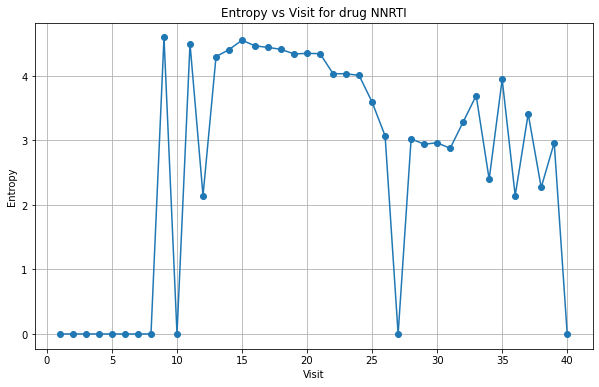

In [ ]:
def plot_entropies(file_name, drug, max_visit):
    entropies = []
    for visit in range(1, max_visit + 1):
        entropy = calculate_entropy(file_name, drug, visit)
        entropies.append(entropy)
    
    # Plotting
    plt.figure(figsize=(10,6))
    plt.plot(range(1, max_visit + 1), entropies, marker='o')
    plt.title(f"Entropy vs Visit for drug {drug}")
    plt.xlabel("Visit")
    plt.ylabel("Entropy")
    plt.grid()
    plt.show()

# Testing the function
plot_entropies('FinalBinedFull.xlsx', 'NNRTI', 40)

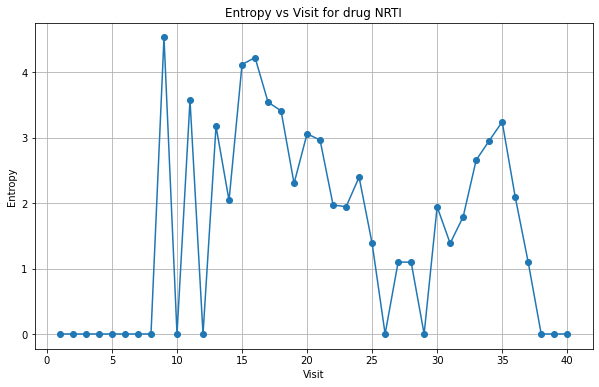

In [ ]:
# Testing the function
plot_entropies('NNRTI_NRTI_common_domain.xlsx', 'NRTI', 40)

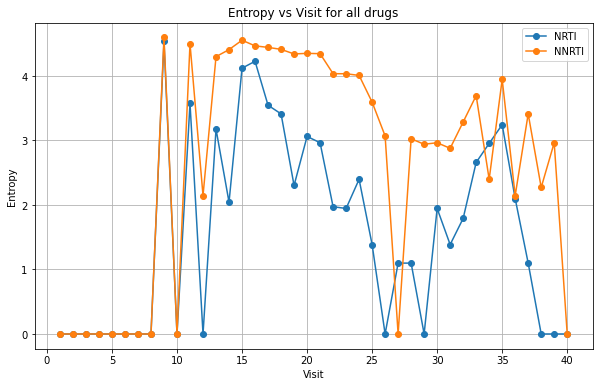

In [ ]:
def plot_all_entropies(file_name, drugs, max_visit):
    plt.figure(figsize=(10,6))

    for drug in drugs:
        entropies = []
        for visit in range(1, max_visit + 1):
            entropy = calculate_entropy(file_name, drug, visit)
            entropies.append(entropy)
    
        # Plotting
        plt.plot(range(1, max_visit + 1), entropies, marker='o', label=drug)
    
    plt.title(f"Entropy vs Visit for all drugs")
    plt.xlabel("Visit")
    plt.ylabel("Entropy")
    plt.legend()
    plt.grid()
    plt.show()

# Testing the function
plot_all_entropies('NNRTI_NRTI_common_domain.xlsx', ['NRTI', 'NNRTI'], 40)

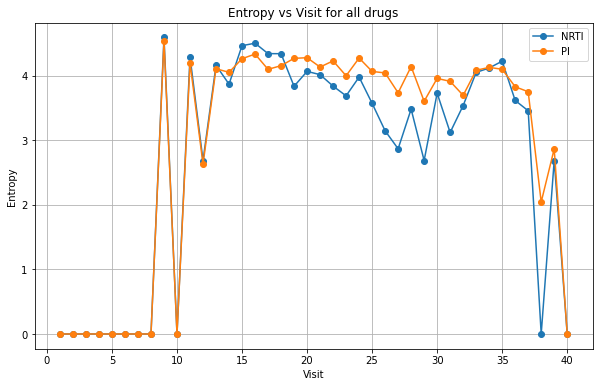

In [ ]:
plot_all_entropies('FinalBinedFull.xlsx', ['NRTI', 'PI'], 40)

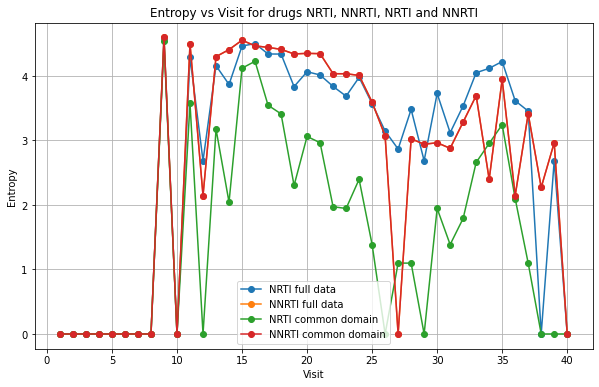

In [ ]:
def plot_four_entropies(file_name1, drug1, file_name2, drug2, file_name3, drug3, file_name4, drug4, max_visit):
    entropies1 = []
    entropies2 = []
    entropies3 = []
    entropies4 = []
    for visit in range(1, max_visit + 1):
        entropy1 = calculate_entropy(file_name1, drug1, visit)
        entropy2 = calculate_entropy(file_name2, drug2, visit)
        entropy3 = calculate_entropy(file_name3, drug3, visit)
        entropy4 = calculate_entropy(file_name4, drug4, visit)
        entropies1.append(entropy1)
        entropies2.append(entropy2)
        entropies3.append(entropy3)
        entropies4.append(entropy4)
    
    # Plotting
    plt.figure(figsize=(10,6))
    plt.plot(range(1, max_visit + 1), entropies1, marker='o', label="NRTI full data")
    plt.plot(range(1, max_visit + 1), entropies2, marker='o', label="NNRTI full data")
    plt.plot(range(1, max_visit + 1), entropies3, marker='o', label="NRTI common domain")
    plt.plot(range(1, max_visit + 1), entropies4, marker='o', label="NNRTI common domain")
    plt.title(f"Entropy vs Visit for drugs {drug1}, {drug2}, {drug3} and {drug4}")
    plt.xlabel("Visit")
    plt.ylabel("Entropy")
    plt.grid()
    plt.legend()
    plt.show()

# Testing the function
plot_four_entropies('FinalBinedFull.xlsx', 'NRTI', 'FinalBinedFull.xlsx', 'NNRTI', 'NNRTI_NRTI_common_domain.xlsx', 'NRTI', 'NNRTI_NRTI_common_domain.xlsx', 'NNRTI', 40)


In [55]:


def diff_files(full_file, common_file):
    # Load the xls file's Sheets as dataframes
    xls_full = pd.ExcelFile(full_file)
    xls_common = pd.ExcelFile(common_file)
    
    # Create an Excel writer object
    writer = pd.ExcelWriter('non_common_domain_NRTI_NNRTI.xlsx', engine='xlsxwriter')

    # For each sheet in the common file, extract the difference between the full file's sheet and the common file's sheet
    for sheet in xls_common.sheet_names:
        df_full = pd.read_excel(full_file, sheet_name=sheet)
        df_common = pd.read_excel(common_file, sheet_name=sheet)
        
        # Merge with indicator to find out which rows are only present in the full file
        merged = df_full.merge(df_common, indicator=True, how='outer')
        diff = merged[merged['_merge'] == 'left_only']
        
        # Drop the indicator column
        diff = diff.drop(columns=['_merge'])
        
        # Write the diff to the new Excel file
        diff.to_excel(writer, sheet_name=sheet, index=False)

    # Save the result
    writer.save()




In [59]:
# Use this function with your Excel files' names
diff_files('FinalBinedFull.xlsx', 'NNRTI_NRTI_common_domain.xlsx')

In [ ]:

def diff_files(full_file, common_file):
    # Load the xls file's Sheets as dataframes
    xls_full = pd.ExcelFile(full_file)
    xls_common = pd.ExcelFile(common_file)
    
    # Create an Excel writer object
    writer = pd.ExcelWriter('non_common_domain_NRTI_PI.xlsx', engine='xlsxwriter')

    # For each sheet in the common file, extract the difference between the full file's sheet and the common file's sheet
    for sheet in xls_common.sheet_names:
        df_full = pd.read_excel(full_file, sheet_name=sheet)
        df_common = pd.read_excel(common_file, sheet_name=sheet)
        
        # Merge with indicator to find out which rows are only present in the full file
        merged = df_full.merge(df_common, indicator=True, how='outer')
        diff = merged[merged['_merge'] == 'left_only']
        
        # Drop the indicator column
        diff = diff.drop(columns=['_merge'])
        
        # Write the diff to the new Excel file
        diff.to_excel(writer, sheet_name=sheet, index=False)

    # Save the result
    writer.save()


In [ ]:
# Use this function with your Excel files' names
diff_files('FinalBinedFull.xlsx', 'PI_NRTI_common_domain.xlsx')

In [ ]:

def diff_files(full_file, common_file):
    # Load the xls file's Sheets as dataframes
    xls_full = pd.ExcelFile(full_file)
    xls_common = pd.ExcelFile(common_file)
    
    # Create an Excel writer object
    writer = pd.ExcelWriter('non_common_domain_NNRTI_PI.xlsx', engine='xlsxwriter')

    # For each sheet in the common file, extract the difference between the full file's sheet and the common file's sheet
    for sheet in xls_common.sheet_names:
        df_full = pd.read_excel(full_file, sheet_name=sheet)
        df_common = pd.read_excel(common_file, sheet_name=sheet)
        
        # Merge with indicator to find out which rows are only present in the full file
        merged = df_full.merge(df_common, indicator=True, how='outer')
        diff = merged[merged['_merge'] == 'left_only']
        
        # Drop the indicator column
        diff = diff.drop(columns=['_merge'])
        
        # Write the diff to the new Excel file
        diff.to_excel(writer, sheet_name=sheet, index=False)

    # Save the result
    writer.save()

In [ ]:
# Use this function with your Excel files' names
diff_files('FinalBinedFull.xlsx', 'PI_NNRTI_common_domain.xlsx')

In [ ]:


def ratio_entropies(file1, drug1, file2, drug2, file3, drug3, file4, drug4, max_visit):
    diffH_common = []
    diffH_non_common = []
    
    # Calculate difference of entropies for first two files/drugs
    for visit in range(1, max_visit + 1):
        entropy1 = calculate_entropy(file1, drug1, visit)
        entropy2 = calculate_entropy(file2, drug2, visit)
        diffH_common.append((entropy1 - entropy2))
    
    # Calculate difference of entropies for second two files/drugs
    for visit in range(1, max_visit + 1):
        entropy3 = calculate_entropy(file3, drug3, visit)
        entropy4 = calculate_entropy(file4, drug4, visit)
        diffH_non_common.append(np.abs(entropy3 - entropy4))
    
    # Calculate ratio between the two differences
    ratioH = [i - j if j != 0 else 0 for i, j in zip(diffH_common, diffH_non_common)]
    
    # Plotting
    plt.figure(figsize=(10,6))
    plt.plot(range(1, max_visit + 1), ratioH, marker='o')
    plt.title(f"Difference of usable and non-usable information")
    plt.xlabel("Visit")
    plt.ylabel("R")
    #plt.ylim(0, 10)  # Set x-axis limits
    plt.grid()
    plt.show()

# Use this function with your files and drugs
#ratio_entropies('PI_NRTI_common_domain.xlsx', 'NRTI', 'PI_NRTI_common_domain.xlsx', 'PI', 'non_common_domain.xlsx', 'NRTI', 'non_common_domain.xlsx', 'PI', 40)


In [ ]:
ratio_entropies('NRTI_NNRTI_common_domain.xlsx', 'NRTI', 'NRTI_NNRTI_common_domain.xlsx', 'NNRTI', 'non_common_domain_NRTI_NNRTI.xlsx', 'NRTI', 'non_common_domain_NRTI_NNRTI.xlsx', 'NNRTI', 40)


TypeError: The axis argument to unique is not supported for dtype object

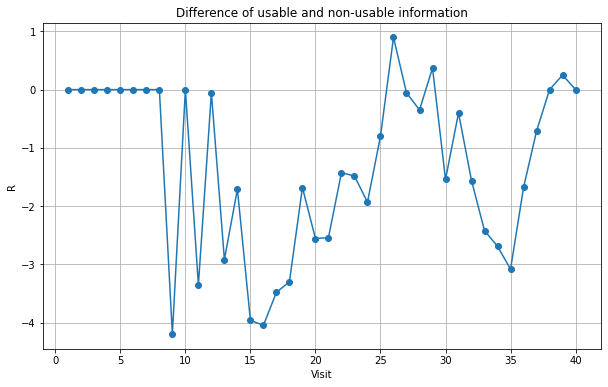

In [ ]:
ratio_entropies('PI_NRTI_common_domain.xlsx', 'PI', 'PI_NRTI_common_domain.xlsx', 'NRTI', 'non_common_domain_NRTI_PI.xlsx', 'PI', 'non_common_domain_NRTI_PI.xlsx', 'NRTI', 40)


In [ ]:
def split_data(file_name, sheet_count):
    # Load Excel file
    xls = pd.ExcelFile(file_name)

    # Process each sheet
    for sheet_name in xls.sheet_names:
        df = pd.read_excel(file_name, sheet_name=sheet_name)
        
        # Split data
        dfs = np.array_split(df, sheet_count)
        
        # Save to new Excel file
        writer = pd.ExcelWriter(f'{sheet_name}_split.xlsx', engine='xlsxwriter')
        
        for i, df_part in enumerate(dfs, start=1):
            df_part.to_excel(writer, sheet_name=f'Sheet_{i}', index=False)
        
        writer.save()

# Use this function with your Excel file's name
split_data('FinalBinedFull.xlsx', 10)


In [ ]:
def split_data(file_name, sheet_count):
    # Load Excel file
    xls = pd.ExcelFile(file_name)

    # Process each sheet
    for sheet_name in xls.sheet_names:
        df = pd.read_excel(file_name, sheet_name=sheet_name)
        
        # Split data
        dfs = np.array_split(df, sheet_count)
        
        # Save to new Excel file
        writer = pd.ExcelWriter(f'{sheet_name}_split_common.xlsx', engine='xlsxwriter')
        
        for i, df_part in enumerate(dfs, start=1):
            df_part.to_excel(writer, sheet_name=f'Sheet_{i}', index=False)
        
        writer.save()

# Use this function with your Excel file's name
split_data('PI_NRTI_common_domain.xlsx', 10)

In [ ]:
def split_data(file_name, sheet_count):
    # Load Excel file
    xls = pd.ExcelFile(file_name)

    # Process each sheet
    for sheet_name in xls.sheet_names:
        df = pd.read_excel(file_name, sheet_name=sheet_name)
        
        # Split data
        dfs = np.array_split(df, sheet_count)
        
        # Save to new Excel file
        writer = pd.ExcelWriter(f'{sheet_name}_split_non_common.xlsx', engine='xlsxwriter')
        
        for i, df_part in enumerate(dfs, start=1):
            df_part.to_excel(writer, sheet_name=f'Sheet_{i}', index=False)
        
        writer.save()

# Use this function with your Excel file's name
split_data('non_common_domain_NRTI_PI.xlsx', 10)

In [ ]:
import pandas as pd

#def calculate_common_domains(file_name1, file_name2, drug1, drug2, num_samples):
    # Create two new Excel writer objects
    writer1 = pd.ExcelWriter(f'{drug1}_common_domain_split.xlsx', engine='xlsxwriter')
    writer2 = pd.ExcelWriter(f'{drug2}_common_domain_split.xlsx', engine='xlsxwriter')

    for i in range(num_samples):
        # Load each pair of corresponding sheets as dataframes
        df1 = pd.read_excel(file_name1, sheet_name=f'Sheet_{i+1}')
        df2 = pd.read_excel(file_name2, sheet_name=f'Sheet_{i+1}')

        # Compute common domains and filter dataframes
        for j in range(2, df1.shape[1]):  # Assuming measurement columns start from index 2
            min_val = max(df1.iloc[:, j].min(), df2.iloc[:, j].min())
            max_val = min(df1.iloc[:, j].max(), df2.iloc[:, j].max())

            df1 = df1[(df1.iloc[:, j] >= min_val) & (df1.iloc[:, j] <= max_val)]
            df2 = df2[(df2.iloc[:, j] >= min_val) & (df2.iloc[:, j] <= max_val)]

        # Write filtered dataframes to new Excel files
        df1.to_excel(writer1, sheet_name=f'Sheet_{i+1}', index=False)
        df2.to_excel(writer2, sheet_name=f'Sheet_{i+1}', index=False)

    # Save the results
    writer1.save()
    writer2.save()

# Use this function with your files and drugs
calculate_common_domains('NNRTI_split.xlsx', 'NRTI_split.xlsx', 'NNRTI', 'NRTI', 10)


IndentationError: unexpected indent (3255403946.py, line 5)

In [ ]:


from scipy.stats import entropy
import pandas as pd
import numpy as np

def calculate_sheet_entropy(file_name, sheet_name):
    # Load the specific sheet from the excel file
    df = pd.read_excel(file_name, sheet_name=sheet_name)

    # Drop CASEID and VISIT columns
    df = df.drop(columns=['CASEID', 'VISIT'])

    # Find unique vectors (microstates) and their counts
    microstates, counts = np.unique(df.values, axis=0, return_counts=True)

    # Calculate probabilities
    probabilities = counts / counts.sum()

    # Calculate Shannon entropy
    entropy_val = -np.sum(probabilities * np.log(probabilities))

    return entropy_val



def ratio_entropies_histogram(file1, file2, file3, file4, max_visit):
    ratios = []
    xls1 = pd.ExcelFile(file1)
    xls2 = pd.ExcelFile(file2)
    xls3 = pd.ExcelFile(file3)
    xls4 = pd.ExcelFile(file4)

    # Iterate over all sheets in the files
    for sheet in xls1.sheet_names:
        diffH_common = []
        diffH_non_common = []

        # Calculate difference of entropies for each visit across the sheets
        for visit in range(1, max_visit + 1):
            entropy1 = calculate_sheet_entropy(file1,  sheet)
            entropy2 = calculate_sheet_entropy(file2,  sheet)
            diffH_common.append((entropy1 - entropy2))

        for visit in range(1, max_visit + 1):
            entropy3 = calculate_sheet_entropy(file3,  sheet)
            entropy4 = calculate_sheet_entropy(file4,  sheet)
            diffH_non_common.append(np.abs(entropy3 - entropy4))

        # Calculate ratio between the two differences for each visit
        ratioH = [i / j if j != 0 else 0 for i, j in zip(diffH_common, diffH_non_common)]

        ratios.extend(ratioH)

    # Create DataFrame with ratios
    df = pd.DataFrame(ratios, columns=["Entropy Difference Ratio"])

    # Write DataFrame to an Excel file
    df.to_excel("EntropyRatios.xlsx", index=False)

    # Plot histogram
    plt.figure(figsize=(10,6))
    plt.hist(ratios, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    plt.title("Histogram of Entropy Difference Ratios")
    #plt.ylim(0,15)
    plt.xlabel("Ratio of entropy differences")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()



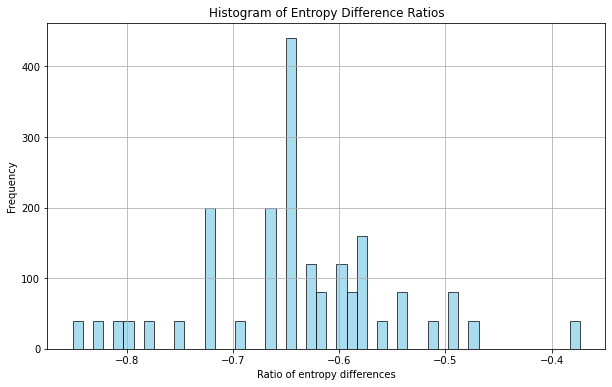

In [ ]:
ratio_entropies_histogram('NRTI_split_common.xlsx', 'NNRTI_split_common.xlsx', 'NRTI_split_non_common.xlsx', 'NNRTI_split_non_common.xlsx', 40)

In [ ]:
ratio_entropies_histogram('NRTI_split_common.xlsx', 'PI_split_common.xlsx', 'NRTI_split_non_common.xlsx', 'PI_split_non_common.xlsx', 40)

TypeError: The axis argument to unique is not supported for dtype object

In [ ]:
def calculate_stats(file_name):
    # Read the DataFrame from the Excel file
    df = pd.read_excel(file_name)

    # Filter out zero values and values higher than 5
    df = df[(df["Entropy Difference Ratio"] != 0) & (df["Entropy Difference Ratio"] <= 5)]

    # Calculate and print the average and standard deviation
    avg = df["Entropy Difference Ratio"].mean()
    std_dev = df["Entropy Difference Ratio"].std()

    return avg, std_dev



In [ ]:
avg, std_dev = calculate_stats("EntropyRatios.xlsx")
print(f"Average: {avg}, Standard Deviation: {std_dev}")


Average: -0.6384089927815111, Standard Deviation: 0.09153461577166228


In [ ]:


def remove_zeros(file_name, column_name):
    # Load the Excel file into a DataFrame
    df = pd.read_excel(file_name)

    # Remove rows with 0 in the specified column
    df = df[(df["Entropy Difference Ratio"] != 0) & (df["Entropy Difference Ratio"] <= 5)]

    # Write the resulting DataFrame to a new Excel file
    df.to_excel("updated_" + file_name, index=False)

# Call the function
remove_zeros('EntropyRatiosCleaned.xlsx', 'Entropy Difference Ratio')


In [ ]:
import pandas as pd

# Load your Excel file
df = pd.read_excel('EntropyRatios.xlsx')

# Drop duplicates
df_distinct = df.drop_duplicates()
 
# Save the result to a new Excel file
df_distinct.to_excel('distinct_values.xlsx', index=False)


In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial import distance
from scipy.stats import entropy

def jensen_shannon_divergence(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (entropy(_P, _M) + entropy(_Q, _M))

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Initialize an empty dictionary to store results
    jsd_dict = {}

    # Loop over all columns
    for col in df1.columns:
        if df1[col].dtype in ['float64', 'int64'] and df2[col].dtype in ['float64', 'int64']:
            # Compute histograms of the quantity for each drug
            hist1, bin_edges = np.histogram(df1[col], bins='auto', density=True)
            hist2, _ = np.histogram(df2[col], bins=bin_edges, density=True)

            # Compute and store the Jensen-Shannon divergence
            jsd_dict[col] = JSD(hist1, hist2)

    return jsd_dict

file_name = 'FinalBinedFull.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

jsd_dict = jensen_shannon_divergence(file_name, drug_name1, drug_name2)

for col, jsd in jsd_dict.items():
    print(f'The Jensen-Shannon divergence between the "{col}" distributions for "{drug_name1}" and "{drug_name2}" is {jsd}.')


The Jensen-Shannon divergence between the "CASEID" distributions for "NRTI" and "NNRTI" is 0.00243721662526973.
The Jensen-Shannon divergence between the "VISIT" distributions for "NRTI" and "NNRTI" is 0.048144246972435446.
The Jensen-Shannon divergence between the "VLOAD" distributions for "NRTI" and "NNRTI" is 0.03044679073821851.
The Jensen-Shannon divergence between the "LLQ_VL" distributions for "NRTI" and "NNRTI" is 0.009100057779568498.
The Jensen-Shannon divergence between the "HSRAT" distributions for "NRTI" and "NNRTI" is 0.002686876840069072.
The Jensen-Shannon divergence between the "SGOTLF" distributions for "NRTI" and "NNRTI" is 0.0230043251854481.
The Jensen-Shannon divergence between the "SGPTLF" distributions for "NRTI" and "NNRTI" is 0.02717352039702227.
The Jensen-Shannon divergence between the "PHOSLF" distributions for "NRTI" and "NNRTI" is 0.02206132150004155.
The Jensen-Shannon divergence between the "ALBULF" distributions for "NRTI" and "NNRTI" is 0.006650567925

In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial import distance
from scipy.stats import entropy

def jensen_shannon_divergence(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (entropy(_P, _M) + entropy(_Q, _M))

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Concatenate all columns into a single vector for each drug
    values1 = np.concatenate([df1[col].values for col in df1.columns if df1[col].dtype in ['float64', 'int64']])
    values2 = np.concatenate([df2[col].values for col in df2.columns if df2[col].dtype in ['float64', 'int64']])

    # Compute histograms of the quantity for each drug
    hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
    hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

    # Compute and return the Jensen-Shannon divergence
    return JSD(hist1, hist2)

file_name = 'FinalBinedFull.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

jsd = jensen_shannon_divergence(file_name, drug_name1, drug_name2)

print(f'The Jensen-Shannon divergence between the combined distributions for "{drug_name1}" and "{drug_name2}" is {jsd}.')


The Jensen-Shannon divergence between the combined distributions for "NRTI" and "NNRTI" is 0.07694700426004811.


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


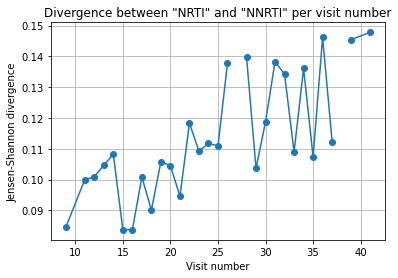

In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial import distance
from scipy.stats import entropy
import matplotlib.pyplot as plt

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (entropy(_P, _M) + entropy(_Q, _M))

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'NNRTI_NRTI_common_domain.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Divergence between "{drug_name1}" and "{drug_name2}" per visit number')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


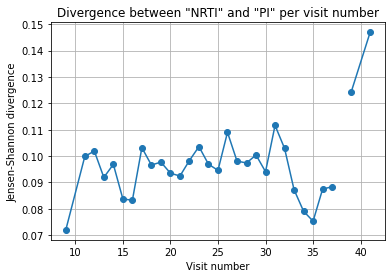

In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial import distance
from scipy.stats import entropy
import matplotlib.pyplot as plt

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (entropy(_P, _M) + entropy(_Q, _M))

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'PI_NRTI_common_domain.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Divergence between "{drug_name1}" and "{drug_name2}" per visit number')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


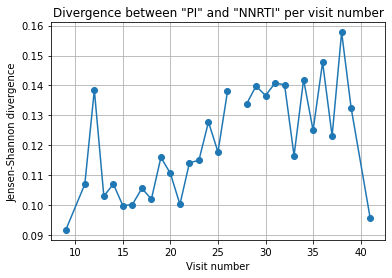

In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial import distance
from scipy.stats import entropy
import matplotlib.pyplot as plt

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (entropy(_P, _M) + entropy(_Q, _M))

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'PI_NNRTI_common_domain.xlsx'
drug_name1 = 'PI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Divergence between "{drug_name1}" and "{drug_name2}" per visit number')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


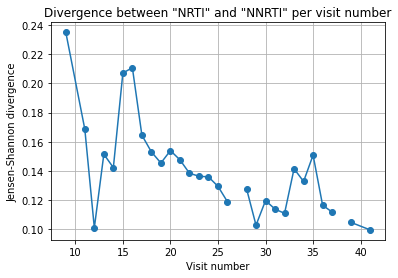

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'NNRTI_NRTI_common_domain.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Divergence between "{drug_name1}" and "{drug_name2}" per visit number')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


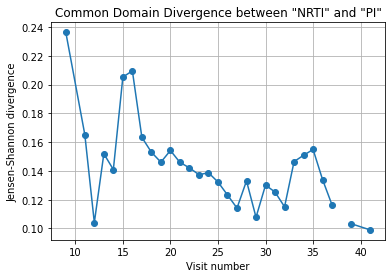

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'PI_NRTI_common_domain.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Common Domain Divergence between "{drug_name1}" and "{drug_name2}"')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


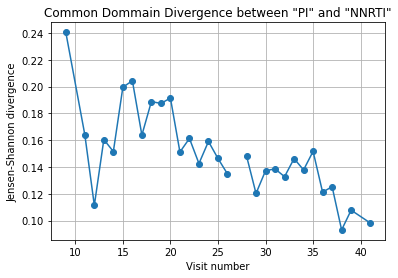

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'PI_NNRTI_common_domain.xlsx'
drug_name1 = 'PI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Common Dommain Divergence between "{drug_name1}" and "{drug_name2}"')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


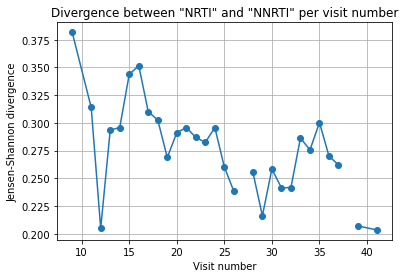

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'FinalBinedFull.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Divergence between "{drug_name1}" and "{drug_name2}" per visit number')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


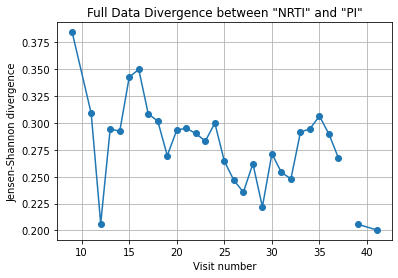

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'FinalBinedFull.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Full Data Divergence between "{drug_name1}" and "{drug_name2}"')
plt.grid(True)
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/lib/histograms.py:906: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


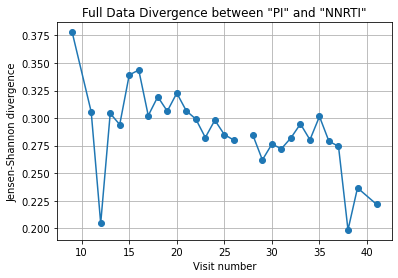

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
import matplotlib.pyplot as plt

def calculate_entropy(array):
    # Calculate probabilities
    probabilities = array / np.sum(array)

    # Add a small constant to avoid taking the log of zero
    probabilities = probabilities + 1e-10

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2):
    # Function to compute the Jensen-Shannon divergence
    def JSD(P, Q):
        _P = P / np.linalg.norm(P, ord=1)
        _Q = Q / np.linalg.norm(Q, ord=1)
        _M = 0.5 * (_P + _Q)
        return 0.5 * (calculate_entropy(_P) + calculate_entropy(_Q))*0.1

    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    visit_numbers = sorted(set(df1['VISIT'].unique()).union(df2['VISIT'].unique()))
    divergences = []

    for visit_number in visit_numbers:
        # Filter the data for the specific visit number
        visit_df1 = df1[df1['VISIT'] == visit_number]
        visit_df2 = df2[df2['VISIT'] == visit_number]

        # Concatenate all columns into a single vector for each drug
        values1 = np.concatenate([visit_df1[col].values for col in visit_df1.columns if visit_df1[col].dtype in ['float64', 'int64']])
        values2 = np.concatenate([visit_df2[col].values for col in visit_df2.columns if visit_df2[col].dtype in ['float64', 'int64']])

        # Compute histograms of the quantity for each drug
        hist1, bin_edges = np.histogram(values1, bins='auto', density=True)
        hist2, _ = np.histogram(values2, bins=bin_edges, density=True)

        # Compute and store the Jensen-Shannon divergence for this visit number
        divergences.append(JSD(hist1, hist2))

    return visit_numbers, divergences

file_name = 'FinalBinedFull.xlsx'
drug_name1 = 'PI'
drug_name2 = 'NNRTI'

visit_numbers, divergences = jensen_shannon_divergence_per_visit(file_name, drug_name1, drug_name2)

# Plot the divergence per visit number
plt.plot(visit_numbers, divergences, marker='o')
plt.xlabel('Visit number')
plt.ylabel('Jensen-Shannon divergence')
plt.title(f'Full Data Divergence between "{drug_name1}" and "{drug_name2}"')
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
import numpy as np

def normalize_file(file_name):
    # Open the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Initialize a writer for the new Excel file
        with pd.ExcelWriter(f'{file_name[:-5]}_normalised.xlsx') as writer:
            # Iterate over each sheet in the Excel file
            for sheet_name in xls.sheet_names:
                # Load the sheet to a DataFrame
                df = pd.read_excel(xls, sheet_name=sheet_name)
                
                # Get the measurement columns
                measurement_columns = df.select_dtypes(include=[np.number]).columns.tolist()
                non_measurement_columns = ['CASEID', 'VISIT']
                measurement_columns = [column for column in measurement_columns if column not in non_measurement_columns]
                
                # Normalize the measurement columns
                for column in measurement_columns:
                    df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
                
                # Write the normalized DataFrame to the new Excel file
                df.to_excel(writer, sheet_name=sheet_name, index=False)

file_name = 'FinalBinedFull.xlsx'
normalize_file(file_name)


In [ ]:
import pandas as pd
import numpy as np

def calculate_entropy(data):
    # Find unique microstates and their counts
    microstates, counts = np.unique(data.values, axis=0, return_counts=True)

    # Calculate probabilities
    probabilities = counts / counts.sum()

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def entropy_difference(file_name, drug, visit, num_groups):
    # Load the specific sheet (drug) from the excel file
    df = pd.read_excel(file_name, sheet_name=drug)

    # Filter data based on the visit
    df = df[df['VISIT'] == visit]

    # Drop unnecessary columns
    df = df.drop(columns=['CASEID', 'VISIT','VLOAD','LLQ_VL','HSRAT','SGOTLF','PHOSLF','ALBULF','BUN_LF','CREALF'])

    # Make sure that the number of rows is divisible by num_groups and each group has at least 8 patients
    num_rows = df.shape[0] // num_groups * num_groups
    df = df.iloc[:num_rows]

    # Split data into groups and calculate the entropy for each group
    group_entropies = []
    group_size = df.shape[0] // num_groups
    for i in range(num_groups):
        group_data = df.iloc[i*group_size:(i+1)*group_size]
        group_entropies.append(calculate_entropy(group_data))
    
    # Calculate the mean entropy of the groups
    mean_group_entropy = np.mean(group_entropies)

    # Calculate the entropy of the entire system
    system_entropy = calculate_entropy(df)

    # Calculate the difference
    diff = mean_group_entropy - system_entropy

    return diff

file_name = 'FinalBinedFull_normalised.xlsx'
drug = 'NRTI'
visit = 1
num_groups = 3

diff = entropy_difference(file_name, drug, visit, num_groups)
print(f'The difference between the mean group entropy and the system entropy for drug "{drug}" and visit {visit} is {diff}.')


The difference between the mean group entropy and the system entropy for drug "NRTI" and visit 1 is 0.0.


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/seaborn/distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


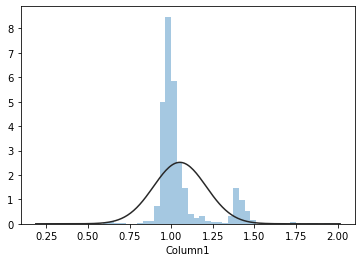

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

def plot_distribution(file_name, drug_name, visit):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1'
    data = df['Column1']

    # Fit a normal distribution to the data
    sns.distplot(data, kde=False, fit=stats.norm)

    # Show the plot
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 9

plot_distribution(file_name, drug_name, visit)


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

def get_distribution(file_name, drug_name, visit):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1' and drop any nan values
    data = df['Column1'].dropna()

    # Fit a normal distribution to the data
    mu, std = stats.norm.fit(data)

    # Return the pdf
    return stats.norm(loc=mu, scale=std).pdf

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 9

# Get the distribution
pdf = get_distribution(file_name, drug_name, visit)

# Now you can use the pdf for calculations. For example, to get the pdf value at x=0.5:
if pdf is not None:
    value = pdf(0.5)
    print(value)
else:
    print("No pdf available.")


0.005852197819150454


In [ ]:
def shannon_entropy(probabilities):
    # Convert the probabilities to a numpy array
    probabilities = np.array(probabilities)

    # Calculate the entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

def entropy_difference(file_name, drug_name, visit):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1'
    data = df['Column1']

    # Fit a normal distribution to the total data
    mu, std = stats.norm.fit(data)
    total_pdf = stats.norm(loc=mu, scale=std).pdf

    # Calculate the entropy of the total data
    total_entropy = shannon_entropy(total_pdf(data))

    # Split the data into 5 groups
    groups = np.array_split(data, 5)

    group_entropies = []
    for group in groups:
        # Fit a normal distribution to the group
        mu, std = stats.norm.fit(group)
        group_pdf = stats.norm(loc=mu, scale=std).pdf

        # Calculate the entropy of the group
        group_entropy = shannon_entropy(group_pdf(group))
        group_entropies.append(group_entropy)

    # Calculate the average entropy of the groups
    average_group_entropy = np.mean(group_entropies)

    # Calculate the absolute difference between the total entropy and the average group entropy
    difference = abs(total_entropy - average_group_entropy)

    return difference

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 9

difference = entropy_difference(file_name, drug_name, visit)
print(difference)


29878.484961954266


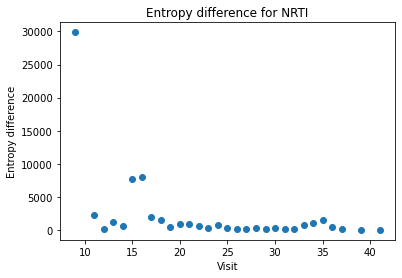

In [ ]:
import matplotlib.pyplot as plt

def plot_entropy_difference(file_name, drug_name):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Get all unique visit numbers
    visits = df['VISIT'].unique()

    differences = []
    for visit in visits:
        difference = entropy_difference(file_name, drug_name, visit)
        differences.append(difference)

    # Plot the entropy differences
    plt.scatter(visits, differences)
    plt.xlabel('Visit')
    plt.ylabel('Entropy difference')
    plt.title(f'Entropy difference for {drug_name}')
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'

plot_entropy_difference(file_name, drug_name)


In [ ]:
def calculate_internal_energy(file_name, drug_name, visit):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)

    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1'
    data = df['Column1']

    # Calculate the probability density function
    mu, std = stats.norm.fit(data)
    pdf = stats.norm.pdf(data, mu, std)

    # Calculate the internal energy
    internal_energy = np.sum(pdf * data)

    return internal_energy

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 5

internal_energy = calculate_internal_energy(file_name, drug_name, visit)

print(f'The internal energy for "{drug_name}" at visit {visit} is {internal_energy}.')


The internal energy for "NRTI" at visit 5 is 0.0.


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

def calculate_internal_energy_difference(file_name, drug_name, visit, num_groups=4):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)

    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1'
    data = df['Column1']

    # Calculate the internal energy for all the data
    mu, std = stats.norm.fit(data)
    pdf = stats.norm.pdf(data, mu, std)
    total_internal_energy = np.sum(pdf * data)

    # Divide the data into groups
    group_sizes = np.full(num_groups, len(data) // num_groups)
    group_sizes[:len(data) % num_groups] += 1
    groups = np.split(data, np.cumsum(group_sizes)[:-1])

    # Calculate the internal energy for each group and take the average
    group_internal_energies = []
    for group in groups:
        mu, std = stats.norm.fit(group)
        pdf = stats.norm.pdf(group, mu, std)
        group_internal_energy = np.sum(pdf * group)
        group_internal_energies.append(group_internal_energy)
    avg_group_internal_energy = np.mean(group_internal_energies)

    # Calculate the difference between the total internal energy and the average group internal energy
    internal_energy_difference = total_internal_energy - avg_group_internal_energy

    return internal_energy_difference

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 3

internal_energy_difference = calculate_internal_energy_difference(file_name, drug_name, visit)
print(f'The difference in internal energy for "{drug_name}" at visit {visit} is {internal_energy_difference}.')


The difference in internal energy for "NRTI" at visit 3 is 0.0.


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

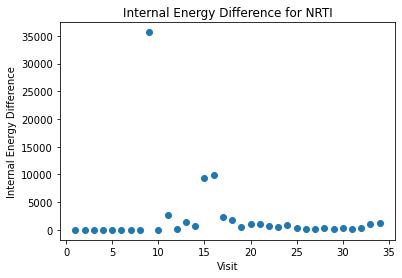

In [ ]:
import matplotlib.pyplot as plt

# Assume visits are from 1 to 10
visits = range(1, 35)
internal_energy_differences = []

for visit in visits:
    internal_energy_difference = calculate_internal_energy_difference(file_name, drug_name, visit)
    internal_energy_differences.append(internal_energy_difference)

plt.scatter(visits, internal_energy_differences)
plt.xlabel('Visit')
plt.ylabel('Internal Energy Difference')
plt.title(f'Internal Energy Difference for {drug_name}')
plt.show()


In [ ]:
def calculate_temperature(file_name, drug_name, visit, num_groups=5):
    # Calculate the difference in internal energies
    internal_energy_difference = calculate_internal_energy_difference(file_name, drug_name, visit, num_groups)

    # Calculate the difference in entropies
    entropy_difference_calc = entropy_difference(file_name, drug_name, visit)

    # Calculate the "temperature"
    temperature = internal_energy_difference / entropy_difference_calc

    return temperature

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 9

temperature = calculate_temperature(file_name, drug_name, visit)
print(f'The "temperature" for "{drug_name}" at visit {visit} is {temperature}.')


The "temperature" for "NRTI" at visit 9 is 1.2728622107983205.


In [ ]:
file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'
visit = 2
temperature = calculate_temperature(file_name, drug_name, visit)
print(f'The "temperature" for "{drug_name}" at visit {visit} is {temperature}.')

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())


The "temperature" for "NRTI" at visit 2 is nan.


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_12942/4050745284.py:9: RuntimeWarning: invalid value encountered in double_scalars
  temperature = internal_energy_difference / entropy_difference_calc


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

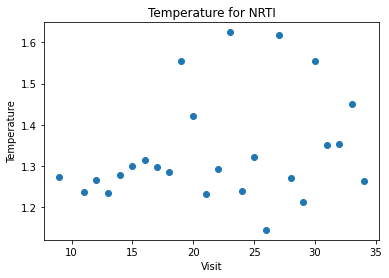

In [ ]:
# Assume visits are from 1 to 10
visits = range(9, 35)
temperatures = []

for visit in visits:
    temperature = calculate_temperature(file_name, drug_name, visit)
    temperatures.append(temperature)

plt.scatter(visits, temperatures)
plt.xlabel('Visit')
plt.ylabel('Temperature')
plt.title(f'Temperature for {drug_name}')
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

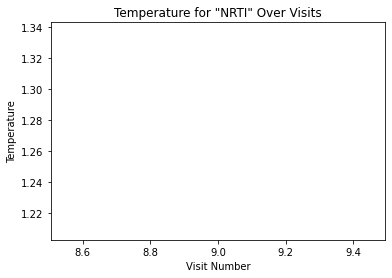

In [ ]:
import matplotlib.pyplot as plt

# Assuming the visits range from 1 to 10
visits = list(range(1, 11))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Create the plot
plt.plot(visits, temperatures)
plt.xlabel('Visit Number')
plt.ylabel('Temperature')
plt.title(f'Temperature for "{drug_name}" Over Visits')
plt.show()


In [74]:
import scipy.stats as stats

def calculate_probabilities1(file_name, drug_name, visit):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Filter rows for the given visit
    df = df[df['VISIT'] == visit]

    # Get the data in 'Column1'
    data = df['Column1']

    # Fit a normal distribution to the data
    mu, std = stats.norm.fit(data)

    # Calculate probabilities
    probabilities = stats.norm.pdf(data, mu, std)

    return probabilities


def shannon_entropy1(probabilities):
    # Convert the probabilities to a numpy array
    probabilities = np.array(probabilities)

    # Filter out zero probabilities to avoid log(0)
    probabilities = probabilities[probabilities > 0]

    # Calculate the entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

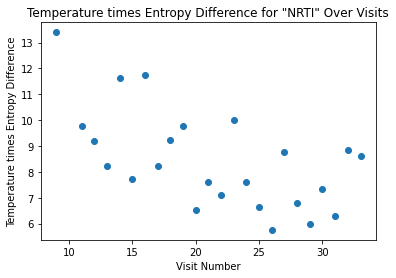

In [79]:
file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)])
)
# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Plot these products
plt.scatter(visits[:-1], products)
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

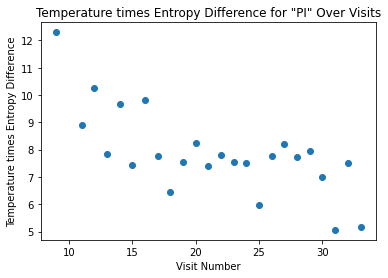

In [78]:
file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'PI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Plot these products
plt.scatter(visits[:-1], products)
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.show()

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_12942/2614383963.py:15: RuntimeWarning: divide by zero encountered in log
  entropies = np.log(np.abs([shannon_entropy(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.

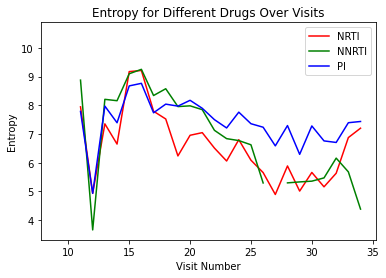

In [83]:
import matplotlib.pyplot as plt

# Assuming the visits range from 1 to 11
visits = list(range(9, 35))

# List of drug names
drug_names = ['NRTI', 'NNRTI', 'PI']

# Colors for each drug
colors = ['red', 'green', 'blue']

# Plot for each drug
for drug_name, color in zip(drug_names, colors):
    # Calculate entropy for each visit
    entropies = np.log(np.abs([shannon_entropy(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]
    ))
    # Plot these entropies
    plt.plot(visits, entropies, color=color, label=drug_name)

# Show the legend
plt.legend()

# Set labels and title
plt.xlabel('Visit Number')
plt.ylabel('Entropy')
plt.title('Entropy for Different Drugs Over Visits')

# Show the plot
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

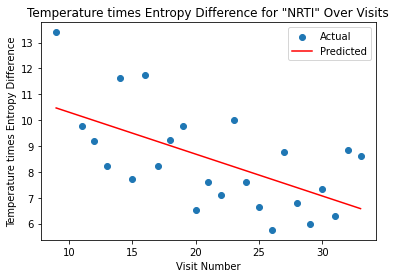

The mean squared error for the linear regression is 2.277644947330443.


In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
reg = LinearRegression().fit(visits_np.reshape(-1, 1), products_np)

# Predict the values using the linear regression model
predicted_products = reg.predict(visits_np.reshape(-1, 1))

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Plot these products
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

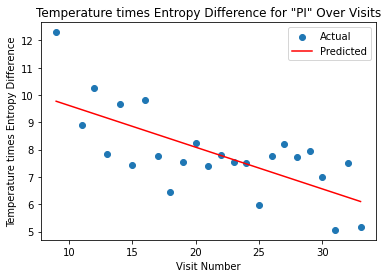

The mean squared error for the linear regression is 1.197297294691355.


In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'PI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
reg = LinearRegression().fit(visits_np.reshape(-1, 1), products_np)

# Predict the values using the linear regression model
predicted_products = reg.predict(visits_np.reshape(-1, 1))

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Plot these products
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.361
Model:                            OLS   Adj. R-squared:                  0.332
Method:                 Least Squares   F-statistic:                     12.43
Date:                Sat, 29 Jul 2023   Prob (F-statistic):            0.00190
Time:                        12:53:30   Log-Likelihood:                -43.932
No. Observations:                  24   AIC:                             91.86
Df Residuals:                      22   BIC:                             94.22
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.9328      1.038     11.492      0.0

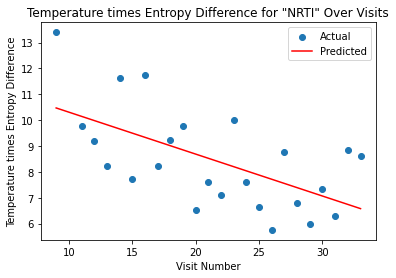

The mean squared error for the linear regression is 2.2776449473304434.


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns
import statsmodels.api as sm

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
X = sm.add_constant(visits_np)  # Adding constant for statsmodels
model = sm.OLS(products_np, X)
results = model.fit()

# Predict the values using the linear regression model
predicted_products = results.predict(X)

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Print the ANOVA table
print(results.summary())

# Plot these products
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.489
Model:                            OLS   Adj. R-squared:                  0.466
Method:                 Least Squares   F-statistic:                     21.05
Date:                Sat, 29 Jul 2023   Prob (F-statistic):           0.000144
Time:                        12:59:42   Log-Likelihood:                -36.215
No. Observations:                  24   AIC:                             76.43
Df Residuals:                      22   BIC:                             78.79
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.1503      0.753     14.811      0.0

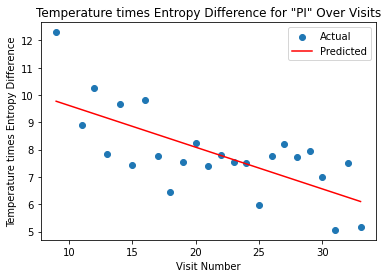

The mean squared error for the linear regression is 1.197297294691355.


In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns
import statsmodels.api as sm

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'PI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
X = sm.add_constant(visits_np)  # Adding constant for statsmodels
model = sm.OLS(products_np, X)
results = model.fit()

# Predict the values using the linear regression model
predicted_products = results.predict(X)

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Print the ANOVA table
print(results.summary())

# Plot these products
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.444
Model:                            OLS   Adj. R-squared:                  0.418
Method:                 Least Squares   F-statistic:                     16.80
Date:                Sat, 29 Jul 2023   Prob (F-statistic):           0.000513
Time:                        13:05:37   Log-Likelihood:                -50.457
No. Observations:                  23   AIC:                             104.9
Df Residuals:                      21   BIC:                             107.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         12.6052      1.503      8.389      0.0

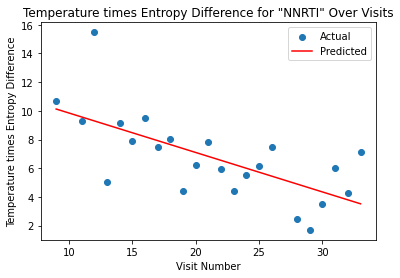

The mean squared error for the linear regression is 4.709808287671963.


In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns
import statsmodels.api as sm

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NNRTI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
X = sm.add_constant(visits_np)  # Adding constant for statsmodels
model = sm.OLS(products_np, X)
results = model.fit()

# Predict the values using the linear regression model
predicted_products = results.predict(X)

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Print the ANOVA table
print(results.summary())

# Plot these products
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


In [90]:
import pandas as pd

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Create a DataFrame
df = pd.DataFrame({
    'visit': visits,
    'entropy': entropies
})

# Output to a new Excel file
df.to_excel('entropy_vs_visit.xlsx', index=False)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

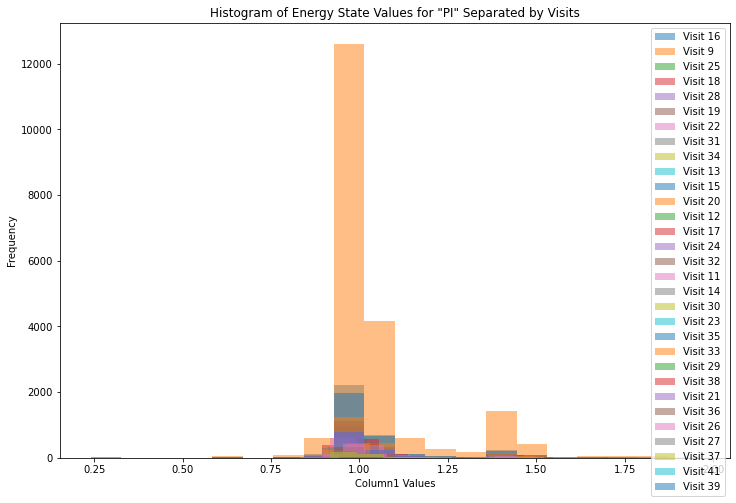

In [99]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_histogram(file_name, drug_name):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Get all unique visits
    unique_visits = df['VISIT'].unique()
    plt.figure(figsize=(12,8))
    # Plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit = df[df['VISIT'] == visit]

        # Get the data in 'Column1'
        data = (df_visit['Column1'])

        # Plot a histogram of the data
    
        plt.hist(data, bins=20, alpha=0.5, label=f'Visit {visit}')
    
    plt.xlabel('Column1 Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Energy State Values for "{drug_name}" Separated by Visits')
    plt.legend(loc='upper right')
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'PI'

plot_histogram(file_name, drug_name)


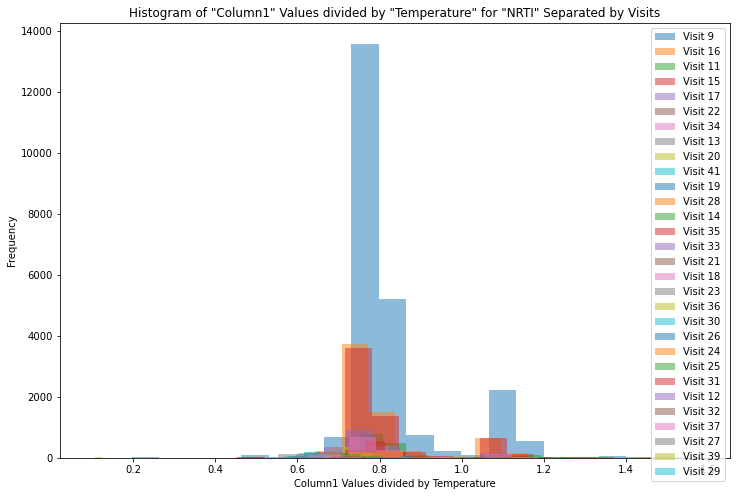

In [100]:
def plot_histogram_with_temperature(file_name, drug_name):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)
    
    # Get all unique visits
    unique_visits = df['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))  # You can adjust the numbers as per your preference

    # Plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit = df[df['VISIT'] == visit]

        # Get the data in 'Column1'
        data = df_visit['Column1']

        # Calculate the "temperature" for the visit
        temperature = calculate_temperature(file_name, drug_name, visit)

        # Divide the data by the "temperature"
        data_temperature = data / temperature

        # Plot a histogram of the data
        plt.hist(data_temperature, bins=20, alpha=0.5, label=f'Visit {visit}')

    plt.xlabel('Column1 Values divided by Temperature')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of "Column1" Values divided by "Temperature" for "{drug_name}" Separated by Visits')
    plt.legend(loc='upper right')
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'NRTI'

plot_histogram_with_temperature(file_name, drug_name)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/matplotlib/axes/_axes.py:6611: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/matplotlib/axes/_axes.py:6612: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


ValueError: autodetected range of [nan, nan] is not finite

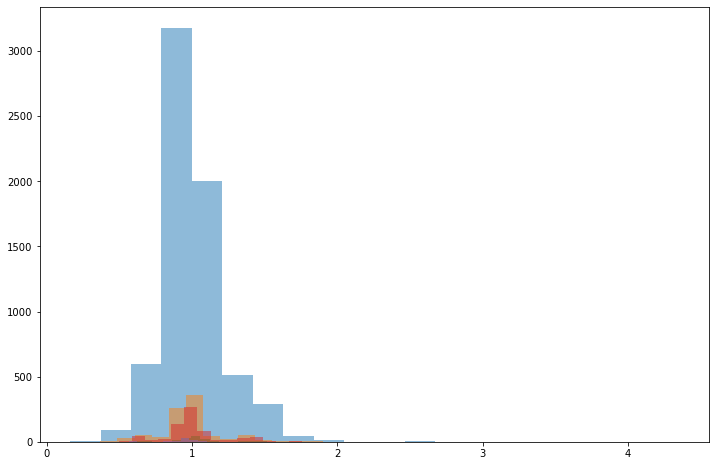

In [101]:
def plot_ratio_histogram(file_name, drug_name1, drug_name2):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get all unique visits
    unique_visits = df1['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))

    # Calculate the ratio and plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit1 = df1[df1['VISIT'] == visit]
        df_visit2 = df2[df2['VISIT'] == visit]

        # Get the data in 'Column1'
        data1 = df_visit1['Column1']
        data2 = df_visit2['Column1']

        # Calculate the "temperature" for the visit
        temperature1 = calculate_temperature(file_name, drug_name1, visit)
        temperature2 = calculate_temperature(file_name, drug_name2, visit)

        # Divide the data by the "temperature"
        ratio1 = data1 / temperature1
        ratio2 = data2 / temperature2

        # Calculate the ratio of the two datasets
        ratio = ratio1 / ratio2

        # Plot a histogram of the ratio
        plt.hist(ratio, bins=20, alpha=0.5, label=f'Visit {visit}')

    plt.xlabel('Ratio of (Column1/temperature) Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Ratio of (Column1/temperature) Values for "{drug_name1}" and "{drug_name2}"')
    plt.legend(loc='upper right')
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

plot_ratio_histogram(file_name, drug_name1, drug_name2)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

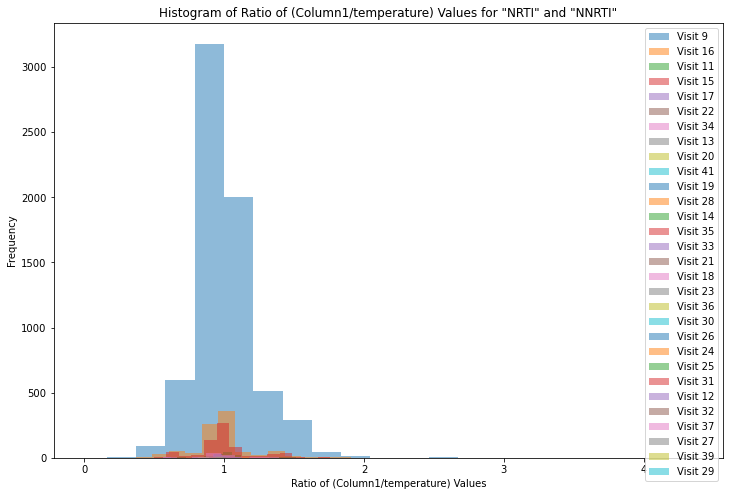

In [104]:
def plot_ratio_histogram(file_name, drug_name1, drug_name2, epsilon=1e-8):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get all unique visits
    unique_visits = df1['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))

    # Calculate the ratio and plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit1 = df1[df1['VISIT'] == visit]
        df_visit2 = df2[df2['VISIT'] == visit]

        # Ensure that 'Column1' does not contain NaN values
        data1 = df_visit1['Column1'].dropna()
        data2 = df_visit2['Column1'].dropna()

        # Calculate the "temperature" for the visit
        temperature1 = calculate_temperature(file_name, drug_name1, visit) + epsilon
        temperature2 = calculate_temperature(file_name, drug_name2, visit) + epsilon

        # Divide the data by the "temperature"
        ratio1 = data1 / temperature1
        ratio2 = data2 / temperature2

        # Calculate the ratio of the two datasets
        ratio = ratio1 / ratio2

        # Remove any infinities or NaNs
        ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()

        # Plot a histogram of the ratio
        plt.hist(ratio, bins=20, alpha=0.5, label=f'Visit {visit}')

    plt.xlabel('Ratio of (Column1/temperature) Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Ratio of (Column1/temperature) Values for "{drug_name1}" and "{drug_name2}"')
    plt.legend(loc='upper right')
    plt.show()

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

plot_ratio_histogram(file_name, drug_name1, drug_name2)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

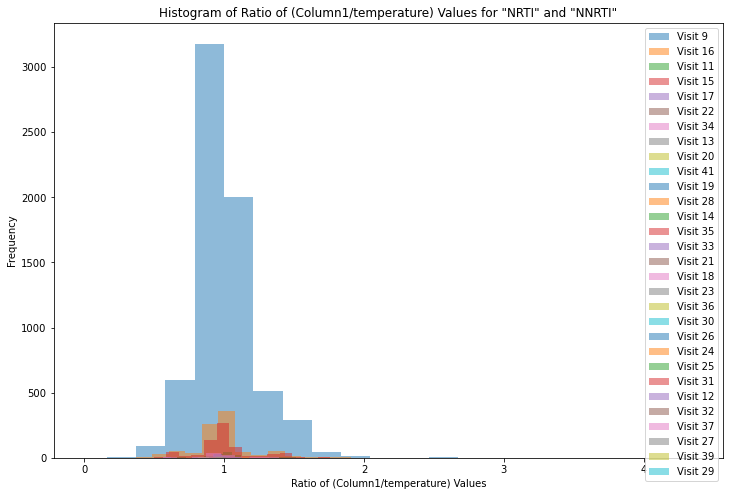

In [108]:
def plot_ratio_histogram(file_name, drug_name1, drug_name2, epsilon=1e-8):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get all unique visits
    unique_visits = df1['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))

    # Create a DataFrame to store the output values
    output_df = pd.DataFrame()

    # Calculate the ratio and plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit1 = df1[df1['VISIT'] == visit]
        df_visit2 = df2[df2['VISIT'] == visit]

        # Ensure that 'Column1' does not contain NaN values
        data1 = df_visit1['Column1'].dropna()
        data2 = df_visit2['Column1'].dropna()

        # Calculate the "temperature" for the visit
        temperature1 = calculate_temperature(file_name, drug_name1, visit) + epsilon
        temperature2 = calculate_temperature(file_name, drug_name2, visit) + epsilon

        # Divide the data by the "temperature"
        ratio1 = data1 / temperature1
        ratio2 = data2 / temperature2

        # Calculate the ratio of the two datasets
        ratio = ratio1 / ratio2

        # Remove any infinities or NaNs
        ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()

        # Add the output values to the DataFrame
        output_df = pd.concat([output_df, pd.DataFrame({
            'VISIT': visit,
            f'Column1/Temp_{drug_name1}': ratio1,
            f'Column1/Temp_{drug_name2}': ratio2,
            'Ratio': ratio
        })], ignore_index=True)

        # Plot a histogram of the ratio
        plt.hist(ratio, bins=20, alpha=0.5, label=f'Visit {visit}')

    plt.xlabel('Ratio of (Column1/temperature) Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Ratio of (Column1/temperature) Values for "{drug_name1}" and "{drug_name2}"')
    plt.legend(loc='upper right')
    plt.show()

    # Write the DataFrame to an Excel file
    output_df.to_excel("OutputValues.xlsx", index=False)

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

plot_ratio_histogram(file_name, drug_name1, drug_name2)


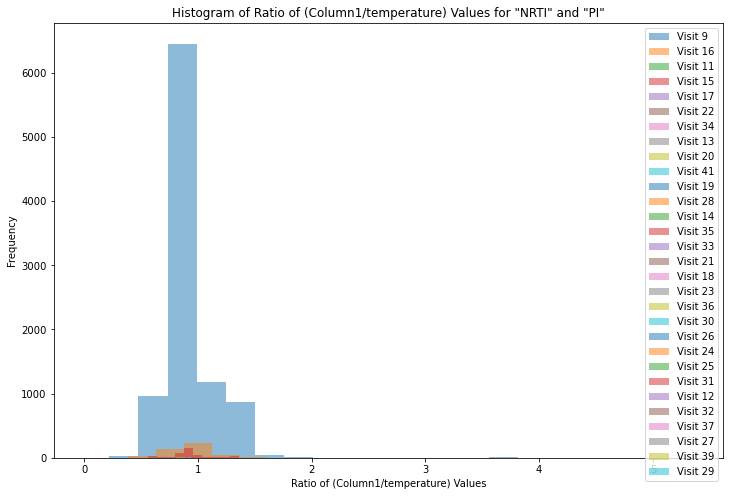

In [109]:
def plot_ratio_histogram(file_name, drug_name1, drug_name2, epsilon=1e-8):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get all unique visits
    unique_visits = df1['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))

    # Create a DataFrame to store the output values
    output_df = pd.DataFrame()

    # Calculate the ratio and plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit1 = df1[df1['VISIT'] == visit]
        df_visit2 = df2[df2['VISIT'] == visit]

        # Ensure that 'Column1' does not contain NaN values
        data1 = df_visit1['Column1'].dropna()
        data2 = df_visit2['Column1'].dropna()

        # Calculate the "temperature" for the visit
        temperature1 = calculate_temperature(file_name, drug_name1, visit) + epsilon
        temperature2 = calculate_temperature(file_name, drug_name2, visit) + epsilon

        # Divide the data by the "temperature"
        ratio1 = data1 / temperature1
        ratio2 = data2 / temperature2

        # Calculate the ratio of the two datasets
        ratio = ratio1 / ratio2

        # Remove any infinities or NaNs
        ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()

        # Add the output values to the DataFrame
        output_df = pd.concat([output_df, pd.DataFrame({
            'VISIT': visit,
            f'Column1/Temp_{drug_name1}': ratio1,
            f'Column1/Temp_{drug_name2}': ratio2,
            'Ratio': ratio
        })], ignore_index=True)

        # Plot a histogram of the ratio
        plt.hist(ratio, bins=20, alpha=0.5, label=f'Visit {visit}')

    plt.xlabel('Ratio of (Column1/temperature) Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Ratio of (Column1/temperature) Values for "{drug_name1}" and "{drug_name2}"')
    plt.legend(loc='upper right')
    plt.show()

    # Write the DataFrame to an Excel file
    output_df.to_excel("OutputValuesNRTI_PI.xlsx", index=False)

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

plot_ratio_histogram(file_name, drug_name1, drug_name2)


In [111]:
def average_values_and_ratios(input_file, ratio_file, drug_name):
    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name
        df = pd.read_excel(xls, sheet_name=drug_name)

    # Load the ratio file
    ratio_df = pd.read_excel(ratio_file)

    # Get the measurement columns
    measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

    # Average out the measurement values for each visit
    averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

    # Average out the ratios for each visit
    ratio_df = ratio_df.groupby('VISIT')['Ratio'].mean().reset_index()

    # Merge the two DataFrames on the 'VISIT' column
    final_df = pd.merge(averaged_df, ratio_df, on='VISIT')

    # Write the DataFrame to a new Excel file
    final_df.to_excel("AveragedValuesAndRatios.xlsx", index=False)

input_file = 'FinalBinedFull.xlsx'
ratio_file = 'OutputValuesNRTI_PI.xlsx'
drug_name = 'NRTI'

average_values_and_ratios(input_file, ratio_file, drug_name)


In [112]:
def calculate_average_measurement_ratios(input_file, ratio_file, drug_name1, drug_name2):
    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for both drugs
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Load the ratio file
    ratio_df = pd.read_excel(ratio_file)

    # Get the measurement columns
    measurement_columns = [col for col in df1.columns if col not in ['VISIT', 'CASEID']]

    # Average out the measurement values for each visit for both drugs
    averaged_df1 = df1.groupby('VISIT')[measurement_columns].mean().reset_index()
    averaged_df2 = df2.groupby('VISIT')[measurement_columns].mean().reset_index()

    # Calculate the ratio of the averaged measurements
    ratio_df_measurements = averaged_df1.copy()
    for col in measurement_columns:
        ratio_df_measurements[col] = averaged_df1[col] / averaged_df2[col]

    # Average out the ratios for each visit
    ratio_df = ratio_df.groupby('VISIT')['Ratio'].mean().reset_index()

    # Merge the two DataFrames on the 'VISIT' column
    final_df = pd.merge(ratio_df_measurements, ratio_df, on='VISIT')

    # Write the DataFrame to a new Excel file
    final_df.to_excel("AveragedMeasurementRatios.xlsx", index=False)

input_file = 'FinalBinedFull.xlsx'
ratio_file = 'OutputValuesNRTI_PI.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

calculate_average_measurement_ratios(input_file, ratio_file, drug_name1, drug_name2)


KeyboardInterrupt: 

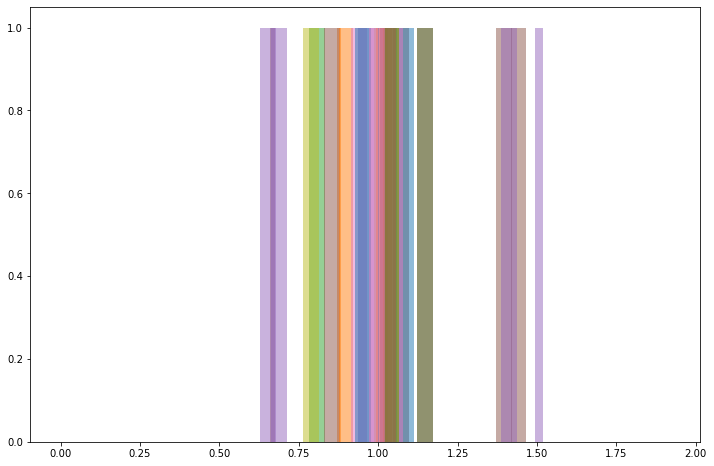

In [113]:
def plot_ratio_histogram(file_name, drug_name1, drug_name2, epsilon=1e-8):
    # Load the Excel file
    with pd.ExcelFile(file_name) as xls:
        # Load the sheets to DataFrames by name
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get all unique visits
    unique_visits = df1['VISIT'].unique()

    # Set the figure size
    plt.figure(figsize=(12, 8))

    # Create a DataFrame to store the output values
    output_df = pd.DataFrame()

    # Calculate the ratio and plot a histogram for each visit
    for visit in unique_visits:
        # Filter rows for the given visit
        df_visit1 = df1[df1['VISIT'] == visit]
        df_visit2 = df2[df2['VISIT'] == visit]

        # Get all unique caseids
        unique_caseids = df_visit1['CASEID'].unique()

        for caseid in unique_caseids:
            # Filter rows for the given caseid
            df_caseid1 = df_visit1[df_visit1['CASEID'] == caseid]
            df_caseid2 = df_visit2[df_visit2['CASEID'] == caseid]

            # Ensure that 'Column1' does not contain NaN values
            data1 = df_caseid1['Column1'].dropna()
            data2 = df_caseid2['Column1'].dropna()

            # Calculate the "temperature" for the visit
            temperature1 = calculate_temperature(file_name, drug_name1, visit) + epsilon
            temperature2 = calculate_temperature(file_name, drug_name2, visit) + epsilon

            # Divide the data by the "temperature"
            ratio1 = data1 / temperature1
            ratio2 = data2 / temperature2

            # Calculate the ratio of the two datasets
            ratio = ratio1 / ratio2

            # Remove any infinities or NaNs
            ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()

            # Add the output values to the DataFrame
            output_df = pd.concat([output_df, pd.DataFrame({
                'VISIT': visit,
                'CASEID': caseid,
                f'Column1/Temp_{drug_name1}': ratio1,
                f'Column1/Temp_{drug_name2}': ratio2,
                'Ratio': ratio
            })], ignore_index=True)

            # Plot a histogram of the ratio
            plt.hist(ratio, bins=20, alpha=0.5, label=f'Visit {visit}, CASEID {caseid}')

    plt.xlabel('Ratio of (Column1/temperature) Values')
    plt.ylabel('Frequency')
    plt.title(f'Histogram of Ratio of (Column1/temperature) Values for "{drug_name1}" and "{drug_name2}"')
    plt.legend(loc='upper right')
    plt.show()

    # Write the DataFrame to an Excel file
    output_df.to_excel("OutputValueswithCASEID.xlsx", index=False)

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'NNRTI'

plot_ratio_histogram(file_name, drug_name1, drug_name2)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

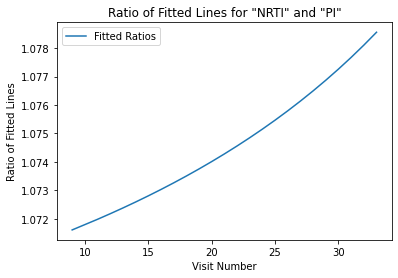

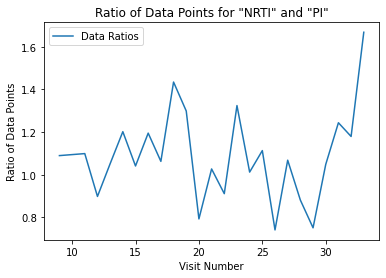

In [114]:
def calculate_products(file_name, drug_name):
    # Assuming the visits range from 9 to 34
    visits = list(range(9, 35))

    # Calculate temperature for each visit
    temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

    # Calculate entropy for each visit
    entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

    # Calculate difference in entropy for each pair of consecutive visits
    entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

    # Calculate the product of temperature and entropy difference for each visit
    products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

    # Convert products to a numpy array
    products_np = np.array(products)

    # Get indices where products_np is neither NaN nor infinity
    indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

    # Get the visits and products where products is neither NaN nor infinity
    visits_np = np.array(visits[:-1])[indices]
    products_np = products_np[indices]

    # Fit a linear regression model
    X = sm.add_constant(visits_np)  # Adding constant for statsmodels
    model = sm.OLS(products_np, X)
    results = model.fit()

    # Predict the values using the linear regression model
    predicted_products = results.predict(X)

    return visits_np, products_np, predicted_products, results

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

# Calculate products for each drug
visits1, products1, predicted_products1, results1 = calculate_products(file_name, drug_name1)
visits2, products2, predicted_products2, results2 = calculate_products(file_name, drug_name2)

# Calculate ratios of fitted lines and data points
fitted_ratios = predicted_products1 / predicted_products2
data_ratios = products1 / products2

# Plot ratio of fitted lines
plt.plot(visits1, fitted_ratios, label='Fitted Ratios')
plt.xlabel('Visit Number')
plt.ylabel('Ratio of Fitted Lines')
plt.title(f'Ratio of Fitted Lines for "{drug_name1}" and "{drug_name2}"')
plt.legend()
plt.show()

# Plot ratio of data points
plt.plot(visits1, data_ratios, label='Data Ratios')
plt.xlabel('Visit Number')
plt.ylabel('Ratio of Data Points')
plt.title(f'Ratio of Data Points for "{drug_name1}" and "{drug_name2}"')
plt.legend()
plt.show()

# Create a DataFrame to store the results
df = pd.DataFrame({
    'VISIT': visits1,
    f'Product_{drug_name1}': products1,
    f'Product_{drug_name2}': products2,
    'Fitted_Ratio': fitted_ratios,
    'Data_Ratio': data_ratios
})

# Write the DataFrame to an Excel file
df.to_excel("HeatRatios.xlsx", index=False)


In [118]:
def calculate_average_measurement_products(input_file, drug_name1, drug_name2):
    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for both drugs
        df1 = pd.read_excel(xls, sheet_name=drug_name1)
        df2 = pd.read_excel(xls, sheet_name=drug_name2)

    # Get the measurement columns
    measurement_columns = [col for col in df1.columns if col not in ['VISIT', 'CASEID']]

    # Average out the measurement values for each visit for both drugs
    averaged_df1 = df1.groupby('VISIT')[measurement_columns].mean().reset_index()
    averaged_df2 = df2.groupby('VISIT')[measurement_columns].mean().reset_index()

    # Calculate the product of temperature and entropy difference for each drug
    def calculate_products(df, drug_name):
        # Get the unique visits from the dataframe
        visits = sorted(df['VISIT'].unique())

        # Calculate temperature for each visit
        temperatures = [calculate_temperature(input_file, drug_name, visit) for visit in visits]

        # Calculate entropy for each visit
        entropies = [shannon_entropy1(calculate_probabilities1(input_file, drug_name, visit)) for visit in visits]

        # Calculate difference in entropy for each pair of consecutive visits
        entropy_differences = [np.log(np.abs(entropies[i+1] - entropies[i])) if i < len(entropies) - 1 else np.nan for i in range(len(entropies))]

        # Calculate the product of temperature and entropy difference for each visit
        products = [temperatures[i] * entropy_differences[i] if i < len(temperatures) - 1 else np.nan for i in range(len(temperatures))]

        return products

    products1 = calculate_products(df1, drug_name1)
    products2 = calculate_products(df2, drug_name2)

    # Add the products as a new column to the averaged DataFrames
    averaged_df1['Product'] = products1
    averaged_df2['Product'] = products2

    # Write the DataFrames to new sheets in an Excel file
    with pd.ExcelWriter("AveragedMeasurementProducts.xlsx") as writer:  
        averaged_df1.to_excel(writer, sheet_name=drug_name1, index=False)
        averaged_df2.to_excel(writer, sheet_name=drug_name2, index=False)

input_file = 'FinalBinedFull_normalised.xlsx'
drug_name1 = 'NRTI'
drug_name2 = 'PI'

calculate_average_measurement_products(input_file, drug_name1, drug_name2)


In [123]:
import os

def calculate_average_measurement_products(input_file, drug_names):
    # Check if the output file exists and delete it if it does
    if os.path.exists("AveragedMeasurementProducts.xlsx"):
        os.remove("AveragedMeasurementProducts.xlsx")

    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for each drug and store the dataframes
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    for i, (df, drug_name) in enumerate(zip(dfs, drug_names)):
        # Get the measurement columns
        measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

        # Average out the measurement values for each visit for the drug
        averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

        # Calculate the product of temperature and entropy difference for the drug
        def calculate_products(df, drug_name):
            # Get the unique visits from the dataframe
            visits = sorted(df['VISIT'].unique())

            # Calculate temperature for each visit
            temperatures = [calculate_temperature(input_file, drug_name, visit) for visit in visits]

            # Calculate entropy for each visit
            entropies = [shannon_entropy1(calculate_probabilities1(input_file, drug_name, visit)) for visit in visits]

            # Calculate difference in entropy for each pair of consecutive visits
            entropy_differences = [np.log(np.abs(entropies[i+1] - entropies[i])) if i < len(entropies) - 1 else np.nan for i in range(len(entropies))]

            # Calculate the product of temperature and entropy difference for each visit
            products = [temperatures[i] * entropy_differences[i] if i < len(temperatures) - 1 else np.nan for i in range(len(temperatures))]

            return products

        products = calculate_products(df, drug_name)

        # Add the products as a new column to the averaged DataFrame
        averaged_df['Product'] = products

        # Write the DataFrame to a new sheet in an Excel file
        mode = 'w' if i == 0 else 'a'
        with pd.ExcelWriter("AveragedMeasurementProducts.xlsx", mode=mode, engine='openpyxl') as writer:  
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'FinalBinedFull_normalised.xlsx'
drug_names = ['NRTI', 'PI', 'NNRTI']

calculate_average_measurement_products(input_file, drug_names)


In [124]:
import os

def calculate_average_measurement_products(input_file, drug_names):
    # Check if the output file exists and delete it if it does
    if os.path.exists("AveragedMeasurementProducts.xlsx"):
        os.remove("AveragedMeasurementProducts.xlsx")

    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for each drug and store the dataframes
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    # Write the DataFrame to a new sheet in an Excel file
    with pd.ExcelWriter("AveragedMeasurementProducts.xlsx", engine='openpyxl') as writer: 
        for i, (df, drug_name) in enumerate(zip(dfs, drug_names)):
            # Get the measurement columns
            measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

            # Average out the measurement values for each visit for the drug
            averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

            # Calculate the product of temperature and entropy difference for the drug
            def calculate_products(df, drug_name):
                # Get the unique visits from the dataframe
                visits = sorted(df['VISIT'].unique())

                # Calculate temperature for each visit
                temperatures = [calculate_temperature(input_file, drug_name, visit) for visit in visits]

                # Calculate entropy for each visit
                entropies = [shannon_entropy1(calculate_probabilities1(input_file, drug_name, visit)) for visit in visits]

                # Calculate difference in entropy for each pair of consecutive visits
                entropy_differences = [np.log(np.abs(entropies[i+1] - entropies[i])) if i < len(entropies) - 1 else np.nan for i in range(len(entropies))]

                # Calculate the product of temperature and entropy difference for each visit
                products = [temperatures[i] * entropy_differences[i] if i < len(temperatures) - 1 else np.nan for i in range(len(temperatures))]

                return products

            products = calculate_products(df, drug_name)

            # Add the products as a new column to the averaged DataFrame
            averaged_df['Product'] = products

            # Write each DataFrame to a separate sheet
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'FinalBinedFull_normalised.xlsx'
drug_names = ['NRTI', 'PI', 'NNRTI']

calculate_average_measurement_products(input_file, drug_names)


Exception ignored in: <function ZipFile.__del__ at 0x10484ce50>
Traceback (most recent call last):
  File "/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/zipfile.py", line 1814, in __del__
    def __del__(self):
KeyboardInterrupt: 


KeyboardInterrupt: 

In [125]:
import os

def calculate_average_measurement_products(input_file, drug_names):
    # Check if the output file exists and delete it if it does
    if os.path.exists("AveragedMeasurementProducts3.xlsx"):
        os.remove("AveragedMeasurementProducts3.xlsx")

    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for each drug and store the dataframes
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    # Write the DataFrame to a new sheet in an Excel file
    with pd.ExcelWriter("AveragedMeasurementProducts3.xlsx", engine='openpyxl') as writer: 
        for i, (df, drug_name) in enumerate(zip(dfs, drug_names)):
            # Get the measurement columns
            measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

            # Average out the measurement values for each visit for the drug
            averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

            # Calculate the product of temperature and entropy difference for the drug
            def calculate_products(df, drug_name):
                # Get the unique visits from the dataframe
                visits = sorted(df['VISIT'].unique())

                # Calculate temperature for each visit
                temperatures = [calculate_temperature(input_file, drug_name, visit) for visit in visits]

                # Calculate entropy for each visit
                entropies = [shannon_entropy1(calculate_probabilities1(input_file, drug_name, visit)) for visit in visits]

                # Calculate difference in entropy for each pair of consecutive visits
                entropy_differences = [np.log(np.abs(entropies[i+1] - entropies[i])) if i < len(entropies) - 1 else np.nan for i in range(len(entropies))]

                # Calculate the product of temperature and entropy difference for each visit
                products = [temperatures[i] * entropy_differences[i] if i < len(temperatures) - 1 else np.nan for i in range(len(temperatures))]

                return products, entropies

            products, entropies = calculate_products(df, drug_name)

            # Add the products and entropies as new columns to the averaged DataFrame
            averaged_df['Product'] = products
            averaged_df['Entropy'] = entropies

            # Write each DataFrame to a separate sheet
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'FinalBinedFull_normalised.xlsx'
drug_names = ['NRTI', 'PI', 'NNRTI']

calculate_average_measurement_products(input_file, drug_names)


In [127]:
import os
import numpy as np
import pandas as pd



def calculate_average_measurement_products(input_file, drug_names):
    # Check if the output file exists and delete it if it does
    if os.path.exists("AveragedMeasurementProducts01.xlsx"):
        os.remove("AveragedMeasurementProducts01.xlsx")

    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for each drug and store the dataframes
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    # Write the DataFrame to a new sheet in an Excel file
    with pd.ExcelWriter("AveragedMeasurementProducts01.xlsx", engine='openpyxl') as writer: 
        for i, (df, drug_name) in enumerate(zip(dfs, drug_names)):
            # Get the measurement columns
            measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

            # Average out the measurement values for each visit for the drug
            averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

            # Calculate entropy and temperature for each visit
            visits = averaged_df['VISIT']
            entropies = [calculate_entropy1(df, visit) for visit in visits]
            temperatures = [calculate_temperature(df, visit) for visit in visits]

            # Calculate the entropy difference and temperature product
            entropy_differences = [np.nan] + [entropies[i] - entropies[i-1] for i in range(1, len(entropies))]
            entropy_temperature_products = [np.nan] + [(entropies[i] - entropies[i-1])/temperatures[i] for i in range(1, len(entropies))]

            # Add the entropy, temperature, and product as new columns to the averaged DataFrame
            averaged_df['Entropy'] = entropies
            averaged_df['Temperature'] = temperatures
            averaged_df['EntropyTempProduct'] = entropy_temperature_products

            # Write each DataFrame to a separate sheet
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'FinalBinedFull_normalised.xlsx'
drug_names = ['NRTI', 'PI', 'NNRTI']

calculate_average_measurement_products(input_file, drug_names)


IndexError: At least one sheet must be visible

In [132]:
def calculate_average_measurement_products(input_file, drug_names):
    # Check if the output file exists and delete it if it does
    if os.path.exists("AveragedMeasurementProducts_denorm.xlsx"):
        os.remove("AveragedMeasurementProducts_denorm.xlsx")

    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Load the sheet to a DataFrame by name for each drug and store the dataframes
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    # Write the DataFrame to a new sheet in an Excel file
    with pd.ExcelWriter("AveragedMeasurementProducts_denorm.xlsx", engine='openpyxl') as writer: 
        for i, (df, drug_name) in enumerate(zip(dfs, drug_names)):
            # Get the measurement columns
            measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

            # Average out the measurement values for each visit for the drug
            averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

            # Calculate entropy and temperature for each visit
            visits = averaged_df['VISIT']
            entropies = [calculate_entropy1(input_file, drug_name, visit) for visit in visits]
            temperatures = [calculate_temperature(input_file, drug_name, visit) for visit in visits]

            # Calculate the entropy difference and temperature product
            entropy_differences = [np.nan] + [entropies[i] - entropies[i-1] for i in range(1, len(entropies))]
            entropy_temperature_products = [np.nan] + [(entropies[i] - entropies[i-1])/temperatures[i] for i in range(1, len(entropies))]

            # Add the entropy, temperature, and product as new columns to the averaged DataFrame
            averaged_df['Entropy'] = entropies
            averaged_df['Temperature'] = temperatures
            averaged_df['EntropyTempProduct'] = entropy_temperature_products

            # Write each DataFrame to a separate sheet
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'FinalBinedFull.xlsx'
drug_names = ['NRTI', 'PI', 'NNRTI']

calculate_average_measurement_products(input_file, drug_names)


KeyboardInterrupt: 

In [133]:
import os
import pandas as pd

def calculate_average_measurement(input_file, output_file):
    # Check if the output file exists and delete it if it does
    if os.path.exists(output_file):
        os.remove(output_file)
    
    # Load the input file
    with pd.ExcelFile(input_file) as xls:
        # Get the sheet names (drugs)
        drug_names = xls.sheet_names
        
        # Load the sheet to a DataFrame by name for each drug
        dfs = [pd.read_excel(xls, sheet_name=drug_name) for drug_name in drug_names]

    # Write the DataFrame to a new sheet in the Excel file
    with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
        for df, drug_name in zip(dfs, drug_names):
            # Get the measurement columns
            measurement_columns = [col for col in df.columns if col not in ['VISIT', 'CASEID']]

            # Average out the measurement values for each visit
            averaged_df = df.groupby('VISIT')[measurement_columns].mean().reset_index()

            # Write the averaged DataFrame to the corresponding sheet
            averaged_df.to_excel(writer, sheet_name=drug_name, index=False)

input_file = 'Measured_Values_4_drugs.xlsx'
output_file = 'AveragedOriginalMeasurements.xlsx'

calculate_average_measurement(input_file, output_file)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWarning: Mean of empty slice.
  scale = np.sqrt(((data - loc)**2).mean())
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:366: RuntimeWarning: Mean of empty slice.
  loc = data.mean()
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:371: RuntimeWa

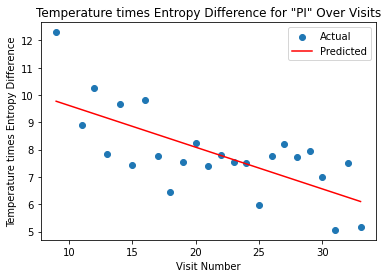

The mean squared error for the linear regression is 1.197297294691355.


In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import seaborn as sns
import statsmodels.api as sm

file_name = 'FinalBinedFull_normalised.xlsx'
drug_name = 'PI'

# Assuming the visits range from 1 to 10
visits = list(range(9, 35))

# Calculate temperature for each visit
temperatures = [calculate_temperature(file_name, drug_name, visit) for visit in visits]

# Calculate entropy for each visit
entropies = [shannon_entropy1(calculate_probabilities1(file_name, drug_name, visit)) for visit in visits]

# Calculate difference in entropy for each pair of consecutive visits
entropy_differences = np.log(np.abs([entropies[i+1] - entropies[i] for i in range(len(entropies) - 1)]))

# Calculate the product of temperature and entropy difference for each visit
products = [temperatures[i] * entropy_differences[i] for i in range(len(temperatures) - 1)]

# Convert products to a numpy array
products_np = np.array(products)

# Get indices where products_np is neither NaN nor infinity
indices = np.where(~np.isnan(products_np) & ~np.isinf(products_np))

# Get the visits and products where products is neither NaN nor infinity
visits_np = np.array(visits[:-1])[indices]
products_np = products_np[indices]

# Fit a linear regression model
X = sm.add_constant(visits_np)  # Adding constant for statsmodels
model = sm.OLS(products_np, X)
results = model.fit()

# Predict the values using the linear regression model
predicted_products = results.predict(X)

# Calculate the mean squared error
mse = mean_squared_error(products_np, predicted_products)

# Create a DataFrame for graph values
df = pd.DataFrame({'Visit Number': visits_np, 'Temperature x Entropy Difference': products_np})

# Open an Excel writer
with pd.ExcelWriter('results.xlsx', engine='openpyxl') as writer:
    # Write graph values to the first sheet
    df.to_excel(writer, sheet_name='Graph Values', index=False)

    # Write regression equation to another sheet
    coefficients = results.params
    equation = f"y = {coefficients[1]:.5f}x + {coefficients[0]:.5f}"
    equation_df = pd.DataFrame([equation], columns=['Regression Equation'])
    equation_df.to_excel(writer, sheet_name='Regression Equation', index=False)
    
    # Write the ANOVA summary to another sheet
    for i, table in enumerate(results.summary().tables):
        df = pd.read_html(table.as_html(), header=0, index_col=0)[0]
        df.to_excel(writer, sheet_name=f'ANOVA Summary Table {i+1}')


# Plot the graph
plt.scatter(visits_np, products_np, label='Actual')
plt.plot(visits_np, predicted_products, color='red', label='Predicted')
plt.xlabel('Visit Number')
plt.ylabel('Temperature times Entropy Difference')
plt.title(f'Temperature times Entropy Difference for "{drug_name}" Over Visits')
plt.legend()
plt.show()

# Print the MSE
print(f'The mean squared error for the linear regression is {mse}.')


In [3]:
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

def apply_lda(file_name, drug1, drug2):
    # Load the Excel file
    df1 = pd.read_excel(file_name, sheet_name=drug1)
    df2 = pd.read_excel(file_name, sheet_name=drug2)
    
    # Label the data: 0 for drug1 and 1 for drug2
    df1['label'] = 0
    df2['label'] = 1
    
    # Combine the data
    df = pd.concat([df1, df2])
    
    # Drop the CASEID and VISIT columns
    X = df.drop(columns=['CASEID', 'VISIT', 'label'])
    y = df['label']
    
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    # Initialize LDA
    lda = LDA()
    
    # Fit LDA on training data
    lda.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = lda.predict(X_test)
    
    # Print classification report and confusion matrix
    print(classification_report(y_test, y_pred, target_names=[drug1, drug2]))
    print(confusion_matrix(y_test, y_pred))
    
    # If you want to project data into LDA space (useful for visualization):
    X_lda = lda.transform(X)
    
    return X_lda

# Example usage
apply_lda("Measurments_for_independence.xlsx", "NRTI", "PI")


ValueError: Input contains NaN, infinity or a value too large for dtype('float64').

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.preprocessing import LabelEncoder

def apply_lda(file_name, drug1, drug2):
    # Read the data
    df = pd.read_excel(file_name, sheet_name=None)
    
    # Filter data based on the drug names provided
    df1 = df[drug1].drop(columns=['VISIT', 'CASEID'])
    df2 = df[drug2].drop(columns=['VISIT', 'CASEID'])
    
    # Combining dataframes
    df1['LABEL'] = drug1
    df2['LABEL'] = drug2
    combined_df = pd.concat([df1, df2])
    
    # Handling missing values by dropping rows
    combined_df.dropna(inplace=True)

    # Replace infinite values
    combined_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    combined_df.dropna(inplace=True)  # drop rows if there were any infinities
    
    # Splitting the data into features and labels
    X = combined_df.drop(columns='LABEL')
    y = combined_df['LABEL']
    
    # Convert labels into numerical values
    le = LabelEncoder()
    y = le.fit_transform(y)
    
    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Apply LDA
    lda = LDA()
    lda.fit(X_train, y_train)
    
    # Predict on the test data (this step can be extended to measure accuracy, etc.)
    y_pred = lda.predict(X_test)

    # For the purpose of this example, we'll return the transformed training data using LDA
    X_lda = lda.transform(X_train)

    return X_lda

# Example usage
apply_lda("Measurments_for_independence.xlsx", "NRTI", "PI")


array([[-0.5170759 ],
       [-0.15514432],
       [ 0.0885172 ],
       ...,
       [-0.4306048 ],
       [ 1.36362385],
       [-0.28062886]])

In [13]:
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split

def apply_lda(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize LDA
    lda = LDA()
    
    # Fit LDA on training data
    lda.fit(X_train, y_train)
    
    # Transform data using LDA
    X_lda = lda.transform(X)
    
    return X_lda, y

apply_lda("Measurments_for_independence.xlsx", "NRTI", "PI")




/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/4096467382.py:18: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


(array([[ 0.58952511],
        [-0.33538632],
        [-0.76408365],
        ...,
        [ 0.68593399],
        [ 0.3493759 ],
        [ 3.69297788]]),
 0       NRTI
 1       NRTI
 2       NRTI
 3       NRTI
 4       NRTI
         ... 
 3094      PI
 3095      PI
 3096      PI
 3097      PI
 3098      PI
 Name: label, Length: 3099, dtype: object)

In [ ]:
# Use the function and plot
transformed_data, y_labels = apply_lda("Measurments_for_independence.xlsx", "NRTI", "PI")

import matplotlib.pyplot as plt
plt.scatter(transformed_data, [0]*len(transformed_data), c=[1 if label == "NRTI" else 0 for label in y_labels], cmap='bwr')
plt.xlabel('LDA1')
plt.title('Scatter plot of LDA transformed data')
plt.show()

In [14]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')


NameError: name 'y_test' is not defined

In [20]:
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def apply_lda(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize LDA
    lda = LDA()
    
    # Fit LDA on training data
    lda.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = lda.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Transform data using LDA
    X_lda = lda.transform(X)
    
    return X_lda, y, accuracy

# Use the function and plot
transformed_data, y_labels, lda_accuracy = apply_lda("Measurments_for_independence.xlsx", "NRTI", "NNRTI")

print(f"LDA Accuracy: {lda_accuracy*100:.2f}%")



LDA Accuracy: 58.29%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/649354047.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [31]:
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report

def apply_lda(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize LDA
    lda = LDA()
    
    # Fit the LDA on the training data
    lda.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = lda.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Display confusion matrix, recall, and precision
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    return accuracy

# Use the function to get accuracy and other metrics
lda_accuracy = apply_lda("Measurments_for_independence.xlsx", "NRTI", "NNRTI")

print(f"\nLDA Accuracy: {lda_accuracy*100:.2f}%")


Confusion Matrix:
[[ 24 211]
 [ 29 268]]

Classification Report:
              precision    recall  f1-score   support

       NNRTI       0.45      0.10      0.17       235
          PI       0.56      0.90      0.69       297

    accuracy                           0.55       532
   macro avg       0.51      0.50      0.43       532
weighted avg       0.51      0.55      0.46       532


LDA Accuracy: 54.89%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/2698813819.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [24]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report

def apply_random_forest(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize Random Forest classifier
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    
    # Fit the classifier on the training data
    rf.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = rf.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Display confusion matrix, recall, and precision
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return accuracy

# Use the function to get accuracy and other metrics
rf_accuracy = apply_random_forest("Measurments_for_independence.xlsx", "PI", "NNRTI")

print(f"\nRandom Forest Accuracy: {rf_accuracy*100:.2f}%")


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/2100096390.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


Confusion Matrix:
[[ 84 151]
 [130 167]]

Classification Report:
              precision    recall  f1-score   support

       NNRTI       0.39      0.36      0.37       235
          PI       0.53      0.56      0.54       297

    accuracy                           0.47       532
   macro avg       0.46      0.46      0.46       532
weighted avg       0.47      0.47      0.47       532


Random Forest Accuracy: 47.18%


In [27]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report

def apply_logistic_regression(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize Logistic Regression
    log_reg = LogisticRegression(max_iter=10000, random_state=42)
    
    # Fit the model on the training data
    log_reg.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = log_reg.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Display confusion matrix, recall, and precision
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return accuracy

# Use the function to get accuracy and other metrics
logistic_accuracy = apply_logistic_regression("Measurments_for_independence.xlsx", "PI", "NNRTI")

print(f"\nLogistic Regression Accuracy: {logistic_accuracy*100:.2f}%")


Confusion Matrix:
[[  4 231]
 [  4 293]]

Classification Report:
              precision    recall  f1-score   support

       NNRTI       0.50      0.02      0.03       235
          PI       0.56      0.99      0.71       297

    accuracy                           0.56       532
   macro avg       0.53      0.50      0.37       532
weighted avg       0.53      0.56      0.41       532


Logistic Regression Accuracy: 55.83%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/3276396167.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [34]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report

def apply_svm(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize SVM classifier
    svm = SVC(kernel='linear')
    
    # Fit the SVM on the training data
    svm.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = svm.predict(X_test)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Display confusion matrix, recall, and precision
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    
    return accuracy

# Use the function to get accuracy and other metrics
svm_accuracy = apply_svm("Measurments_for_independence.xlsx", "PI", "NNRTI")

print(f"\nSVM Accuracy: {svm_accuracy*100:.2f}%")


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/4137926069.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


Confusion Matrix:
[[ 71 164]
 [ 82 215]]

Classification Report:
              precision    recall  f1-score   support

       NNRTI       0.46      0.30      0.37       235
          PI       0.57      0.72      0.64       297

    accuracy                           0.54       532
   macro avg       0.52      0.51      0.50       532
weighted avg       0.52      0.54      0.52       532


SVM Accuracy: 53.76%


In [42]:
import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

def apply_qda(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize QDA
    qda = QuadraticDiscriminantAnalysis()
    
    # Fit the QDA model on the training data
    qda.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = qda.predict(X_test)
    
    # Calculate accuracy and other metrics
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=sheet1)
    recall = recall_score(y_test, y_pred, pos_label=sheet1)
    
    # Print the results
    print(f"QDA Accuracy: {accuracy*100:.2f}%")
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision*100:.2f}%")
    print(f"Recall: {recall*100:.2f}%")
    
    return accuracy

# Use the function to get accuracy and other metrics
qda_accuracy = apply_qda("FinalBinedFull.xlsx", "NNRTI", "NRTI")


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/3211149949.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


QDA Accuracy: 52.29%
Confusion Matrix:
[[2324 7712]
 [1918 8230]]
Precision: 54.79%
Recall: 23.16%


In [41]:

import pandas as pd
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

def apply_qda(file_name, sheet1, sheet2):
    # Read data from the specific sheets
    data1 = pd.read_excel(file_name, sheet_name=sheet1)
    data2 = pd.read_excel(file_name, sheet_name=sheet2)
    
    # Mark the data from the two sheets with their respective names
    data1['label'] = sheet1
    data2['label'] = sheet2
    
    # Combine the two datasets
    combined_data = pd.concat([data1, data2], ignore_index=True)
    
    # Handle NaN values by filling them with the mean of the respective column
    combined_data = combined_data.fillna(combined_data.mean())
    
    # Drop non-feature columns
    X = combined_data.drop(columns=['VISIT', 'CASEID', 'label'])
    y = combined_data['label']
    
    # Split the data for validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Initialize QDA
    qda = QuadraticDiscriminantAnalysis()
    
    # Fit the QDA model on the training data
    qda.fit(X_train, y_train)
    
    # Predict on the test data
    y_pred = qda.predict(X_test)
    
    # Calculate accuracy and other metrics
    accuracy = accuracy_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label=sheet1)
    recall = recall_score(y_test, y_pred, pos_label=sheet1)
    
    # Print the results
    print(f"QDA Accuracy: {accuracy*100:.2f}%")
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision*100:.2f}%")
    print(f"Recall: {recall*100:.2f}%")
    
    return accuracy

# Use the function to get accuracy and other metrics
qda_accuracy = apply_qda("NNRTI_NRTI_common_domain_for_ind.xlsx", "NNRTI", "NRTI")


QDA Accuracy: 85.98%
Confusion Matrix:
[[9193  799]
 [ 770  430]]
Precision: 92.27%
Recall: 92.00%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/1305653032.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [46]:
import pandas as pd
import numpy as np

def calculate_sheet_entropy(file_name, drug):
    # Load the specific sheet (drug) from the excel file
    df = pd.read_excel(file_name, sheet_name=drug)

    # Drop CASEID and VISIT columns
    df = df.drop(columns=['CASEID', 'VISIT'])

    # Find unique microstates and their counts
    microstates, counts = np.unique(df.values, axis=0, return_counts=True)

    # Calculate probabilities
    probabilities = counts / counts.sum()

    # Calculate Shannon entropy
    entropy = -np.sum(probabilities * np.log(probabilities))

    return entropy

# Example usage:
entropy_commonNRTI = calculate_sheet_entropy("PI_NRTI_common_domain_for_ind.xlsx", "NRTI")
entropy_commonPI = calculate_sheet_entropy("PI_NRTI_common_domain_for_ind.xlsx", "PI")

entropy_non_commonNRTI = calculate_sheet_entropy("non_common_domain_NRTI_PI_for_ind.xlsx", "NRTI")
entropy_non_commonPI = calculate_sheet_entropy("non_common_domain_NRTI_PI_for_ind.xlsx", "PI")


print(f"Entropy common for NRTI: {entropy_commonNRTI}")
print(f"Entropy non common for NRTI: {entropy_non_commonNRTI}")

Entropy common for NRTI: 5.07449964642347
Entropy non common for NRTI: 7.1167472281113175


In [107]:
number_of_bins_input=100

# load excel file
xls = pd.ExcelFile('Three_plus_others.xlsx')

# create a new workbook
writer = pd.ExcelWriter('Three_plus_others_binned.xlsx', engine='openpyxl')

for sheet in xls.sheet_names:
    df = xls.parse(sheet)
    # remove rows with missing data
    df = df.dropna(subset=df.columns[11:])
    # write DataFrame to an excel sheet with the sheet name = drug name
    df.to_excel(writer, sheet_name=sheet, index=False)

# save the result
writer.save()

# Reopen the cleaned file
xls = pd.ExcelFile('Three_plus_others.xlsx')

# Create a new workbook
writer = pd.ExcelWriter('Three_plus_others_binned.xlsx', engine='openpyxl')

# Determine the minimum range for each column across all sheets
min_ranges = {}
for column in df.columns[11:]:
    min_range = float('inf')
    for sheet in xls.sheet_names:
        df = xls.parse(sheet)
        range_ = df[column].max() - df[column].min()
        if range_ < min_range:
            min_range = range_
    min_ranges[column] = min_range

# Perform binning based on the smallest range
for sheet in xls.sheet_names:
    df = xls.parse(sheet)
    for column in df.columns[11:]:
        min_val = df[column].min()
        max_val = df[column].max()
        num_bins = number_of_bins_input
        bin_ranges = np.linspace(min_val, max_val + min_ranges[column], num_bins + 1)
        if column == "CColumn1":
            df[column] = pd.cut(np.log10(df[column]), bins=np.log10(bin_ranges), labels=np.log10(bin_ranges[1:]))
        else:
            df[column] = pd.cut(df[column], bins=bin_ranges, labels=bin_ranges[1:])
    df.to_excel(writer, sheet_name=sheet, index=False)

# Save the result
writer.save()



In [108]:
common_domain('Three_plus_others_binned.xlsx', 'Other', 'NRTI')

In [109]:
def diff_files(full_file, common_file):
    # Load the xls file's Sheets as dataframes
    xls_full = pd.ExcelFile(full_file)
    xls_common = pd.ExcelFile(common_file)
    
    # Create an Excel writer object
    writer = pd.ExcelWriter('non_common_domain_Other_NRTI.xlsx', engine='xlsxwriter')

    # For each sheet in the common file, extract the difference between the full file's sheet and the common file's sheet
    for sheet in xls_common.sheet_names:
        df_full = pd.read_excel(full_file, sheet_name=sheet)
        df_common = pd.read_excel(common_file, sheet_name=sheet)
        
        # Merge with indicator to find out which rows are only present in the full file
        merged = df_full.merge(df_common, indicator=True, how='outer')
        diff = merged[merged['_merge'] == 'left_only']
        
        # Drop the indicator column
        diff = diff.drop(columns=['_merge'])
        
        # Write the diff to the new Excel file
        diff.to_excel(writer, sheet_name=sheet, index=False)

    # Save the result
    writer.save()

diff_files('Three_plus_others_binned.xlsx', 'Other_NRTI_common_domain.xlsx')

In [97]:
common_domain('all_plus_others.xlsx', 'Other', 'NRTI')


In [98]:
def diff_files(full_file, common_file):
    # Load the xls file's Sheets as dataframes
    xls_full = pd.ExcelFile(full_file)
    xls_common = pd.ExcelFile(common_file)
    
    # Create an Excel writer object
    writer = pd.ExcelWriter('non_common_domain_Other_NRTI.xlsx', engine='xlsxwriter')

    # For each sheet in the common file, extract the difference between the full file's sheet and the common file's sheet
    for sheet in xls_common.sheet_names:
        df_full = pd.read_excel(full_file, sheet_name=sheet)
        df_common = pd.read_excel(common_file, sheet_name=sheet)
        
        # Merge with indicator to find out which rows are only present in the full file
        merged = df_full.merge(df_common, indicator=True, how='outer')
        diff = merged[merged['_merge'] == 'left_only']
        
        # Drop the indicator column
        diff = diff.drop(columns=['_merge'])
        
        # Write the diff to the new Excel file
        diff.to_excel(writer, sheet_name=sheet, index=False)

    # Save the result
    writer.save()

diff_files('Three_plus_others.xlsx', 'Other_NRTI_common_domain.xlsx')

In [69]:
entropy_commonNRTI = calculate_sheet_entropy("Other_NRTI_common_domain.xlsx", "NRTI")
entropy_commonOther = calculate_sheet_entropy("Other_NRTI_common_domain.xlsx", "Other")

entropy_non_commonNRTI = calculate_sheet_entropy("non_common_domain_Other_NRTI.xlsx", "NRTI")
entropy_non_commonOther = calculate_sheet_entropy("non_common_domain_Other_NRTI.xlsx", "Other")


print(f"Entropy common for NRTI: {entropy_commonNRTI}")
print(f"Entropy non common for NRTI: {entropy_non_commonNRTI}")

Entropy common for NRTI: 7.41336733569524
Entropy non common for NRTI: 10.187857771426822


In [106]:
qda_accuracy = apply_qda("Other_NRTI_common_domain.xlsx", "Other", "NRTI")

QDA Accuracy: 67.56%
Confusion Matrix:
[[301  20]
 [137  26]]
Precision: 56.52%
Recall: 15.95%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/3211149949.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [105]:
qda_accuracy = apply_qda("Three_plus_others.xlsx", "Other", "NRTI")

QDA Accuracy: 83.10%
Confusion Matrix:
[[7505  259]
 [1281   68]]
Precision: 20.80%
Recall: 5.04%


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_4606/3211149949.py:19: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  combined_data = combined_data.fillna(combined_data.mean())


In [140]:
import pandas as pd
import numpy as np
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score

# Read in the data for Dataset 1
sheet1R = "PI"
data1_1 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet1R, header=1, usecols="A", nrows=24)
data2_1 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet1R, header=1, usecols="N", nrows=24)

# Read in the data for Dataset 2
sheet2R = "NRTI"
data1_2 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet2R, header=1, usecols="A", nrows=24)
data2_2 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet2R, header=1, usecols="N", nrows=24)

# Drop rows with NaNs in each dataset
data1_1.dropna(inplace=True)
data2_1.dropna(inplace=True)
data1_2.dropna(inplace=True)
data2_2.dropna(inplace=True)

# Make sure all datasets are of the same length, this is crucial for label generation
min_len = min(len(data1_1), len(data2_1), len(data1_2), len(data2_2))
data1_1 = data1_1[:min_len]
data2_1 = data2_1[:min_len]
data1_2 = data1_2[:min_len]
data2_2 = data2_2[:min_len]

# Combine data into a single dataset
X = np.concatenate([data1_1.values, data1_2.values, data2_1.values, data2_2.values], axis=0)
y = np.array([0]*min_len + [1]*min_len + [0]*min_len + [1]*min_len)  # 0 for dataset 1 and 1 for dataset 2

# Train the QDA model
lda = LDA()
lda.fit(X, y)

# Make predictions
y_pred = lda.predict(X)

# Evaluate the model
accuracy = accuracy_score(y, y_pred)
conf_matrix = confusion_matrix(y, y_pred)
recall = recall_score(y, y_pred)
precision = precision_score(y, y_pred)

# Print the results
print(f"Accuracy: {accuracy}")
print(f"Confusion Matrix: \n{conf_matrix}")
print(f"Recall: {recall}")
print(f"Precision: {precision}")


Accuracy: 0.5
Confusion Matrix: 
[[26 22]
 [26 22]]
Recall: 0.4583333333333333
Precision: 0.5


In [142]:
import pandas as pd
import numpy as np
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score

# Read in the data for Dataset 1
sheet1R = "NNRTI"
data1_1 = pd.read_excel("NNRTI_NRTI_common_domain_for_average.xlsx", sheet_name=sheet1R, header=1, usecols="A", nrows=50087)
data2_1 = pd.read_excel("NNRTI_NRTI_common_domain_for_average.xlsx", sheet_name=sheet1R, header=1, usecols="N", nrows=50087)

# Read in the data for Dataset 2
sheet2R = "NRTI"
data1_2 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet2R, header=1, usecols="A", nrows=50087)
data2_2 = pd.read_excel("AveragedOriginalMeasurements_with graphs.xlsx", sheet_name=sheet2R, header=1, usecols="N", nrows=50087)

# Drop rows with NaNs in each dataset
data1_1.dropna(inplace=True)
data2_1.dropna(inplace=True)
data1_2.dropna(inplace=True)
data2_2.dropna(inplace=True)

# Make sure all datasets are of the same length, this is crucial for label generation
min_len = min(len(data1_1), len(data2_1), len(data1_2), len(data2_2))
data1_1 = data1_1[:min_len]
data2_1 = data2_1[:min_len]
data1_2 = data1_2[:min_len]
data2_2 = data2_2[:min_len]

# Combine data into a single dataset
X = np.concatenate([data1_1.values, data1_2.values, data2_1.values, data2_2.values], axis=0)
y = np.array([0]*min_len + [1]*min_len + [0]*min_len + [1]*min_len)  # 0 for dataset 1 and 1 for dataset 2

# Train the QDA model
lda = LDA()
lda.fit(X, y)

# Make predictions
y_pred = lda.predict(X)

# Evaluate the model
accuracy = accuracy_score(y, y_pred)
conf_matrix = confusion_matrix(y, y_pred)
recall = recall_score(y, y_pred)
precision = precision_score(y, y_pred)

# Print the results
print(f"Accuracy: {accuracy}")
print(f"Confusion Matrix: \n{conf_matrix}")
print(f"Recall: {recall}")
print(f"Precision: {precision}")


Accuracy: 0.5625
Confusion Matrix: 
[[30 18]
 [24 24]]
Recall: 0.5
Precision: 0.5714285714285714


NEW STUFF

In [2]:
import pandas as pd

def normalize_excel_sheets(input_file, output_file, sheets):
    # Create a new Excel writer
    with pd.ExcelWriter(output_file) as writer:
        # Iterate through the sheets
        for sheet in sheets:
            # Read the data from the sheet
            df = pd.read_excel(input_file, sheet_name=sheet)
            
            # Min-Max normalize columns excluding the first two
            for column in df.columns[2:]:
                min_val = df[column].min()
                max_val = df[column].max()
                df[column] = (df[column] - min_val) / (max_val - min_val)
            
            # Save the normalized data back to a new Excel file
            df.to_excel(writer, sheet_name=sheet, index=False)

# Specify the sheets to be normalized
sheets_to_normalize = ['NRTI', 'NNRTI', 'PI']

# Call the function
normalize_excel_sheets("Bootstrap_for_temp.xlsx", "Normalised_Bootstrap_for_temp.xlsx", sheets_to_normalize)


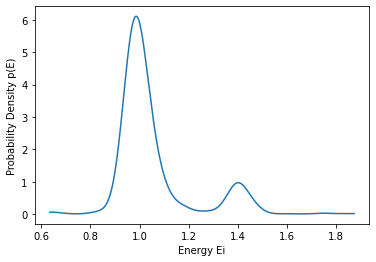

[3.70523494e-05]


In [4]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

def get_energy_probability_density(file_name, drug, visit):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # 3. Use KDE to estimate a continuous probability distribution
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values)
    
    # 4. Create a callable function for p(E)
    def p(E):
        return kde(E)
    
    # Example: Plotting the KDE
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    plt.plot(energy_range, kde(energy_range))
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.show()
    
    return p

# Example usage:
energy_func = get_energy_probability_density("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 15)
print(energy_func(0.5))  # This will give p(E) for E=0.5


In [5]:
def get_kde_score(file_name, drug, visit):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values)
    
    # The score is interpreted as a pseudo R^2
    score = kde.logpdf(energy_values).mean()
    return score

# Example usage:
score = get_kde_score("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 15)
print(f"Pseudo R^2 for the KDE fit: {score}")


Pseudo R^2 for the KDE fit: 1.1309287354420876


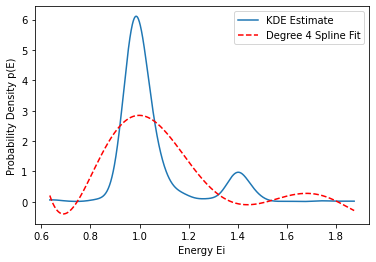

R^2 for the Degree 4 Spline fit: 0.56
11.060684030664278


In [10]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # 3. Use KDE to estimate a continuous probability distribution
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 4 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=5)
    
    # 5. Calculate R^2 for the spline fit to the KDE results
    r2 = r2_score(kde_values, spline(energy_range))
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 4 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline, r2

# Example usage:
spline_func, r2 = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 15)
print(f"R^2 for the Degree 4 Spline fit: {r2:.2f}")
print(spline_func(0.5))  # This will give p(E) for E=0.5


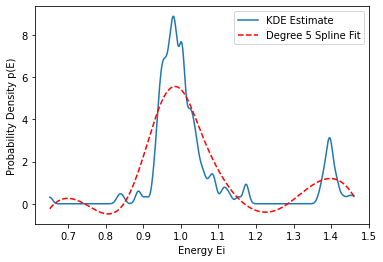

R^2 for the Degree 5 Spline fit (bandwidth=0.05): 0.79


In [24]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000) # increased points
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 5 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=3)
    
    # 5. Calculate R^2 for the spline fit to the KDE results
    r2 = r2_score(kde_values, spline(energy_range))
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 5 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline, r2

# Example usage without specifying bandwidth:
#spline_func, r2 = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 20)
#print(f"R^2 for the Degree 5 Spline fit (default bandwidth): {r2:.2f}")

# Example usage with specified bandwidth:
spline_func_bw, r2_bw = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 20, bandwidth=0.05)
print(f"R^2 for the Degree 5 Spline fit (bandwidth=0.05): {r2_bw:.2f}")


In [28]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None, plot=False):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data points, return None values
    if len(df_filtered) <= 1:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000) # increased points
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 5 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=1)
    
    # 5. Calculate R^2 for the spline fit to the KDE results
    r2 = r2_score(kde_values, spline(energy_range))
    
    if plot:
        # 6. Plot the KDE and the spline fit
        plt.plot(energy_range, kde_values, label='KDE Estimate')
        plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 4 Spline Fit')
        plt.xlabel('Energy Ei')
        plt.ylabel('Probability Density p(E)')
        plt.title(f"VISIT {visit}")
        plt.legend()
        plt.show()
    
    return spline, r2

# Iterate over visits from 10 to 30 and print R^2
for visit in range(10, 31):
    _, r2 = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, bandwidth=0.05)
    if r2 is not None:
        print(f"R^2 for VISIT {visit} with Degree 4 Spline fit (bandwidth=0.05): {r2:.2f}")
    else:
        print(f"VISIT {visit}: Not enough data.")


VISIT 10: Not enough data.
R^2 for VISIT 11 with Degree 4 Spline fit (bandwidth=0.05): 0.77
R^2 for VISIT 12 with Degree 4 Spline fit (bandwidth=0.05): 0.96
R^2 for VISIT 13 with Degree 4 Spline fit (bandwidth=0.05): 0.74
R^2 for VISIT 14 with Degree 4 Spline fit (bandwidth=0.05): 0.71
R^2 for VISIT 15 with Degree 4 Spline fit (bandwidth=0.05): 0.70
R^2 for VISIT 16 with Degree 4 Spline fit (bandwidth=0.05): 0.70
R^2 for VISIT 17 with Degree 4 Spline fit (bandwidth=0.05): 0.62
R^2 for VISIT 18 with Degree 4 Spline fit (bandwidth=0.05): 0.74
R^2 for VISIT 19 with Degree 4 Spline fit (bandwidth=0.05): 0.77


KeyboardInterrupt: 

In [29]:
def get_energy_spline_function(file_name, drug, visit, bandwidth=None, k=4, plot=False):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data points, return None values
    if len(df_filtered) <= 1:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000) # increased points
    kde_values = kde(energy_range)
    # 4. Fit a B-spline of degree k to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=k)
    
    # 5. Calculate R^2 for the spline fit to the KDE results
    r2 = r2_score(kde_values, spline(energy_range))
    
    if plot:
        # 6. Plot the KDE and the spline fit
        plt.plot(energy_range, kde_values, label='KDE Estimate')
        plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 4 Spline Fit')
        plt.xlabel('Energy Ei')
        plt.ylabel('Probability Density p(E)')
        plt.title(f"VISIT {visit}")
        plt.legend()
        plt.show()
    
    return spline, r2
    

# Iterate over visits and degrees:
for degree in range(1, 6):
    print(f"\nDegree {degree} Spline Results:")
    for visit in range(10, 31):
        _, r2 = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, bandwidth=0.05, k=degree)
        if r2 is not None:
            print(f"R^2 for VISIT {visit} with Degree {degree} Spline fit (bandwidth=0.05): {r2:.2f}")
        else:
            print(f"VISIT {visit}: Not enough data.")



Degree 1 Spline Results:
VISIT 10: Not enough data.
R^2 for VISIT 11 with Degree 1 Spline fit (bandwidth=0.05): 0.77
R^2 for VISIT 12 with Degree 1 Spline fit (bandwidth=0.05): 0.96
R^2 for VISIT 13 with Degree 1 Spline fit (bandwidth=0.05): 0.74
R^2 for VISIT 14 with Degree 1 Spline fit (bandwidth=0.05): 0.71
R^2 for VISIT 15 with Degree 1 Spline fit (bandwidth=0.05): 0.70
R^2 for VISIT 16 with Degree 1 Spline fit (bandwidth=0.05): 0.70
R^2 for VISIT 17 with Degree 1 Spline fit (bandwidth=0.05): 0.62
R^2 for VISIT 18 with Degree 1 Spline fit (bandwidth=0.05): 0.74
R^2 for VISIT 19 with Degree 1 Spline fit (bandwidth=0.05): 0.77
R^2 for VISIT 20 with Degree 1 Spline fit (bandwidth=0.05): 0.79
R^2 for VISIT 21 with Degree 1 Spline fit (bandwidth=0.05): 0.76
R^2 for VISIT 22 with Degree 1 Spline fit (bandwidth=0.05): 0.82
R^2 for VISIT 23 with Degree 1 Spline fit (bandwidth=0.05): 0.73
R^2 for VISIT 24 with Degree 1 Spline fit (bandwidth=0.05): 0.84
R^2 for VISIT 25 with Degree 1 Spline

VISIT 10 skipped due to insufficient data.


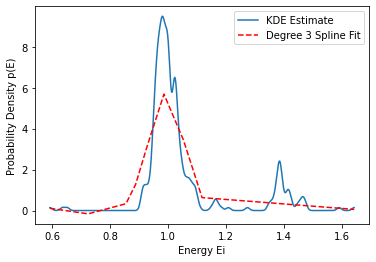

R^2 for VISIT 11 with Degree 3 Spline fit (bandwidth=0.05): 0.77


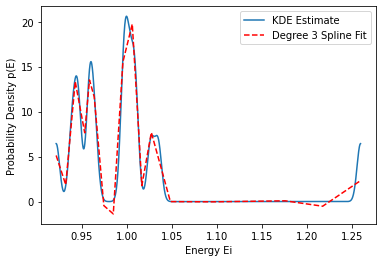

R^2 for VISIT 12 with Degree 3 Spline fit (bandwidth=0.05): 0.96


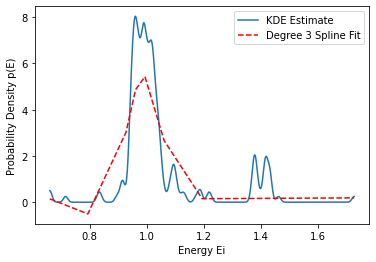

R^2 for VISIT 13 with Degree 3 Spline fit (bandwidth=0.05): 0.74


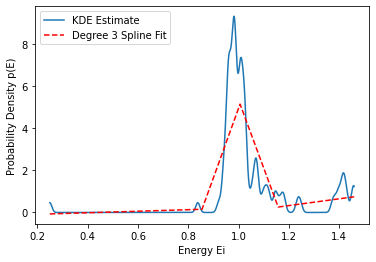

R^2 for VISIT 14 with Degree 3 Spline fit (bandwidth=0.05): 0.71


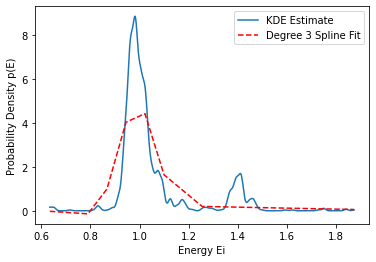

R^2 for VISIT 15 with Degree 3 Spline fit (bandwidth=0.05): 0.70


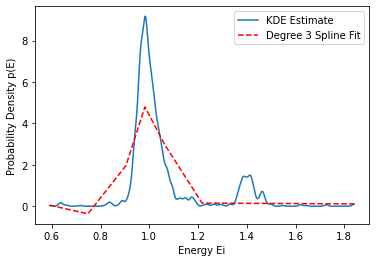

R^2 for VISIT 16 with Degree 3 Spline fit (bandwidth=0.05): 0.70


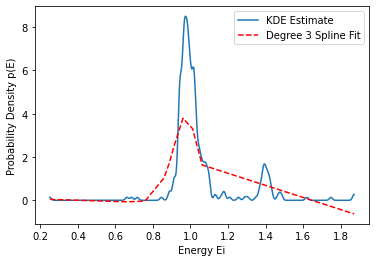

R^2 for VISIT 17 with Degree 3 Spline fit (bandwidth=0.05): 0.62


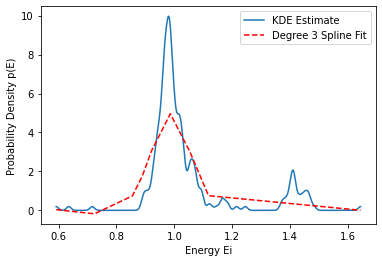

R^2 for VISIT 18 with Degree 3 Spline fit (bandwidth=0.05): 0.74


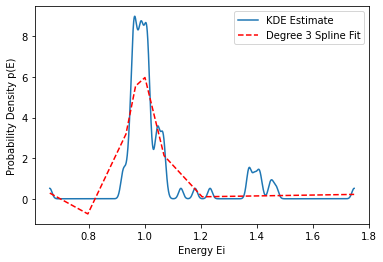

R^2 for VISIT 19 with Degree 3 Spline fit (bandwidth=0.05): 0.77


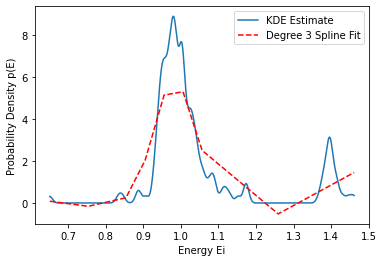

R^2 for VISIT 20 with Degree 3 Spline fit (bandwidth=0.05): 0.79


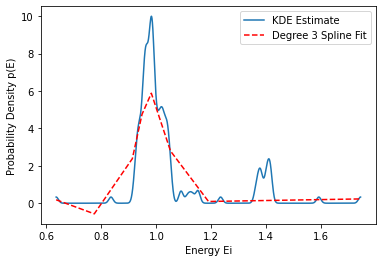

R^2 for VISIT 21 with Degree 3 Spline fit (bandwidth=0.05): 0.76


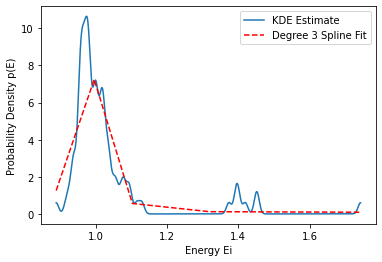

R^2 for VISIT 22 with Degree 3 Spline fit (bandwidth=0.05): 0.82


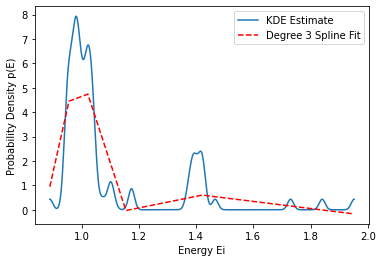

R^2 for VISIT 23 with Degree 3 Spline fit (bandwidth=0.05): 0.73


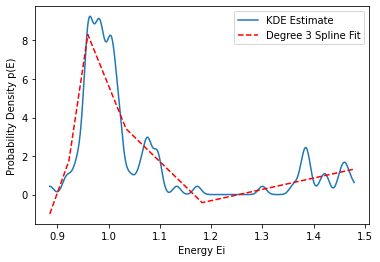

R^2 for VISIT 24 with Degree 3 Spline fit (bandwidth=0.05): 0.84


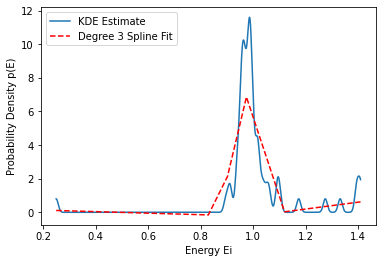

R^2 for VISIT 25 with Degree 3 Spline fit (bandwidth=0.05): 0.79


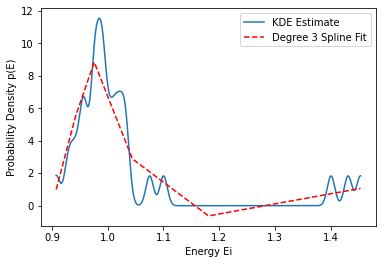

R^2 for VISIT 26 with Degree 3 Spline fit (bandwidth=0.05): 0.88


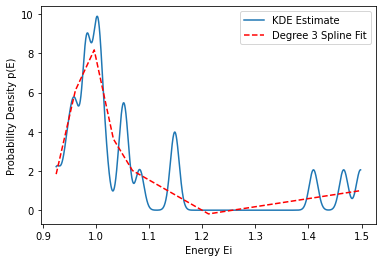

R^2 for VISIT 27 with Degree 3 Spline fit (bandwidth=0.05): 0.84


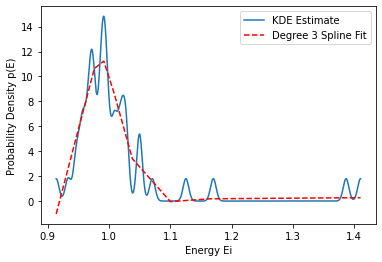

R^2 for VISIT 28 with Degree 3 Spline fit (bandwidth=0.05): 0.91


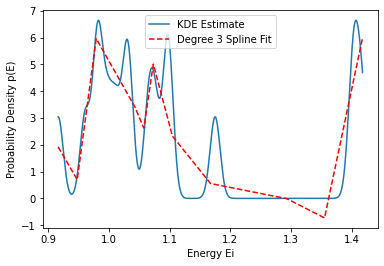

R^2 for VISIT 29 with Degree 3 Spline fit (bandwidth=0.05): 0.79


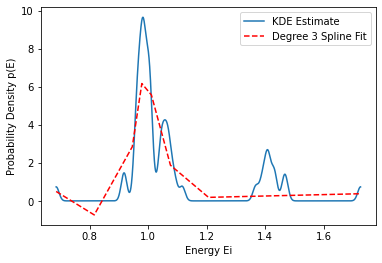

R^2 for VISIT 30 with Degree 3 Spline fit (bandwidth=0.05): 0.74


In [32]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data, return None
    if len(df_filtered) < 2:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000) # increased points
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 3 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=1)
    
    # 5. Calculate R^2 for the spline fit to the KDE results
    r2 = r2_score(kde_values, spline(energy_range))
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 3 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline, r2

# Iterate over visits from 10 to 30 and print R^2
for visit in range(10, 31):
    _, r2 = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, bandwidth=0.05)
    if r2 is not None:
        print(f"R^2 for VISIT {visit} with Degree 3 Spline fit (bandwidth=0.05): {r2:.2f}")
    else:
        print(f"VISIT {visit} skipped due to insufficient data.")


In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data, return None
    if len(df_filtered) < 2:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000) # increased points
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 3 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=3)
    
    # 5. Calculate AMSE for the spline fit to the KDE results
    amse = np.mean((spline(energy_range) - kde_values)**2)
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 3 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline, amse

# Iterate over visits from 10 to 30 and print AMSE
for visit in range(10, 31):
    _, amse = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, bandwidth=0.05)
    if amse is not None:
        print(f"AMSE for VISIT {visit} with Degree 3 Spline fit (bandwidth=0.05): {amse:.2f}")
    else:
        print(f"VISIT {visit} skipped due to insufficient data.")


FileNotFoundError: [Errno 2] No such file or directory: 'Normalised_Bootstrap_for_temp.xlsx'

VISIT 10 skipped due to insufficient data.


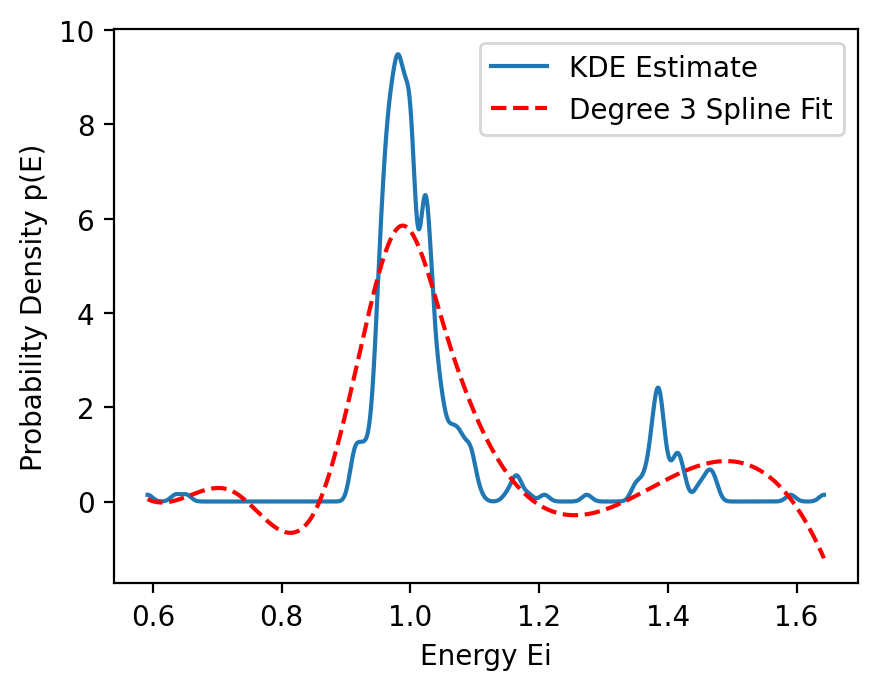

AIC for VISIT 11 with Degree 3 Spline fit (bandwidth=0.05): 7.99


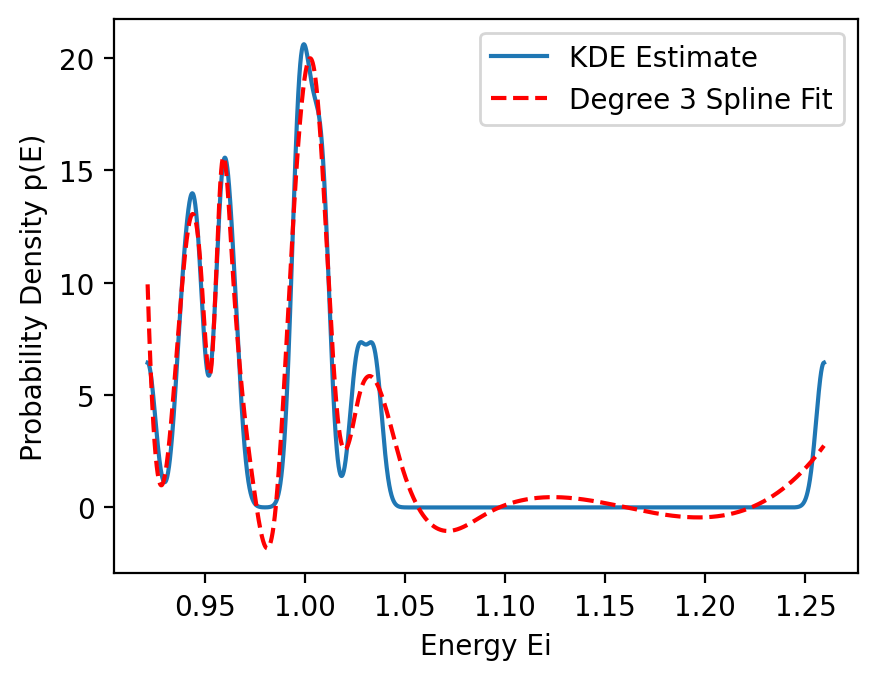

AIC for VISIT 12 with Degree 3 Spline fit (bandwidth=0.05): 8.61


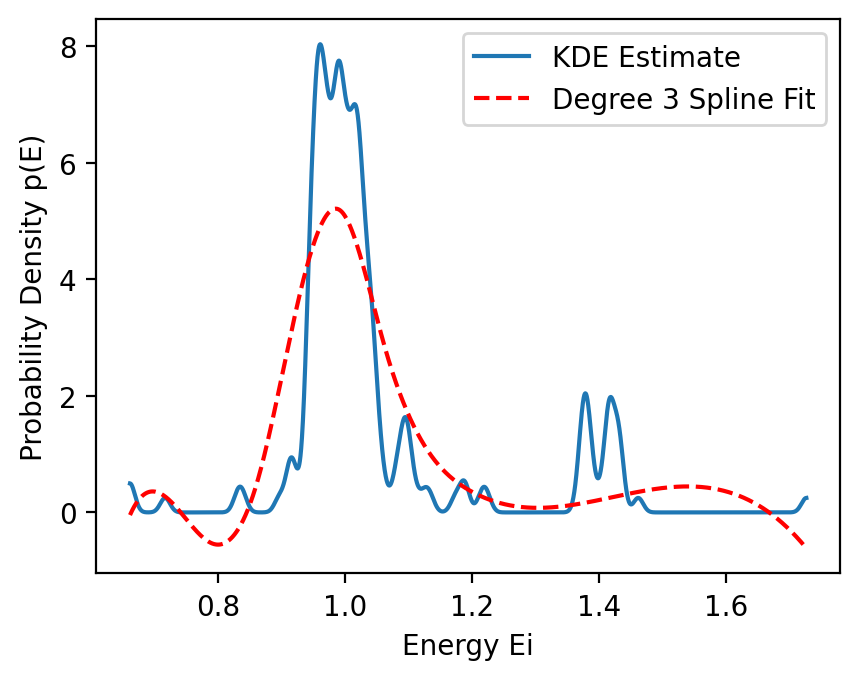

AIC for VISIT 13 with Degree 3 Spline fit (bandwidth=0.05): 6.20


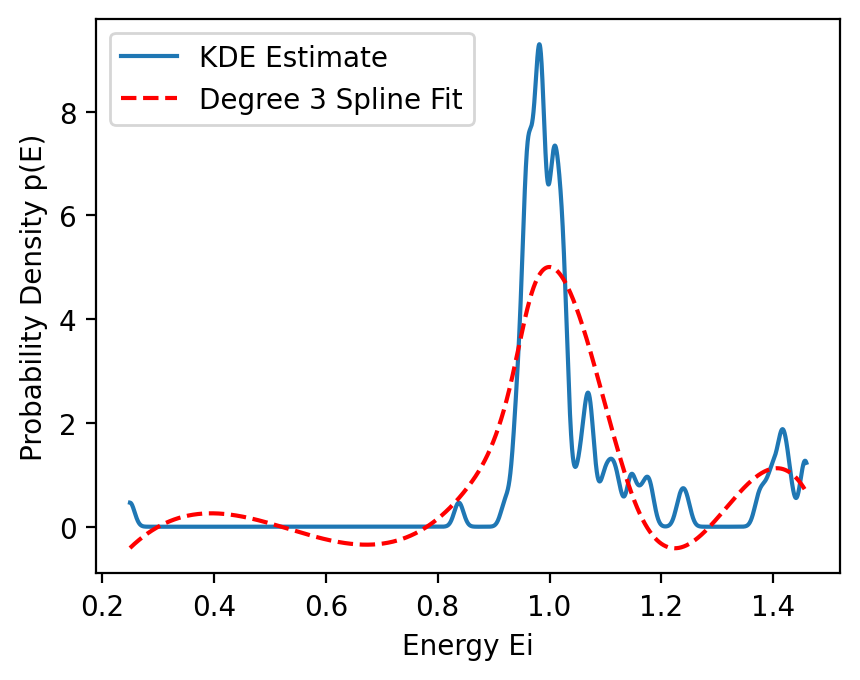

AIC for VISIT 14 with Degree 3 Spline fit (bandwidth=0.05): 7.92


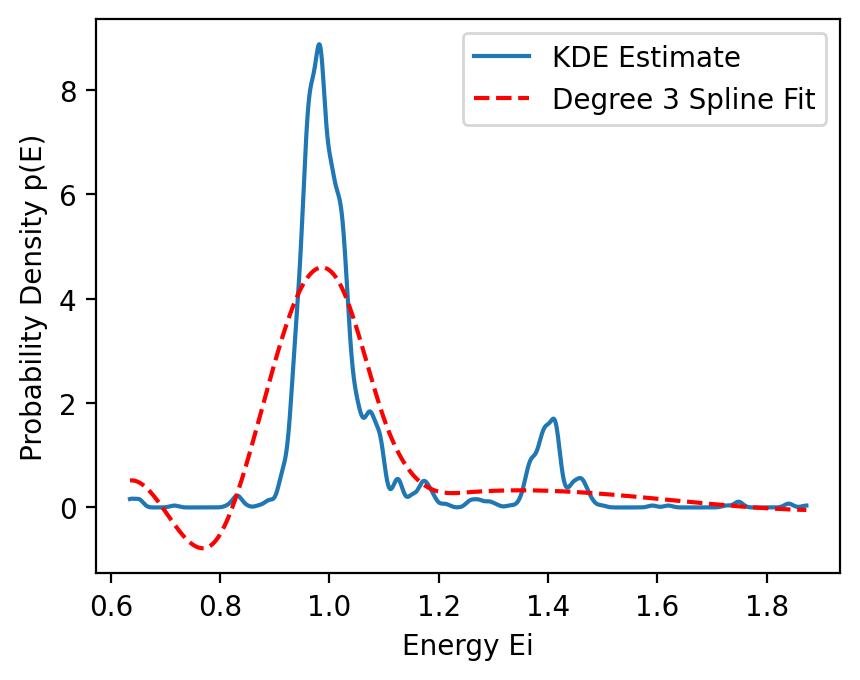

AIC for VISIT 15 with Degree 3 Spline fit (bandwidth=0.05): 7.90


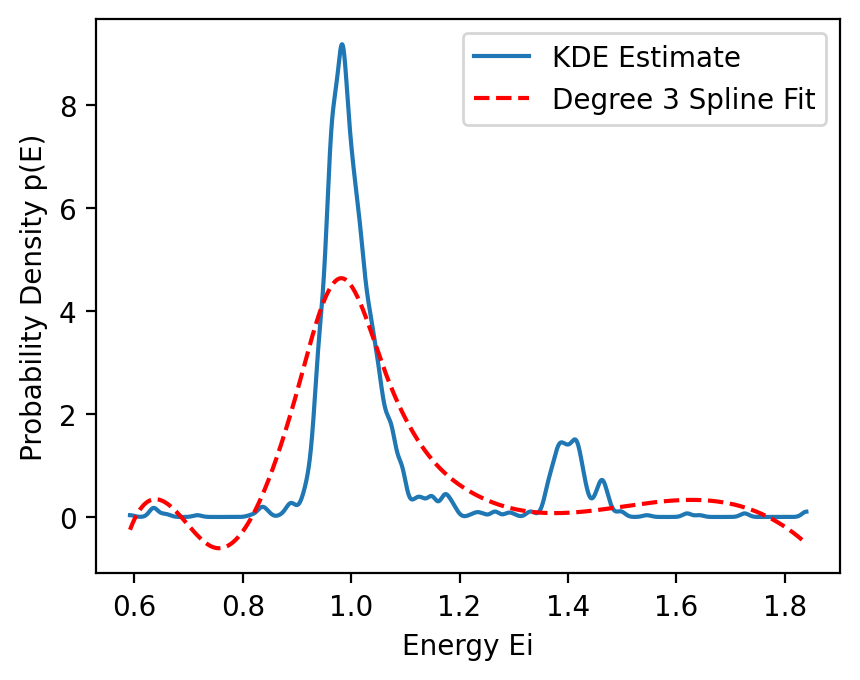

AIC for VISIT 16 with Degree 3 Spline fit (bandwidth=0.05): 8.20


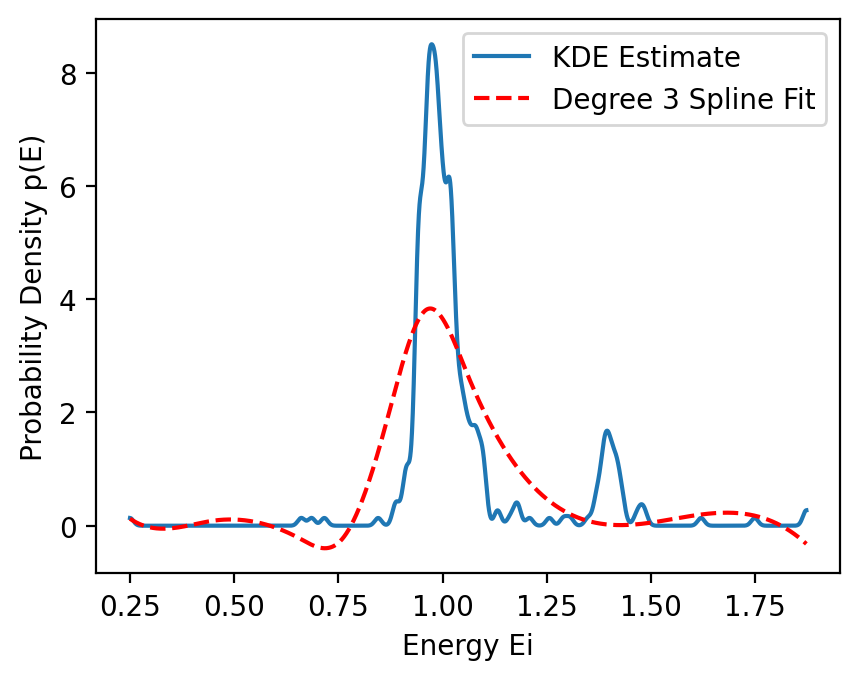

AIC for VISIT 17 with Degree 3 Spline fit (bandwidth=0.05): 10.16


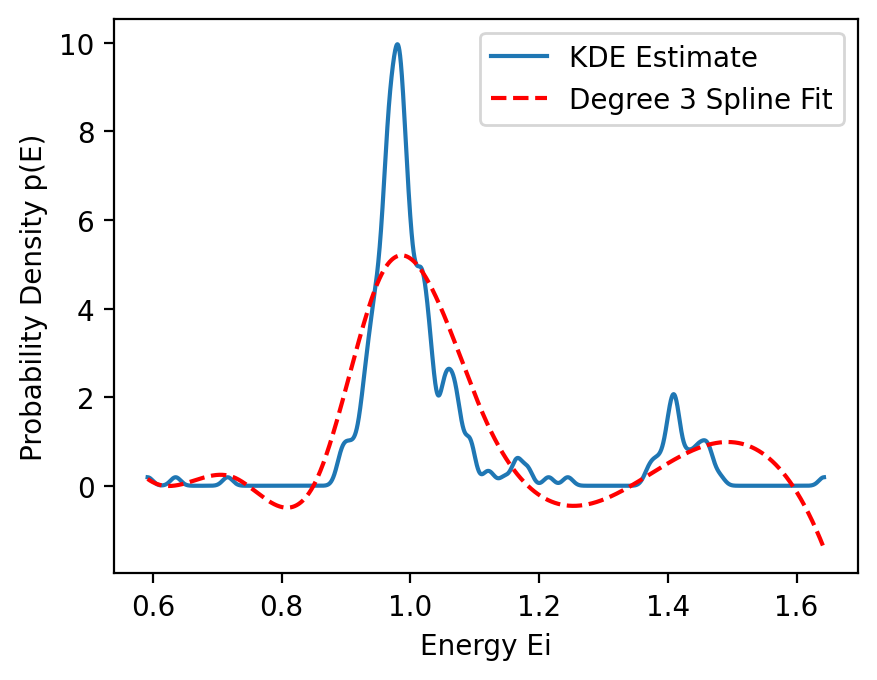

AIC for VISIT 18 with Degree 3 Spline fit (bandwidth=0.05): 8.67


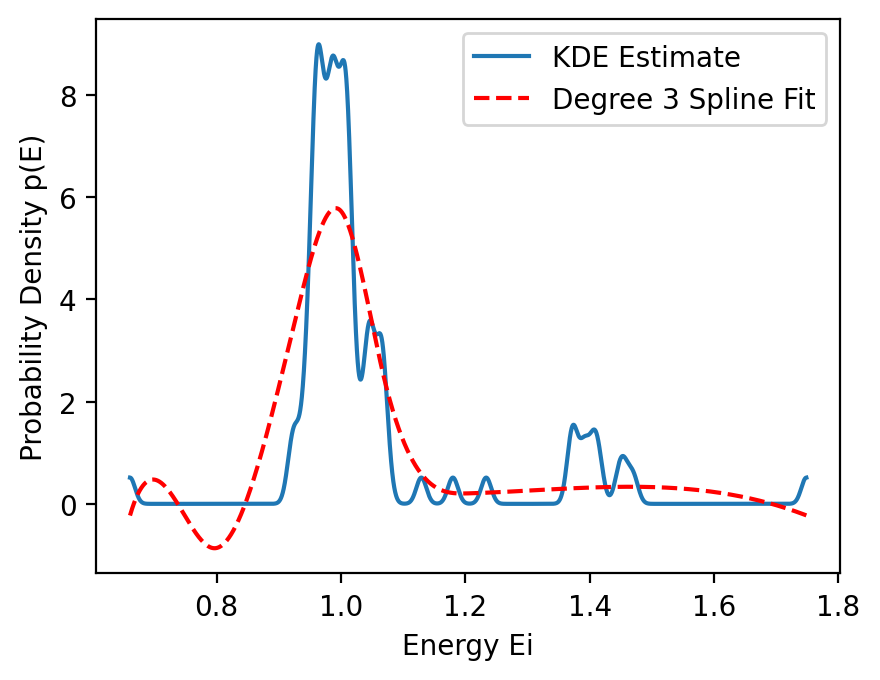

AIC for VISIT 19 with Degree 3 Spline fit (bandwidth=0.05): 8.12


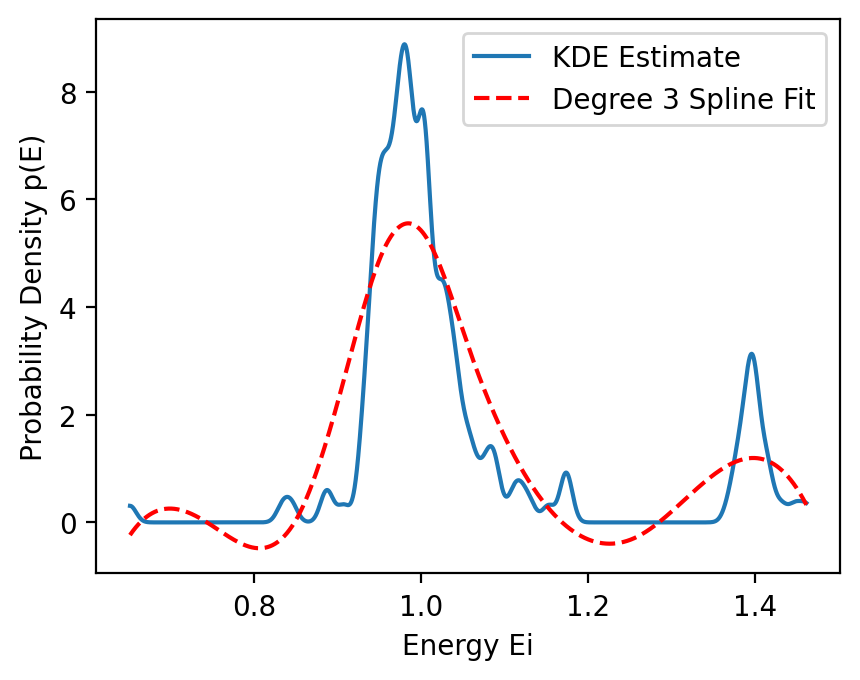

AIC for VISIT 20 with Degree 3 Spline fit (bandwidth=0.05): 9.89


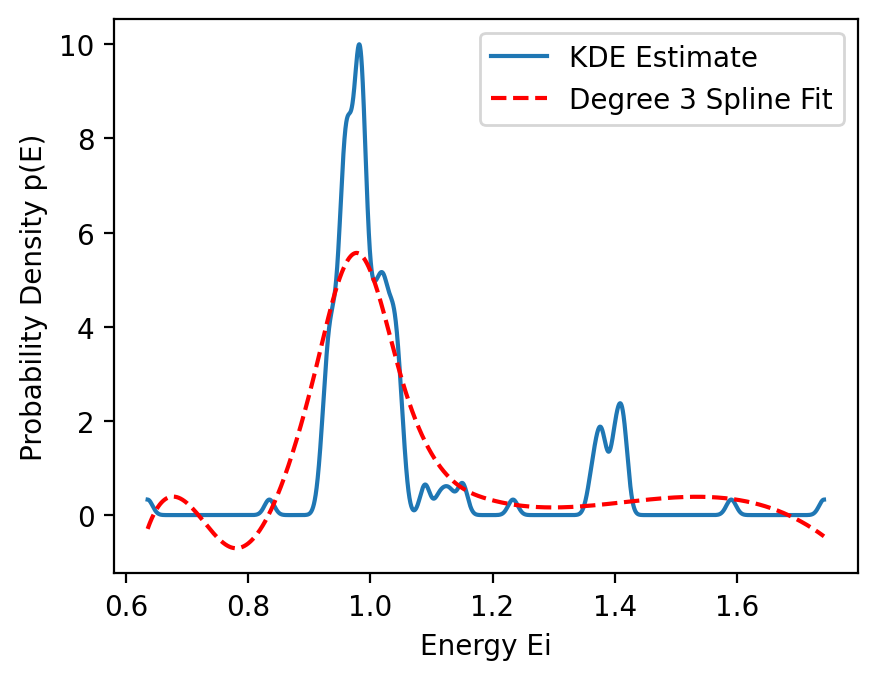

AIC for VISIT 21 with Degree 3 Spline fit (bandwidth=0.05): 8.57


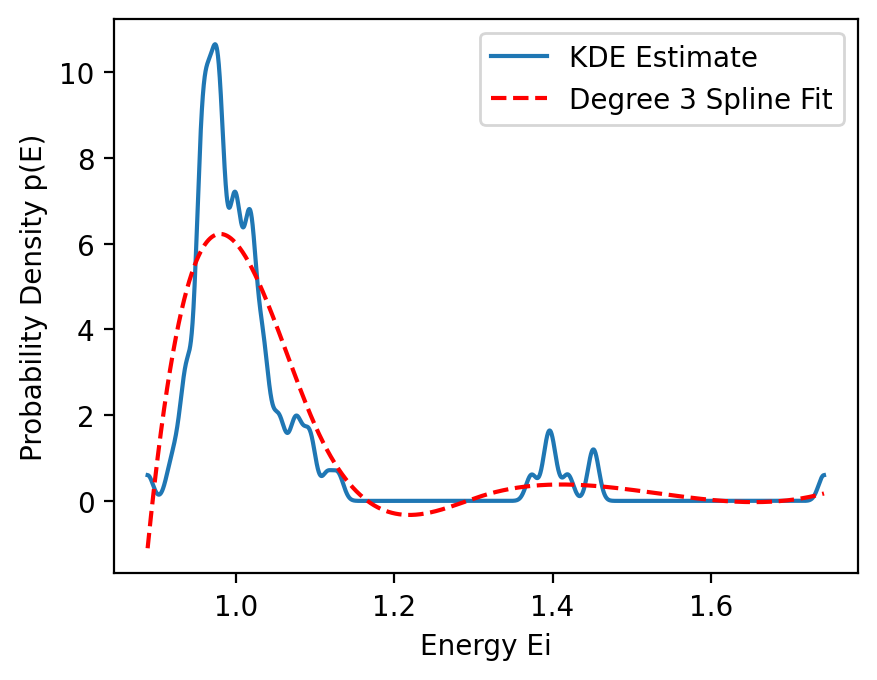

AIC for VISIT 22 with Degree 3 Spline fit (bandwidth=0.05): 5.32


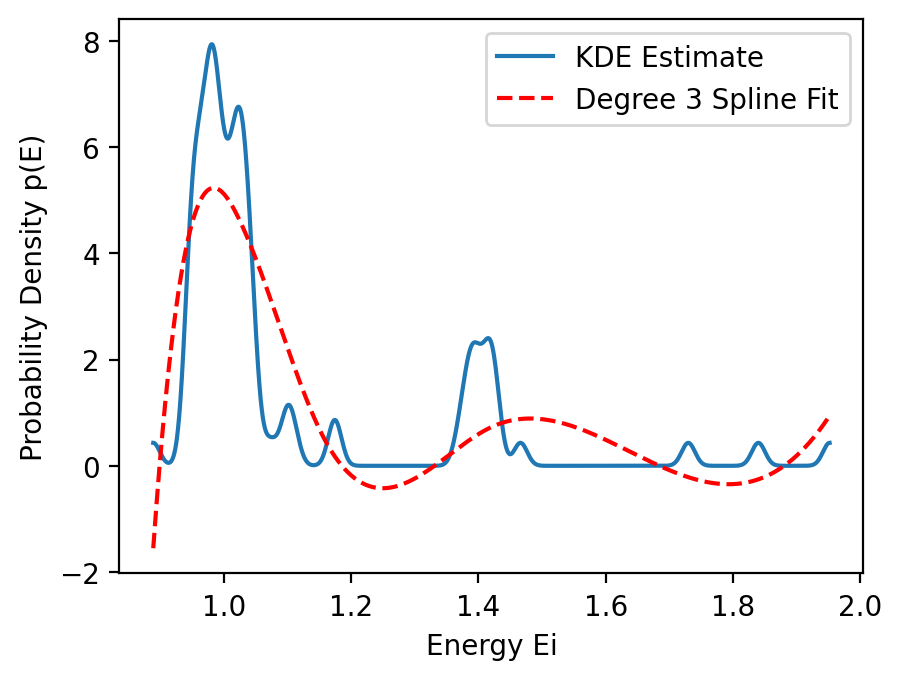

AIC for VISIT 23 with Degree 3 Spline fit (bandwidth=0.05): 5.75


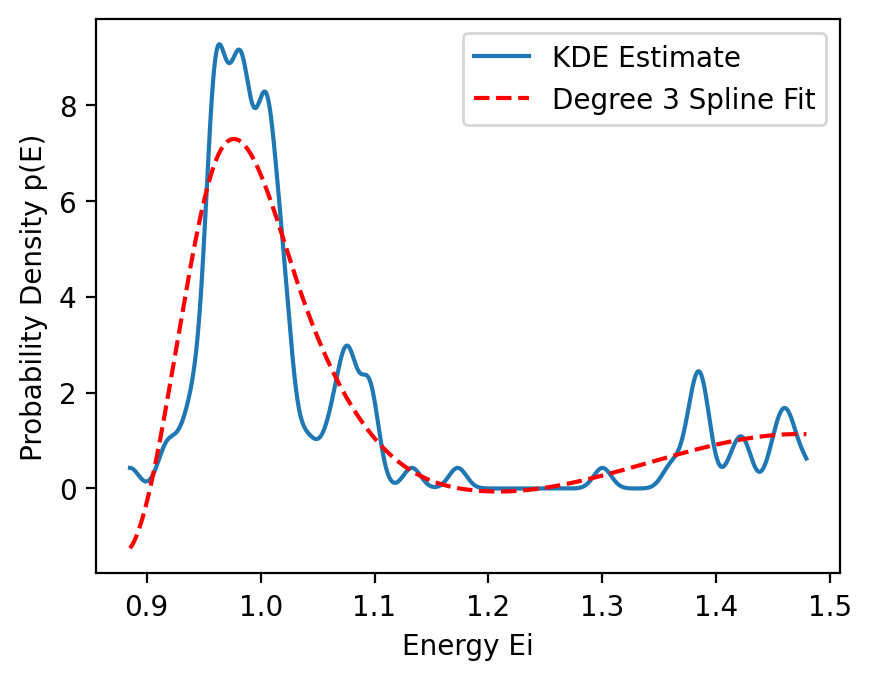

AIC for VISIT 24 with Degree 3 Spline fit (bandwidth=0.05): 12.81


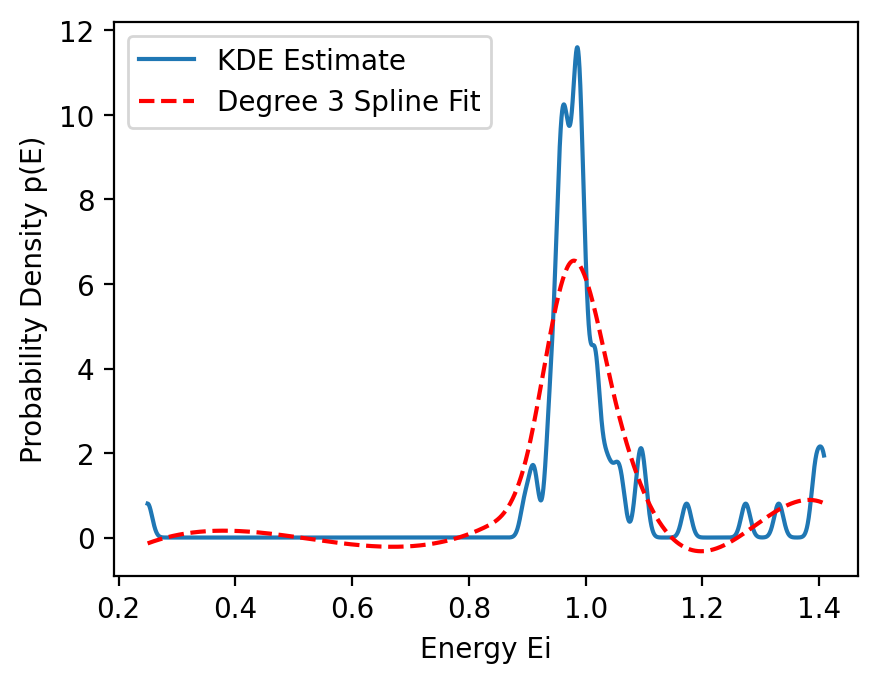

AIC for VISIT 25 with Degree 3 Spline fit (bandwidth=0.05): 8.98


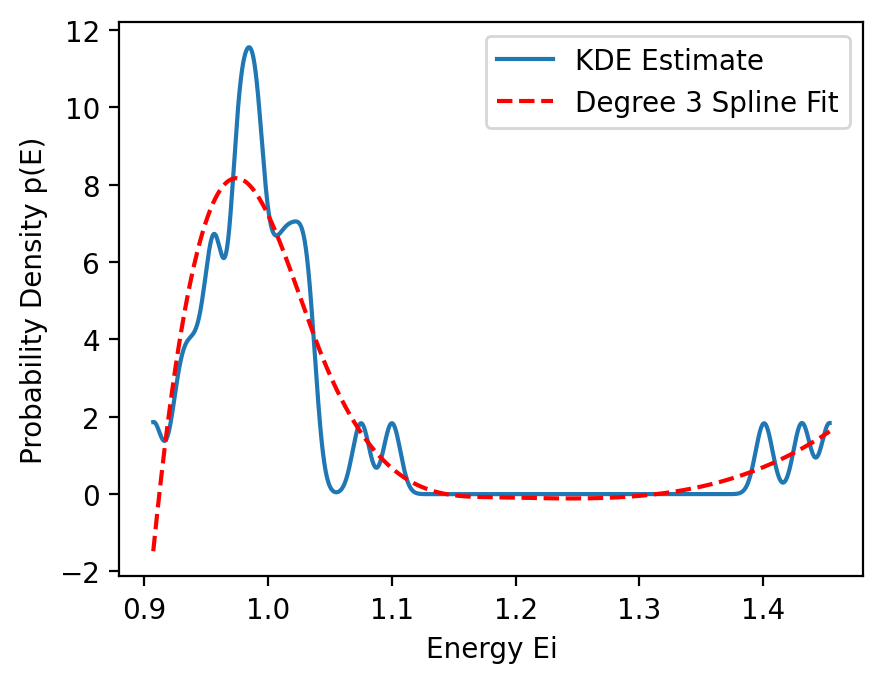

AIC for VISIT 26 with Degree 3 Spline fit (bandwidth=0.05): 7.54


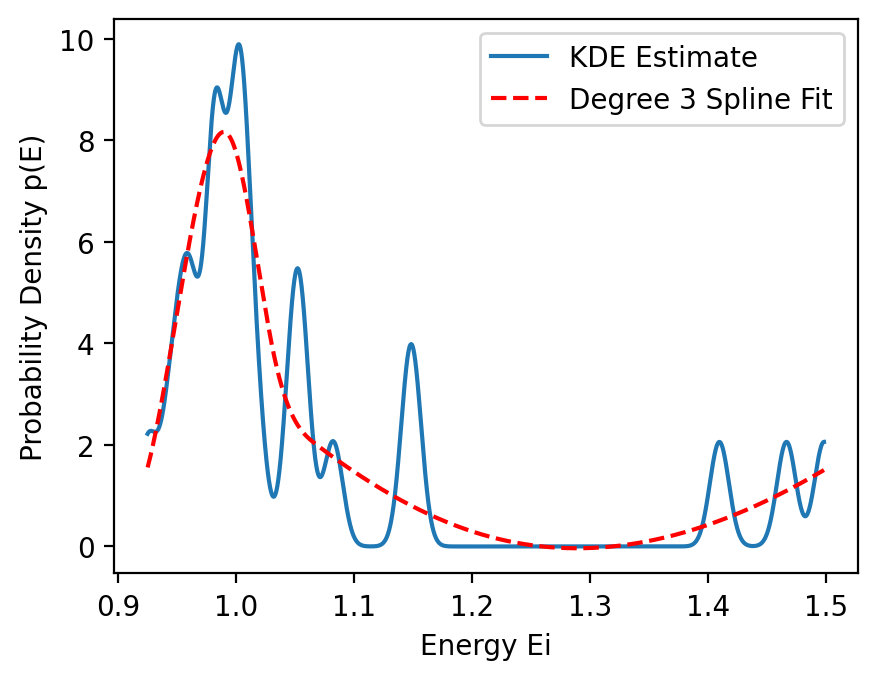

AIC for VISIT 27 with Degree 3 Spline fit (bandwidth=0.05): 9.38


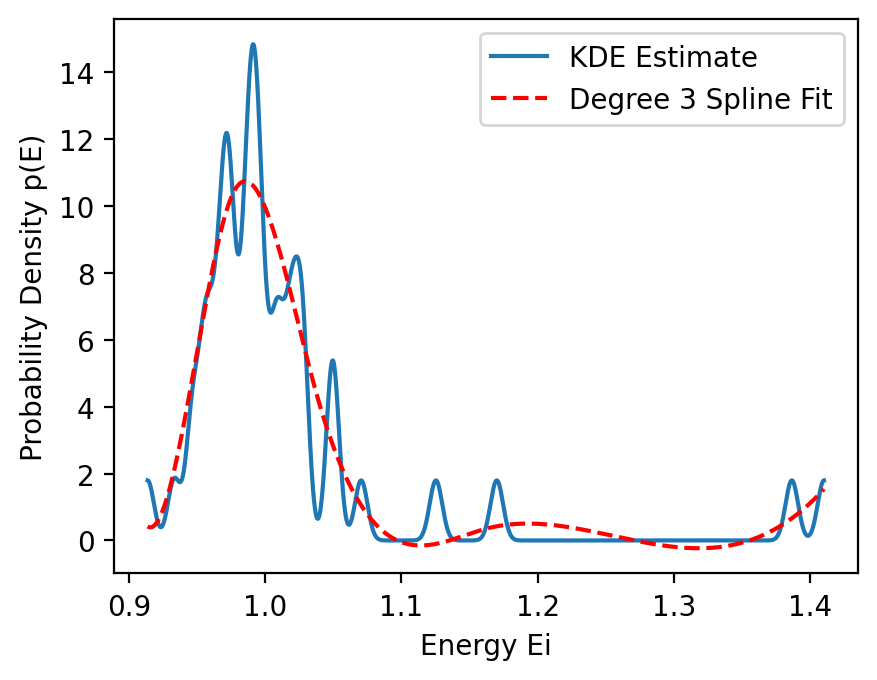

AIC for VISIT 28 with Degree 3 Spline fit (bandwidth=0.05): 5.36


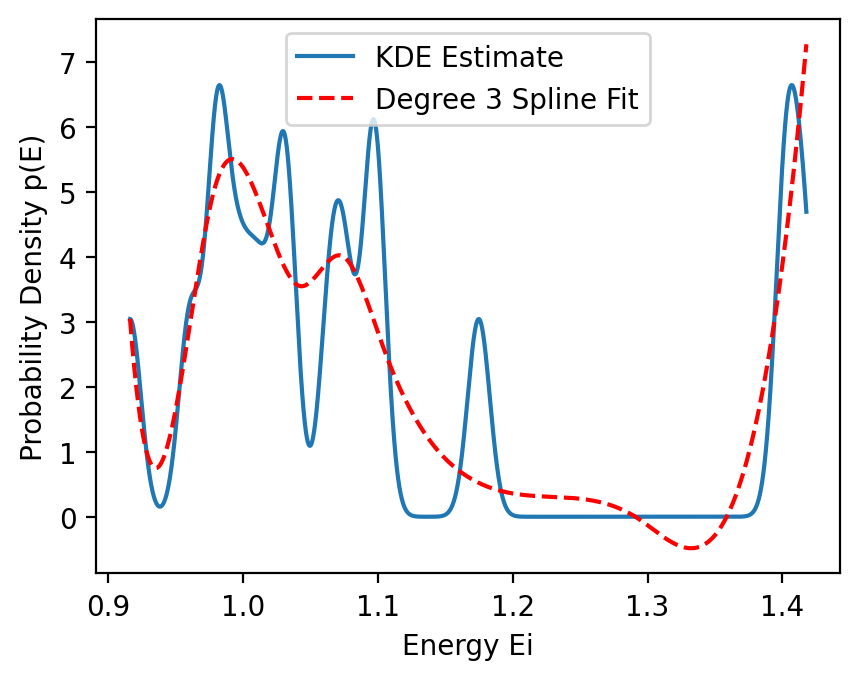

AIC for VISIT 29 with Degree 3 Spline fit (bandwidth=0.05): 5.28


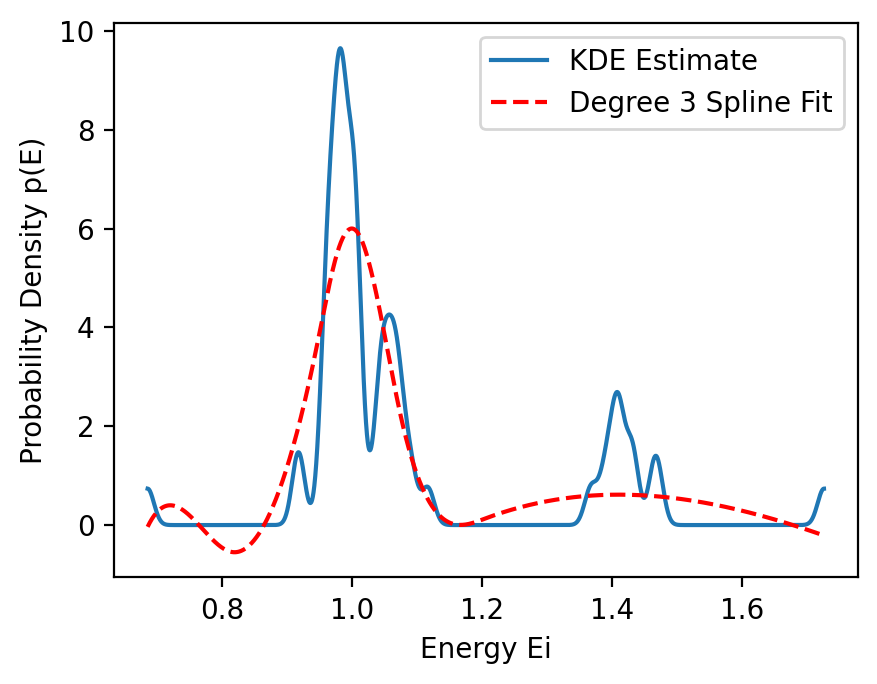

AIC for VISIT 30 with Degree 3 Spline fit (bandwidth=0.05): 8.19


In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data, return None
    if len(df_filtered) < 2:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 3 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=3)
    
    # 5. Compute AIC for the spline fit
    n = len(energy_range)
    rss = np.sum((spline(energy_range) - kde_values)**2)
    aic = n * np.log(rss/n) + 2*4 # Degree 3 spline has 4 parameters
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline(energy_range), 'r--', label='Degree 3 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline, aic

# Iterate over visits from 10 to 30 and print AIC
for visit in range(10, 31):
    _, aic = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, bandwidth=0.05)
    if aic is not None:
        print(f"AIC for VISIT {visit} with Degree 3 Spline fit (bandwidth=0.05): {aic:.2f}")
    else:
        print(f"VISIT {visit} skipped due to insufficient data.")


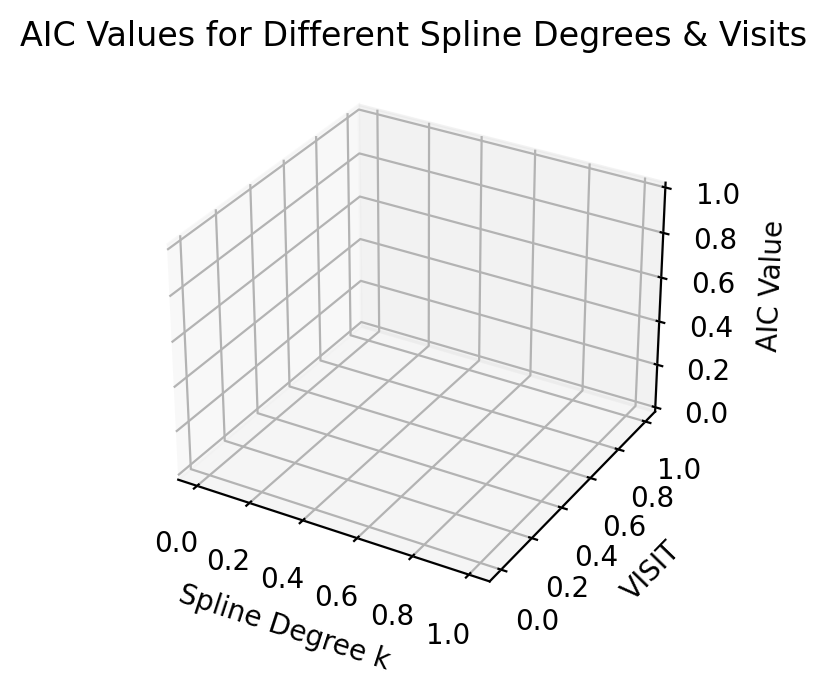

In [3]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_aic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large AIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    aic = n * np.log(sse/n) + 2 * k_params
    return aic

visits = list(range(15,15))
degrees = list(range(1, 6))
aic_values = np.zeros((len(visits), len(degrees)))

for i, visit in enumerate(visits):
    for j, degree in enumerate(degrees):
        aic_values[i, j] = get_aic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05)

X, Y = np.meshgrid(degrees, visits)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter plot instead of surface plot
ax.scatter(X, Y, aic_values, c='r', marker='o')

ax.set_xlabel('Spline Degree k')
ax.set_ylabel('VISIT')
ax.set_zlabel('AIC Value')
ax.set_title('AIC Values for Different Spline Degrees & Visits')
plt.show()


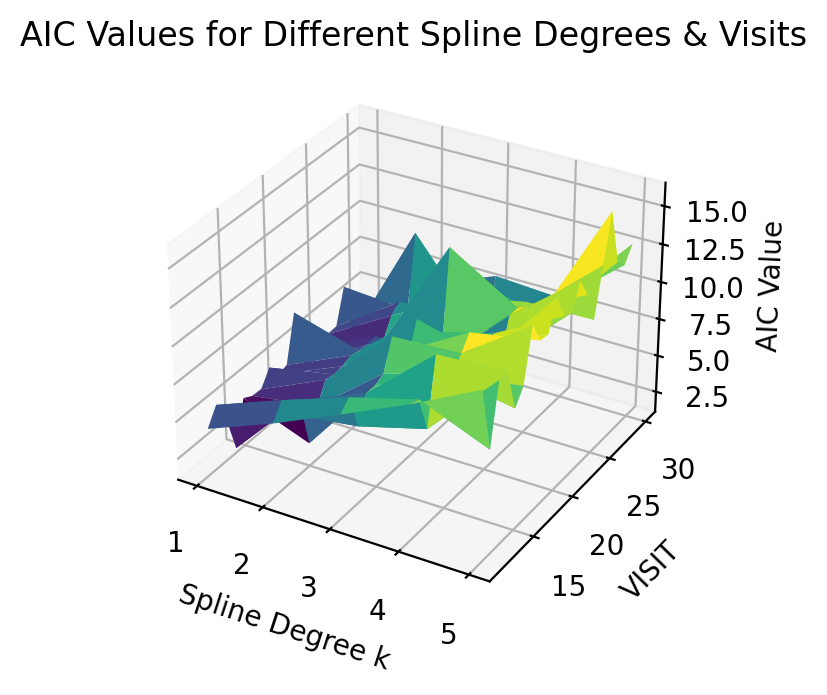

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_aic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large AIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    aic = n * np.log(sse/n) + 2 * k_params
    return aic

visits = list(range(11, 31))
degrees = list(range(1, 6))
aic_values = np.zeros((len(visits), len(degrees)))

for i, visit in enumerate(visits):
    for j, degree in enumerate(degrees):
        aic_values[i, j] = get_aic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05)

X, Y = np.meshgrid(degrees, visits)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, aic_values, cmap='viridis')
ax.set_xlabel('Spline Degree k')
ax.set_ylabel('VISIT')
ax.set_zlabel('AIC Value')
ax.set_title('AIC Values for Different Spline Degrees & Visits')
plt.show()


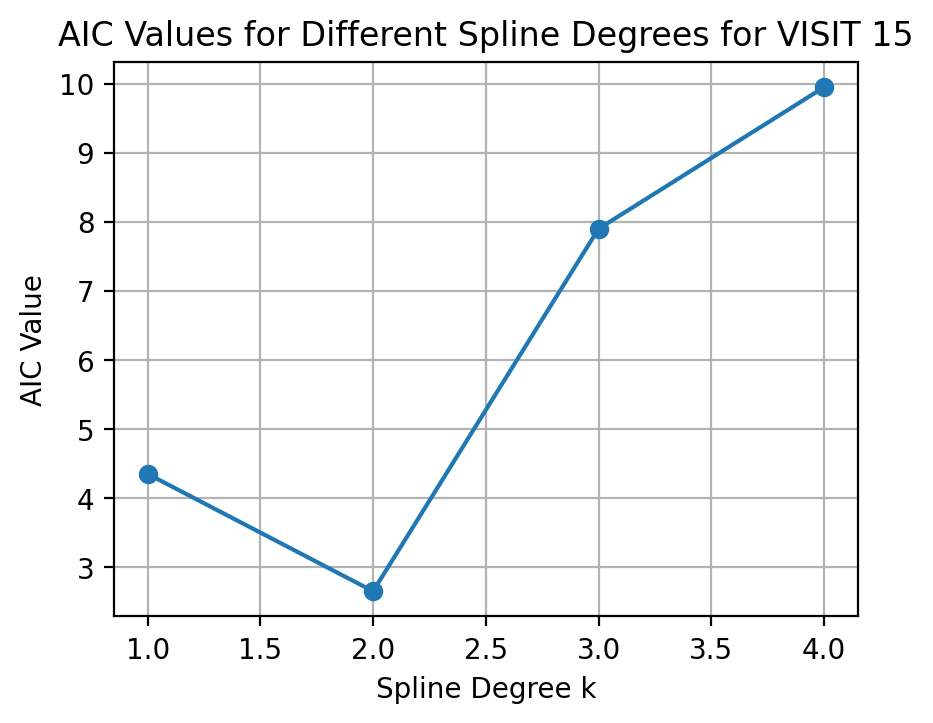

In [2]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_aic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large AIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    aic = n * np.log(sse/n) + 2 * k_params
    return aic

# For visit 15
visit = 15
degrees = list(range(1, 5))
aic_values = [get_aic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05) for degree in degrees]

plt.plot(degrees, aic_values, marker='o', linestyle='-')
plt.xlabel('Spline Degree k')
plt.ylabel('AIC Value')
plt.title(f'AIC Values for Different Spline Degrees for VISIT {visit}')
plt.grid(True)
plt.show()


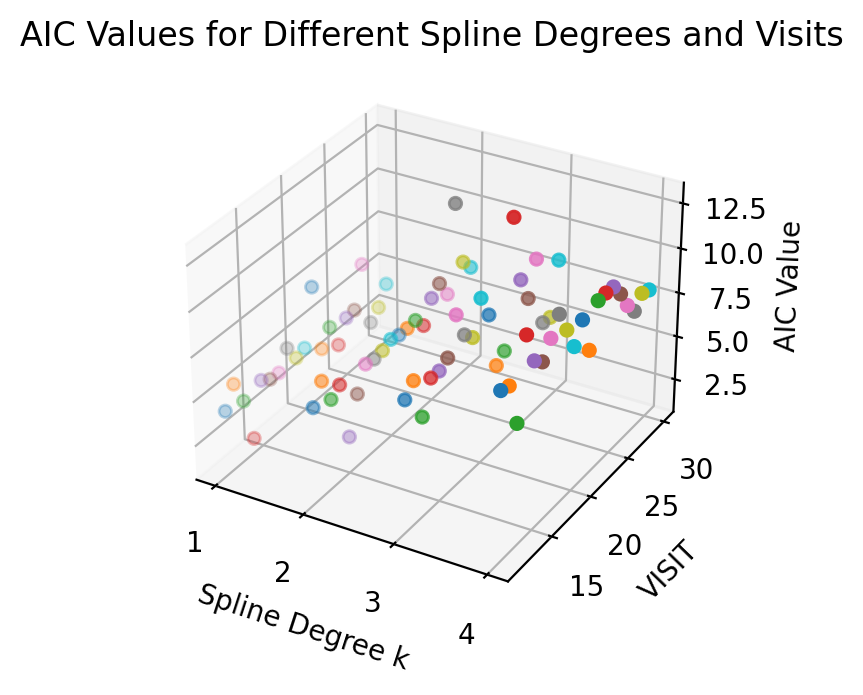

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def get_aic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large AIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    aic = n * np.log(sse/n) + 2 * k_params
    return aic

degrees = list(range(1, 5))
visits = list(range(11, 31))
aic_values = []

for visit in visits:
    aic_for_visit = [get_aic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05) for degree in degrees]
    aic_values.append(aic_for_visit)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
for i, visit in enumerate(visits):
    ax.scatter(degrees, [visit] * len(degrees), aic_values[i])

ax.set_xlabel('Spline Degree k')
ax.set_ylabel('VISIT')
ax.set_zlabel('AIC Value')
ax.set_title('AIC Values for Different Spline Degrees and Visits')
plt.show()


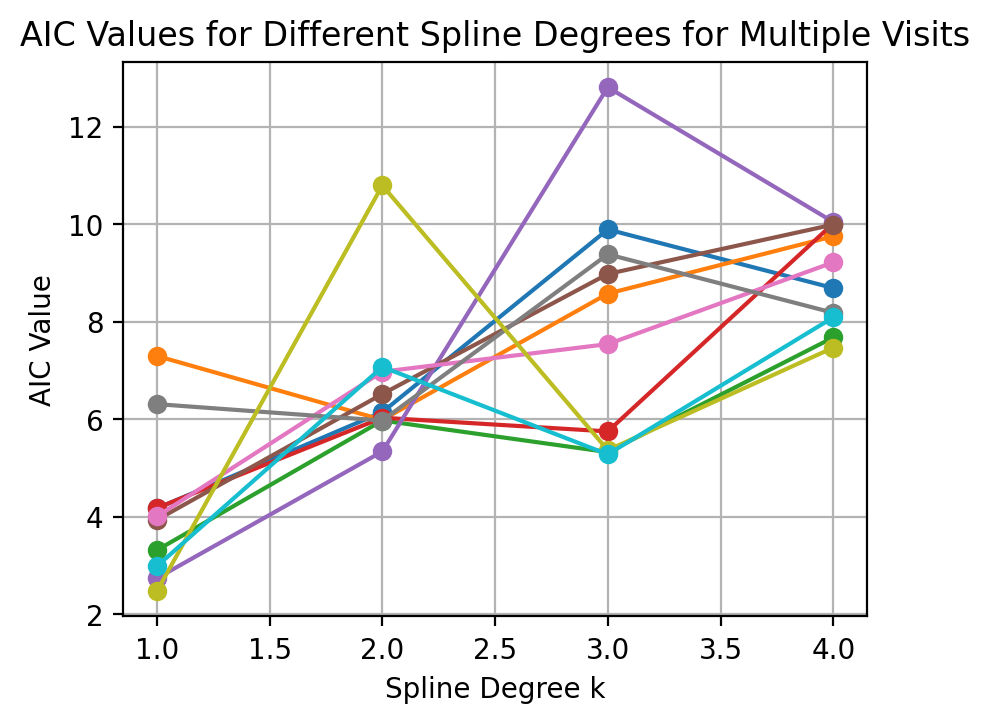

In [3]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_aic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large AIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    aic = n * np.log(sse/n) + 2 * k_params
    return aic

# List of visits to plot
visits_to_plot = list(range(20, 30))
degrees = list(range(1, 5))  # Changed range to include degree 5

for visit in visits_to_plot:
    aic_values = [get_aic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05) for degree in degrees]
    plt.plot(degrees, aic_values, marker='o', linestyle='-', label=f"VISIT {visit}")

plt.xlabel('Spline Degree k')
plt.ylabel('AIC Value')
plt.title(f'AIC Values for Different Spline Degrees for Multiple Visits')
#plt.legend()
plt.grid(True)
plt.show()


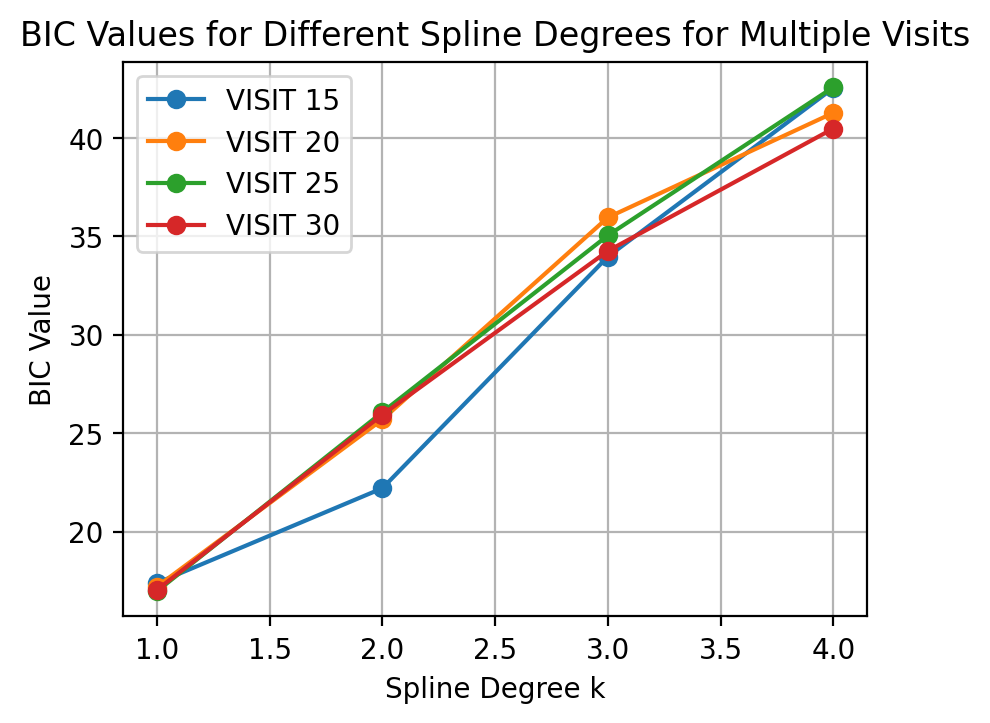

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_bic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large BIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    bic = n * np.log(sse/n) + k_params * np.log(n)
    return bic

# List of visits to plot
visits_to_plot = [15, 20, 25, 30]
degrees = list(range(1, 5))  # Changed range to include degree 5

for visit in visits_to_plot:
    bic_values = [get_bic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05) for degree in degrees]
    plt.plot(degrees, bic_values, marker='o', linestyle='-', label=f"VISIT {visit}")

plt.xlabel('Spline Degree k')
plt.ylabel('BIC Value')
plt.title(f'BIC Values for Different Spline Degrees for Multiple Visits')
plt.legend()
plt.grid(True)
plt.show()


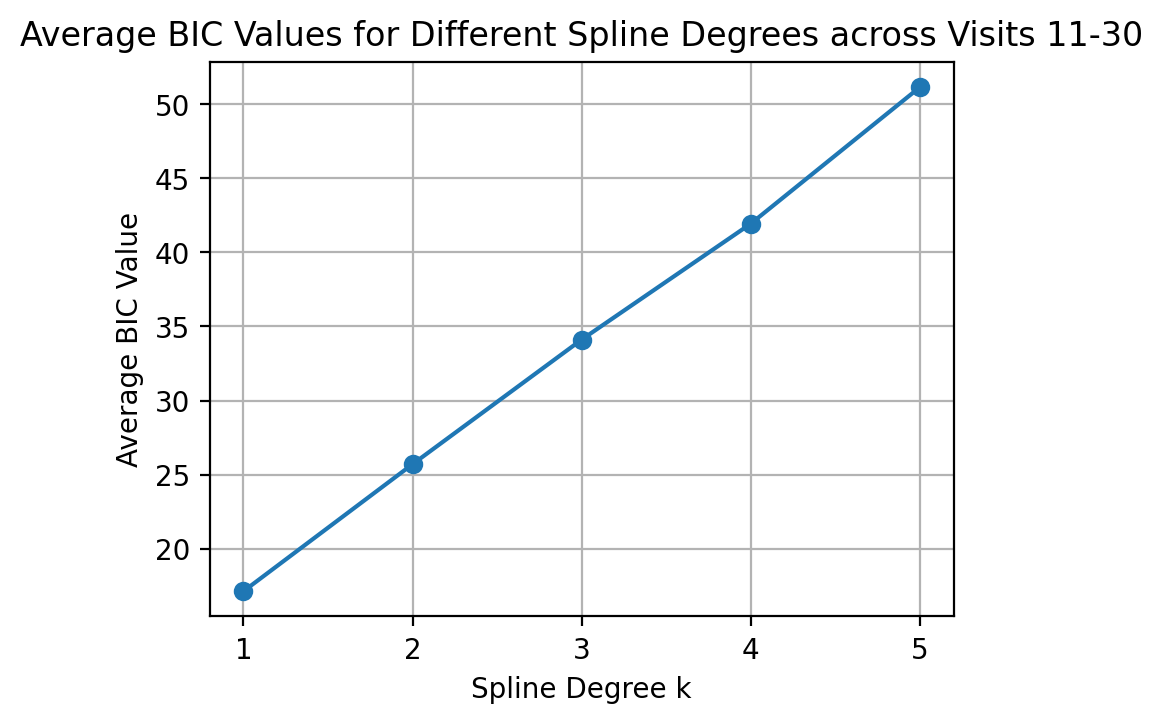

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_bic(file_name, drug, visit, degree, bandwidth=None):
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values
    if len(energy_values) <= degree:
        return np.inf  # returning a large BIC for cases with insufficient data points
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    spline = UnivariateSpline(energy_range, kde_values, k=degree)
    residuals = kde_values - spline(energy_range)
    sse = np.sum(residuals**2)
    n = len(energy_range)
    k_params = degree + 1
    bic = n * np.log(sse/n) + k_params * np.log(n)
    return bic

# List of visits to calculate the average BIC
visits_to_average = [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
degrees = list(range(1, 6))

average_bic_values = []

for degree in degrees:
    bic_sum = sum([get_bic("Normalised_Bootstrap_for_temp.xlsx", "NRTI", visit, degree, bandwidth=0.05) for visit in visits_to_average])
    average_bic = bic_sum / len(visits_to_average)
    average_bic_values.append(average_bic)

plt.plot(degrees, average_bic_values, marker='o', linestyle='-')
plt.xlabel('Spline Degree k')
plt.ylabel('Average BIC Value')
plt.title(f'Average BIC Values for Different Spline Degrees across Visits 11-30')
plt.grid(True)
plt.show()


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data, return None
    if len(df_filtered) < 2:
        return None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    
    # Compute the cumulative sum of the KDE values
    cdf_values = np.cumsum(kde_values)
    # Normalize the CDF
    cdf_values /= cdf_values[-1]
    
    # 4. Fit a B-spline of degree 3 to the CDF results
    spline = UnivariateSpline(energy_range, cdf_values, k=3)
    
    return spline


In [4]:
spline_func = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 20)
energy_value=1.2
if spline_func:
    p_E = spline_func(energy_value)  # Replace 'energy_value' with the desired energy value
    print(f"The probability for energy value {energy_value} is: {p_E}")
else:
    print("Not enough data for the given visit.")


The probability for energy value 1.2 is: 0.8921251316522587


In [1]:
def compute_entropy(spline, e_min=0.1, e_max=1.5):
    # Derive the PDF from the CDF spline
    pdf = spline.derivative(n=1)
    
    # Plotting the PDF for visual inspection
    E_values = np.linspace(e_min, e_max, 1000)
    plt.plot(E_values, pdf(E_values))
    plt.title("PDF derived from spline")
    plt.show()
    
    # Define the entropy integrand
    def integrand(E):
        prob_density = pdf(E)
        # If probability density is too close to 0, avoid computing log(prob_density)
        if prob_density < 1e-10:
            return 0
        return -prob_density * np.log(prob_density)
    
    # Compute the entropy using numerical integration
    entropy, _ = quad(integrand, e_min, e_max)
    return entropy


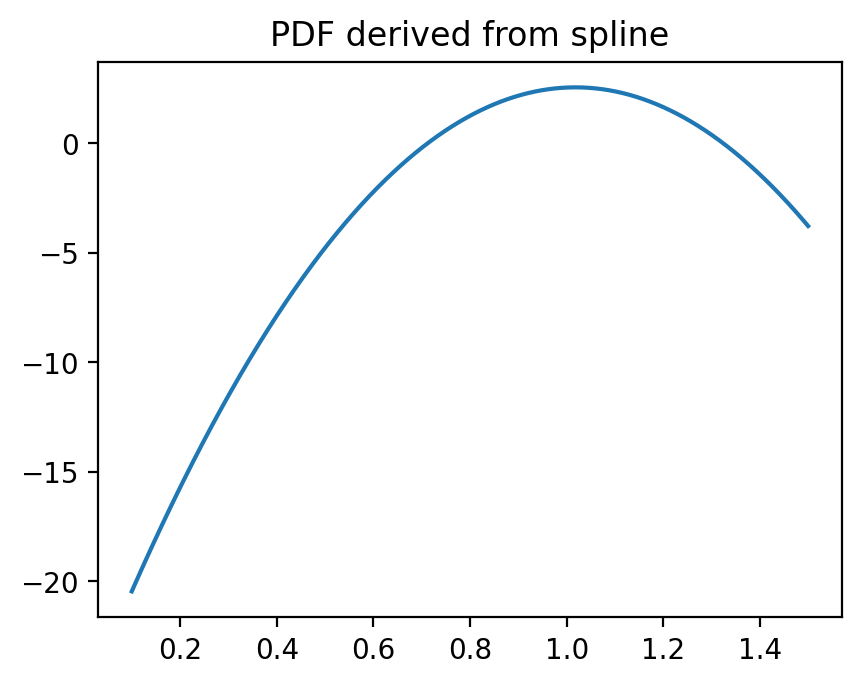

Entropy: -0.68284


<ipython-input-1-8003f8189b72>:20: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  entropy, _ = quad(integrand, e_min, e_max)


In [2]:
spline = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 20)
if spline:
    entropy_value = compute_entropy(spline)
    print(f"Entropy: {entropy_value:.5f}")

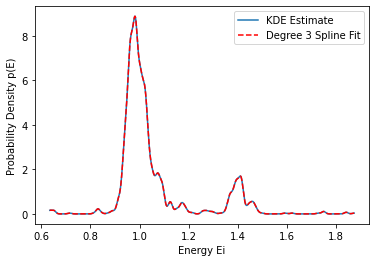

Entropy for VISIT 15: -1.24


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_2317/1802482172.py:17: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  entropy, _ = quad(integrand, e_min, e_max)


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt
from scipy.integrate import quad

def entropy_from_pdf(spline, e_min, e_max):
    """Compute entropy from a given probability density function represented as a spline."""
    def integrand(E):
        p_E = spline(E)
        # Ensure that p_E is not negative and not too close to zero
        p_E = max(p_E, 0.001)
        return -p_E * np.log(p_E)

    # Integrate to compute entropy
    entropy, _ = quad(integrand, e_min, e_max)
    return entropy

def get_energy_spline_function(file_name, drug, visit, bandwidth=None):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # If not enough data, return None
    if len(df_filtered) < 2:
        return None, None
    
    # 3. Use KDE to estimate a continuous probability distribution with specified bandwidth
    energy_values = df_filtered["Energy Ei"].values
    kde = gaussian_kde(energy_values, bw_method=bandwidth)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 5000)
    kde_values = kde(energy_range)
    
    # 4. Fit a B-spline of degree 3 to the KDE results
    spline = UnivariateSpline(energy_range, kde_values, k=3, s=0)
    spline_values = np.maximum(spline(energy_range), 0.001)
    
    # 6. Plot the KDE and the spline fit
    plt.plot(energy_range, kde_values, label='KDE Estimate')
    plt.plot(energy_range, spline_values, 'r--', label='Degree 3 Spline Fit')
    plt.xlabel('Energy Ei')
    plt.ylabel('Probability Density p(E)')
    plt.legend()
    plt.show()
    
    return spline

# Example usage:
spline = get_energy_spline_function("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 15, bandwidth=0.05)
if spline is not None:
    e_min = 0.1
    e_max = 1.5
    entropy = entropy_from_pdf(spline, e_min, e_max)
    print(f"Entropy for VISIT 15: {entropy:.2f}")


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

def get_energy_probability_density(file_name, drug, visit, n_components=2):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    # 3. Use GMM to fit a sum of Gaussians
    energy_values = df_filtered["Energy Ei"].values.reshape(-1, 1)
    gmm = GaussianMixture(n_components=n_components).fit(energy_values)
    
    # 4. Create a callable function for p(E)
    def p(E):
        return np.exp(gmm.score_samples(E.reshape(-1, 1)))
    
    # Example: Plotting the GMM result
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000).reshape(-1, 1)
    #plt.plot(energy_range, np.exp(gmm.score_samples(energy_range)))
    #plt.xlabel('Energy Ei')
    #plt.ylabel('Probability Density p(E)')
    #plt.show()
    
    return p

# Example usage:
energy_func = get_energy_probability_density("Normalised_Bootstrap_for_temp.xlsx", "NRTI", 15, n_components=2)
print(energy_func(np.array([0.5])))  # This will give p(E) for E=0.5


[1.41619028e-15]


In [5]:
from scipy.integrate import quad

def get_probability_for_energy(file_name, drug, visit, energy, n_components=3):
    energy_func = get_energy_probability_density(file_name, drug, visit, n_components)
    return energy_func(np.array([energy]))[0]

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
energy = 1
probability = get_probability_for_energy(file_name, drug, visit, energy, n_components=3)
print(f"The probability for Ei={energy} is: {probability}")

The probability for Ei=1 is: 8.295325617574667


In [19]:
import numpy as np

def get_entropy_for_visit(file_name, drug, visit, e_min=0.7, e_max=1.5, n_components=3):
    tmp = 0
    for Ei in np.linspace(e_min, e_max, 10):  # Here, we're using linspace instead of range
        pi = get_probability_for_energy(file_name, drug, visit, Ei, n_components=n_components)
        if pi > 1e-10:  # Adding a condition to prevent log(0)
            print(pi)

    return tmp 

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
entropy = get_entropy_for_visit(file_name, drug, visit)
print(f"Entropy for visit {visit}: {entropy:.2f}")


0.010417402243247652
0.06741506005429619
0.2992744978412855
6.988903226660086
1.8770177940558423
0.3805503131292922
0.20881653564370295
0.3664290366132498
0.562899262961659
0.3645032040020538
Entropy for visit 15: 0.00


In [6]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

def get_probability_for_energy(file_name, drug, visit, Ei, n_components=3):
    # Load and filter the data
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values.reshape(-1, 1)

    # Fit the GMM
    gmm = GaussianMixture(n_components=n_components)
    gmm.fit(energy_values)
    
    # Predict the probability density
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000).reshape(-1, 1)
    pdf_values = np.exp(gmm.score_samples(energy_range))
    
    # Normalize the predicted values to [0,1]
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    # Create interpolation function for the normalized pdf
    from scipy.interpolate import interp1d
    f = interp1d(energy_range.ravel(), pdf_values_normalized.ravel(), kind='linear', fill_value=0, bounds_error=False)

    return f(Ei)

def get_entropy_for_visit(file_name, drug, visit, e_min=0.7, e_max=1.5, n_components=3):
    tmp = 0
    for Ei in np.linspace(e_min, e_max, 100):
        pi = get_probability_for_energy(file_name, drug, visit, Ei, n_components=n_components)
        if pi > 1e-10:
            tmp += -pi * np.log(pi)
    return tmp 

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
entropy = get_entropy_for_visit(file_name, drug, visit)
print(f"Entropy for visit {visit}: {entropy:.2f}")


Entropy for visit 15: 14.23


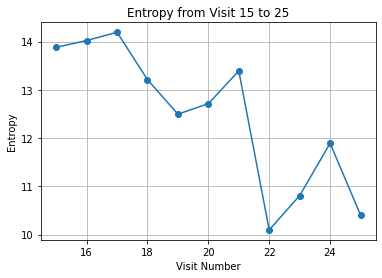

In [7]:
visits = list(range(15, 26))
entropies = [get_entropy_for_visit(file_name, drug, visit) for visit in visits]

# Plot the results
plt.plot(visits, entropies, '-o')
plt.xlabel('Visit Number')
plt.ylabel('Entropy')
plt.title('Entropy from Visit 15 to 25')
plt.grid(True)
plt.show()

In [2]:
from scipy.integrate import quad

from sklearn.mixture import GaussianMixture
import numpy as np

def get_probability_for_energy(file_name, drug, visit, E, n_components=3):
    # Load and filter the data
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values.reshape(-1, 1)

    # Fit the GMM
    gmm = GaussianMixture(n_components=n_components)
    gmm.fit(energy_values)
    
    # Predict the probability density
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000).reshape(-1, 1)
    pdf_values = np.exp(gmm.score_samples(energy_range))
    
    # Normalize the predicted values to [0,1]
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    # Create interpolation function for the normalized pdf
    from scipy.interpolate import interp1d
    f = interp1d(energy_range.ravel(), pdf_values_normalized.ravel(), kind='linear', fill_value=0, bounds_error=False)

    return gmm.predict_proba(np.array([[E]]))[0][1]

def get_probability_derivative(E, prob_func, delta=1e-5):
    """
    Compute the numerical derivative of the probability function at E.
    """
    return (prob_func(E + delta) - prob_func(E - delta)) / (2 * delta)

def compute_temperature_integral(E, prob_func):
    """
    The integrand for the temperature integral.
    """
    pE = prob_func(E)
    dpE = get_probability_derivative(E, prob_func)
    # Ensure that pE is not very close to zero to avoid computation issues
    if pE < 1e-10:
        return 0
    return -dpE * np.log(pE)

def get_temperature(file_name, drug, visit, e_min=0.7, e_max=1.5, n_components=3):
    prob_func = get_probability_for_energy(file_name, drug, visit, n_components)
    integral_value, _ = quad(compute_temperature_integral, e_min, e_max, args=(prob_func,))
    return 1 / integral_value

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
temperature = get_temperature(file_name, drug, visit)
print(f"Temperature for visit {visit}: {temperature:.2f}")


NameError: name 'pd' is not defined

In [10]:
from scipy.integrate import quad

from sklearn.mixture import GaussianMixture
import numpy as np


def get_temperature(e_min,e_max,file_name, drug, visit):
    tmp = 0
    for Ei in np.linspace(e_min, e_max, 100):
        DE = (e_max - e_min)/100
        tmp = tmp + ((get_probability_for_energy(file_name, drug, visit,Ei , n_components=3))+(get_probability_for_energy(file_name, drug, visit,Ei + DE, n_components=3)))*(DE)/2

    return tmp

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
temperature = get_temperature(0.7, 1.6,file_name, drug, visit)
print(f"Temperature for visit {visit}: {temperature:.2f}")


Temperature for visit 15: 0.12


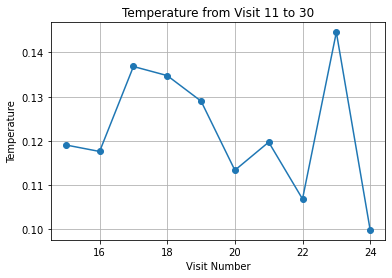

In [11]:
visits = list(range(15,25))
temperatureplot = [get_temperature(0.7,1.6,file_name, drug, visit) for visit in visits]

# Plot the results
plt.plot(visits, temperatureplot, '-o')
plt.xlabel('Visit Number')
plt.ylabel('Temperature')
plt.title('Temperature from Visit 11 to 30')
plt.grid(True)
plt.show()

In [13]:
def generate_probability_function(file_name, drug, visit, n_components=3):
    # Load and filter the data
    df = pd.read_excel(file_name, sheet_name=drug)
    df_filtered = df[df['VISIT'] == visit]
    energy_values = df_filtered["Energy Ei"].values.reshape(-1, 1)

    # Fit the GMM
    gmm = GaussianMixture(n_components=n_components)
    gmm.fit(energy_values)

    # Predict the probability density
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000).reshape(-1, 1)
    pdf_values = np.exp(gmm.score_samples(energy_range))
    
    # Normalize the predicted values to [0,1]
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    # Create interpolation function for the normalized pdf
    from scipy.interpolate import interp1d
    f = interp1d(energy_range.ravel(), pdf_values_normalized.ravel(), kind='linear', fill_value=0, bounds_error=False)

    return f

def compute_internal_energy_integral(E, prob_func):
    """
    The integrand for the internal energy integral.
    """
    pE = prob_func(E)
    return pE * E

def get_internal_energy(file_name, drug, visit, e_min=0.7, e_max=1.5, n_components=3):
    prob_func = generate_probability_function(file_name, drug, visit, n_components)
    internal_energy, _ = quad(compute_internal_energy_integral, e_min, e_max, args=(prob_func,))
    return internal_energy

# Example usage:
file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
visit = 15
internal_energy = get_internal_energy(file_name, drug, visit)
print(f"Internal Energy for visit {visit}: {internal_energy:.2f}")


Internal Energy for visit 15: 0.12


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_2317/1332569004.py:33: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  internal_energy, _ = quad(compute_internal_energy_integral, e_min, e_max, args=(prob_func,))


/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_2317/1332569004.py:33: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  internal_energy, _ = quad(compute_internal_energy_integral, e_min, e_max, args=(prob_func,))
/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_2317/1332569004.py:33: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  internal_energy, _ = quad(compute_internal_energy_integral, e_min, e_max, args=(prob_func,))
/var/folders/j8/z8l9f8w

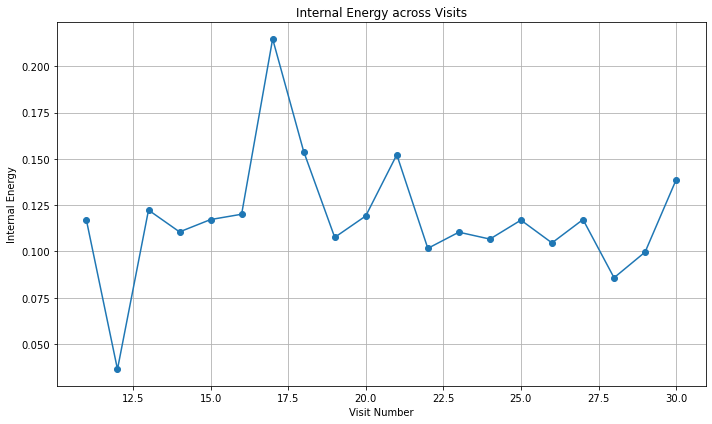

In [14]:
import matplotlib.pyplot as plt

# Assuming the previous functions are already defined

# Range of visits
visits = list(range(11, 31))
internal_energies = []

# Compute the internal energy for each visit
for visit in visits:
    internal_energy = get_internal_energy(file_name, drug, visit)
    internal_energies.append(internal_energy)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(visits, internal_energies, marker='o', linestyle='-')
plt.title('Internal Energy across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Internal Energy')
plt.grid(True)
plt.tight_layout()
plt.show()


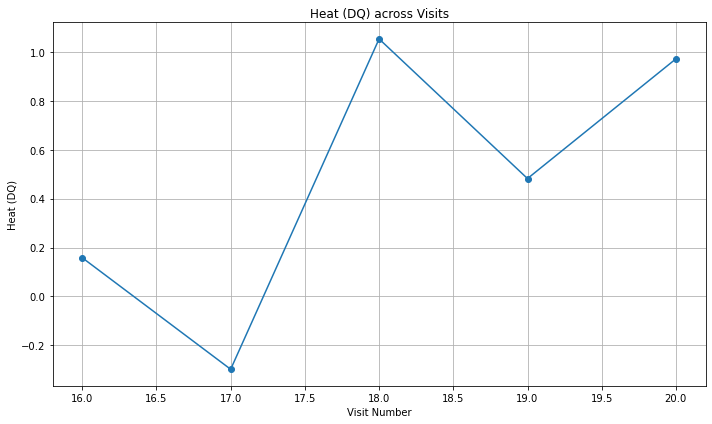

In [17]:
import matplotlib.pyplot as plt

# Assuming the functions get_temperature and get_entropy are already defined

def calculate_heat(file_name, drug, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    # 1. Compute the temperature and entropy for each visit
    for visit in range(visit_start, visit_end + 1):
        temperatures.append(get_temperature(e_min,e_max,file_name, drug, visit))
        entropies.append(get_entropy_for_visit(file_name, drug, visit))

    # 2. Compute DQ for each visit, starting from the second visit in the list
    for i in range(1, len(temperatures)):
        mean_log_temp = (np.log(temperatures[i]) + np.log(temperatures[i-1])) / 2
        entropy_diff = entropies[i] - entropies[i-1]
        DQ = mean_log_temp * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

# Specifying the range of visits
visit_start = 15
visit_end = 20

heat_values = calculate_heat(file_name, drug, visit_start, visit_end)

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


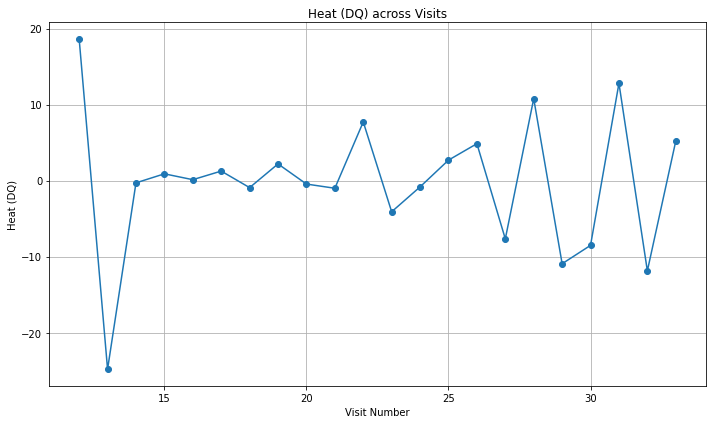

In [19]:
import matplotlib.pyplot as plt

# Assuming the functions get_temperature and get_entropy are already defined

def calculate_heat(file_name, drug, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    # 1. Compute the temperature and entropy for each visit
    for visit in range(visit_start, visit_end + 1):
        temperatures.append(get_temperature(e_min,e_max,file_name, drug, visit))
        entropies.append(get_entropy_for_visit(file_name, drug, visit))

    # 2. Compute DQ for each visit, starting from the second visit in the list
    for i in range(1, len(temperatures)):
        mean_log_temp = (np.log(temperatures[i]) + np.log(temperatures[i-1])) / 2
        entropy_diff = entropies[i] - entropies[i-1]
        DQ = mean_log_temp * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

# Specifying the range of visits
visit_start = 11
visit_end = 33

heat_values = calculate_heat(file_name, drug, visit_start, visit_end)

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


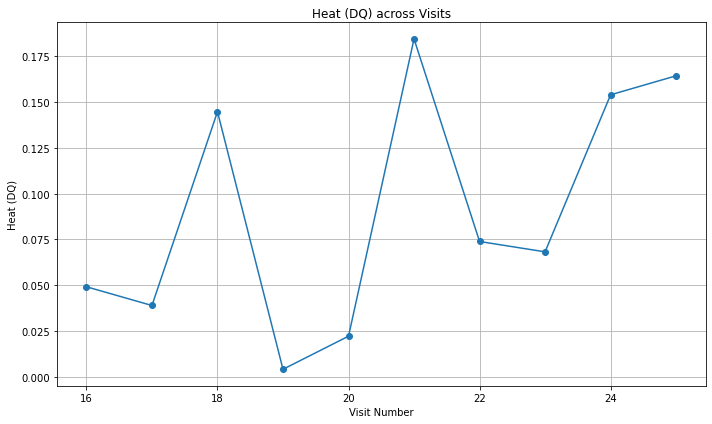

In [25]:
import matplotlib.pyplot as plt

# Assuming the functions get_temperature and get_entropy are already defined

def calculate_heat(file_name, drug, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    # 1. Compute the temperature and entropy for each visit
    for visit in range(visit_start, visit_end + 1):
        temperatures.append(get_temperature(e_min,e_max,file_name, drug, visit))
        entropies.append(get_entropy_for_visit(file_name, drug, visit))

    # 2. Compute DQ for each visit, starting from the second visit in the list
    for i in range(1, len(temperatures)):
        
        T1 = temperatures[i-1]
        mean_log_temp = T1
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = mean_log_temp * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

# Specifying the range of visits
visit_start = 15
visit_end = 25

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"



heat_values = calculate_heat(file_name, drug, visit_start, visit_end)

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


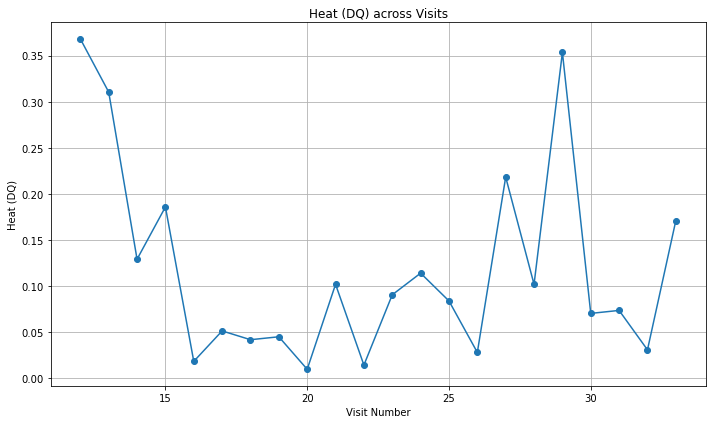

In [3]:
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered, n_components=3):
    energy_values = df_filtered["Energy Ei"].values.reshape(-1, 1)
    gmm = GaussianMixture(n_components=n_components)
    gmm.fit(energy_values)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000).reshape(-1, 1)
    pdf_values = np.exp(gmm.score_samples(energy_range))
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    from scipy.interpolate import interp1d
    return interp1d(energy_range.ravel(), pdf_values_normalized.ravel(), kind='linear', fill_value=0, bounds_error=False)

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 11
visit_end = 33

df = pd.read_excel(file_name, sheet_name=drug)
heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


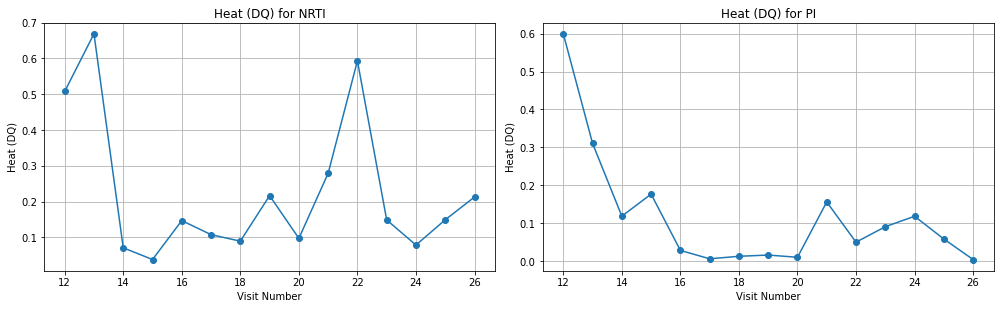

In [7]:


def plot_for_all_drugs(file_name, e_min, e_max, visit_start, visit_end):
    # Get the sheet names in the excel which should correspond to drug names
    xls = pd.ExcelFile(file_name)
    drug_names = xls.sheet_names

    plt.figure(figsize=(14, 8))
    
    for drug in drug_names:
        df = pd.read_excel(file_name, sheet_name=drug)
        
        # Calculate heat and entropy values
        heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)
        entropy_values = []
        for visit in range(visit_start, visit_end + 1):
            df_filtered = df[df['VISIT'] == visit]
            prob_func = get_probability_density_function(df_filtered)
            entropy_values.append(get_entropy_for_visit(prob_func, e_min, e_max))
        
        # Plotting heat values
        plt.subplot(2, len(drug_names), drug_names.index(drug) + 1)
        plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
        plt.title(f'Heat (DQ) for {drug}')
        plt.xlabel('Visit Number')
        plt.ylabel('Heat (DQ)')
        plt.grid(True)
        plt.tight_layout()

        # Plotting entropy values
        #plt.subplot(2, len(drug_names), len(drug_names) + drug_names.index(drug) + 1)
        #plt.plot(range(visit_start, visit_end + 1), entropy_values, marker='o', linestyle='-')
        #plt.title(f'Entropy for {drug}')
        #plt.xlabel('Visit Number')
        #plt.ylabel('Entropy')
        #plt.grid(True)
        #plt.tight_layout()
    
    plt.show()

file_name = "Normalised_Bootstrap_for_temp_no_NNRTI.xlsx"
e_min = 0.7
e_max = 1.5
visit_start = 11
visit_end = 26

plot_for_all_drugs(file_name, e_min, e_max, visit_start, visit_end)


In [1]:
pip install pymc3


     |████████████████████████████████| 872 kB 7.6 MB/s eta 0:00:01
     |████████████████████████████████| 1.7 MB 13.8 MB/s eta 0:00:01
     |████████████████████████████████| 1.8 MB 17.2 MB/s eta 0:00:01
     |████████████████████████████████| 115 kB 14.5 MB/s eta 0:00:01
     |████████████████████████████████| 1.0 MB 18.6 MB/s eta 0:00:01
     |████████████████████████████████| 43 kB 6.6 MB/s  eta 0:00:01
     |████████████████████████████████| 1.7 MB 18.2 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 20.7 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 14.4 MB/s eta 0:00:01
     |████████████████████████████████| 1.7 MB 20.2 MB/s eta 0:00:01
     |████████████████████████████████| 1.7 MB 16.5 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 20.5 MB/s eta 0:00:01
  Created wheel for theano-pymc: filename=Theano_PyMC-1.1.2-py3-none-any.whl size=1529963 sha256=c5ed194845e91de367cf3ed6b04f9a6f9d127360602fe2684e9ab43020ee7727
  Stored in 

In [1]:
import pymc3 as pm

def get_energy_probability_density_with_dpmm(file_name, drug, visit):
    # 1. Load the data for the specific drug
    df = pd.read_excel(file_name, sheet_name=drug)
    
    # 2. Filter the data based on the given VISIT ID
    df_filtered = df[df['VISIT'] == visit]
    
    energy_values = df_filtered["Energy Ei"].values

    with pm.Model() as model:
        alpha = pm.Gamma('alpha', 1., 1.)
        v = pm.Beta('v', 1., alpha, shape=len(energy_values))
        w = pm.Deterministic('w', v * tt.concatenate([[1], tt.extra_ops.cumprod(1 - v[:-1])]))
        component = pm.Categorical('component', w, shape=len(energy_values))

        tau = pm.Gamma("tau", 1.0, 1.0, shape=len(energy_values))
        lambda_ = pm.Uniform("lambda", 0, 5, shape=len(energy_values))
        mu = pm.Normal("mu", 0, tau=lambda_ * tau, shape=len(energy_values))
        obs = pm.Normal("obs", mu[component], tau=lambda_ * tau, observed=energy_values)

        trace = pm.sample(1000, tune=1500, chains=2)

    # Create callable function for p(E)
    def p(E):
        post_pred = pm.sample_posterior_predictive(trace, samples=500, model=model)
        val = np.exp(-0.5 * np.power(E - post_pred["obs"].mean(0), 2) / post_pred["obs"].var(0).mean())
        return val / val.sum()

    return p


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/deprecat/classic.py:215: FutureWarning: In v4.0, pm.sample will return an `arviz.InferenceData` object instead of a `MultiTrace` by default. You can pass return_inferencedata=True or return_inferencedata=False to be safe and silence this warning.
  return wrapped_(*args_, **kwargs_)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sds, means, w]


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 13 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 17 seconds.
The acceptance probability does not match the target. It is 0.7444314861897824, but should be close to 0.9. Try to increase the number of tu

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
There was 1 divergence after tuning. Increase `target_acc

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 14 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.4 for some parameters. 

...

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 13 seconds.
There were 6 divergences after tuning. Increase `target_accept` or reparameterize.
There was 1 divergence after tuning. Increase `target_acc

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.
There were 274 divergences after tuning. Increase `target_accept` or reparameterize.
The acceptance probability does not match the target. I

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
There was 1 divergence after tuning. Increase `target_acc

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 16 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
There were 2 divergences after tuning. Increase `target_acc

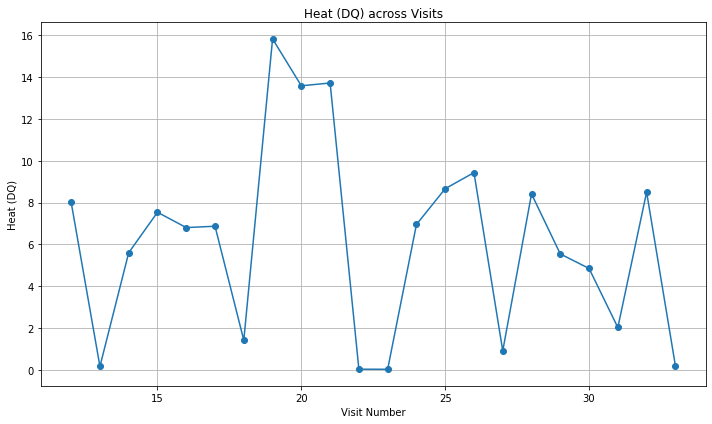

In [4]:


import pandas as pd
import numpy as np
import pymc3 as pm
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered):
    energy_values = df_filtered["Energy Ei"].values
    
    # Use DPMM to fit a mixture of Gaussians
    with pm.Model() as model:
        w = pm.Dirichlet('w', a=np.array([1, 1, 1]), shape=3)
        means = pm.Normal('means', mu=energy_values.mean(), sd=10, shape=3)
        sds = pm.HalfNormal('sds', sd=10, shape=3)
        obs = pm.NormalMixture('obs', w, mu=means, sd=sds, observed=energy_values)
        trace = pm.sample(1000, tune=2000, target_accept=0.9)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    post_pdfs = [np.exp(-0.5 * ((energy_range - trace['means'][:, i].mean())**2 / trace['sds'][:, i].mean()**2)) for i in range(3)]
    avg_w = np.mean(trace['w'], axis=0)
    pdf_values = sum([(avg_w[i] * post_pdfs[i]) for i in range(3)])
    pdf_values_normalized = pdf_values / max(pdf_values)
    

    
    from scipy.interpolate import interp1d
    return interp1d(energy_range, pdf_values_normalized, kind='linear', fill_value=0, bounds_error=False)

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/deprecat/classic.py:215: FutureWarning: In v4.0, pm.sample will return an `arviz.InferenceData` object instead of a `MultiTrace` by default. You can pass return_inferencedata=True or return_inferencedata=False to be safe and silence this warning.
  return wrapped_(*args_, **kwargs_)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sds, means, w]


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 26 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 35 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

...

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There were 10 divergences after tuning. Increase `target_accept` or reparameterize.
There were 8 divergences after tuning. Increase `target_

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
The acceptance probability does not match the target. It is

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 11 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
The acceptance probability does not match the target. It 

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There were 4 divergences after tuning. Increase `target_accept` or reparameterize.
There were 116 divergences after tuning. Increase `target

ValueError: x and y must have same first dimension, but have shapes (15,) and (16,)

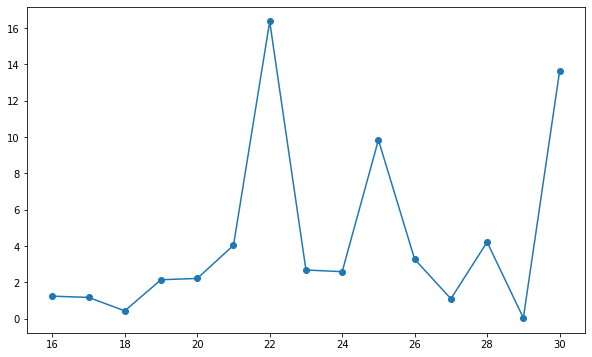

In [5]:

from scipy.interpolate import interp1d
import pandas as pd
import numpy as np
import pymc3 as pm
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered):
    energy_values = df_filtered["Energy Ei"].values
    
    # Use DPMM to fit a mixture of Gaussians
    with pm.Model() as model:
        w = pm.Dirichlet('w', a=np.array([1, 1, 1]), shape=3)
        means = pm.Normal('means', mu=energy_values.mean(), sd=10, shape=3)
        sds = pm.HalfNormal('sds', sd=10, shape=3)
        obs = pm.NormalMixture('obs', w, mu=means, sd=sds, observed=energy_values)
        trace = pm.sample(1000, tune=2000, target_accept=0.9)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    post_pdfs = [np.exp(-0.5 * ((energy_range - trace['means'][:, i].mean())**2 / trace['sds'][:, i].mean()**2)) for i in range(3)]
    avg_w = np.mean(trace['w'], axis=0)
    pdf_values = sum([(avg_w[i] * post_pdfs[i]) for i in range(3)])
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    significant_cluster_count = np.sum(avg_w > 0.01)
    
    return interp1d(energy_range, pdf_values_normalized, kind='linear', fill_value=0, bounds_error=False), significant_cluster_count

    

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []
    cluster_counts = []   # List to store the number of significant clusters for each visit

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func, cluster_count = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))
        cluster_counts.append(cluster_count)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values, cluster_counts

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values, cluster_counts = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-', label='Heat (DQ)')
plt.plot(range(visit_start + 1, visit_end + 1), cluster_counts, marker='x', linestyle='--', color='red', label='Number of Clusters')
plt.title('Heat (DQ) and Number of Clusters across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ) / Number of Clusters')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/deprecat/classic.py:215: FutureWarning: In v4.0, pm.sample will return an `arviz.InferenceData` object instead of a `MultiTrace` by default. You can pass return_inferencedata=True or return_inferencedata=False to be safe and silence this warning.
  return wrapped_(*args_, **kwargs_)
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sds, means, w]


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 21 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 24 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
There were 2 divergences after tuning. Increase `target_acc

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 17 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

...

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 16 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
There were 7 divergences after tuning. Increase `target_acc

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There were 3 divergences after tuning. Increase `target_accept` or reparameterize.
There were 4 divergences after tuning. Increase `target_a

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 13 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is smalle

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 12 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
There was 1 divergence after tuning. Increase `target_accep

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 15 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.
There were 308 divergences after tuning. Increase `target

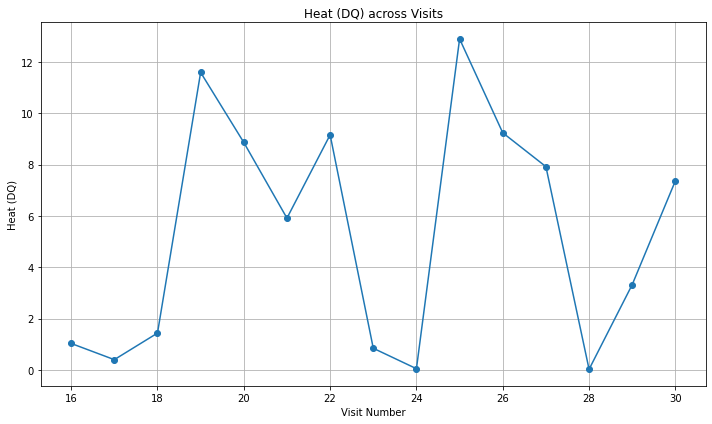

Visit Number | Number of Clusters
-------------------------------
     16      |         3        
     17      |         3        
     18      |         3        
     19      |         3        
     20      |         3        
     21      |         3        
     22      |         3        
     23      |         3        
     24      |         3        
     25      |         3        
     26      |         3        
     27      |         3        
     28      |         3        
     29      |         3        
     30      |         3        


In [115]:
import pandas as pd
import numpy as np
import pymc3 as pm
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered):
    energy_values = df_filtered["Energy Ei"].values
    
    # Use DPMM to fit a mixture of Gaussians
    with pm.Model() as model:
        w = pm.Dirichlet('w', a=np.array([1, 1, 1]), shape=3)
        means = pm.Normal('means', mu=energy_values.mean(), sd=10, shape=3)
        sds = pm.HalfNormal('sds', sd=10, shape=3)
        obs = pm.NormalMixture('obs', w, mu=means, sd=sds, observed=energy_values)
        trace = pm.sample(1000, tune=2000, target_accept=0.9)
    
    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    post_pdfs = [np.exp(-0.5 * ((energy_range - trace['means'][:, i].mean())**2 / trace['sds'][:, i].mean()**2)) for i in range(3)]
    
    avg_w = np.mean(trace['w'], axis=0)
    significant_clusters = sum([1 for weight in avg_w if weight > 0.05]) # Assuming a threshold of 5% for a cluster to be considered significant
    
    pdf_values = sum([(avg_w[i] * post_pdfs[i]) for i in range(3)])
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    from scipy.interpolate import interp1d
    return interp1d(energy_range, pdf_values_normalized, kind='linear', fill_value=0, bounds_error=False), significant_clusters

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []
    cluster_counts = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func, cluster_count = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))
        cluster_counts.append(cluster_count)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values, cluster_counts

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values, cluster_counts = calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end)


# Plotting heat values
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Displaying clusters per visit in a table format
print("Visit Number | Number of Clusters")
print("-------------------------------")
for visit, clusters in zip(range(visit_start + 1, visit_end + 1), cluster_counts):
    print(f"{visit:^12} | {clusters:^17}")


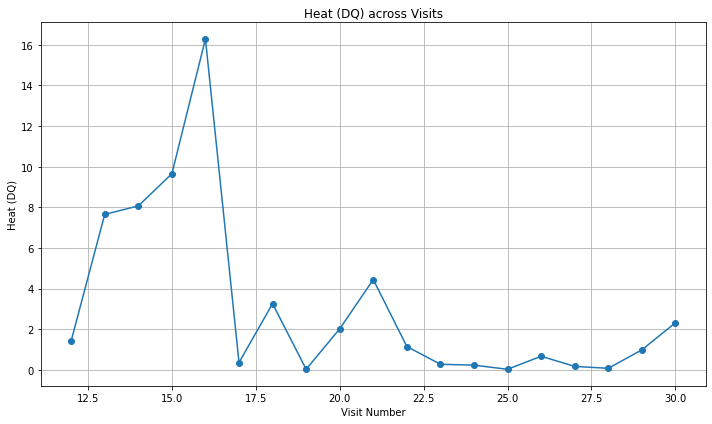

ValueError: All arrays must be of the same length

In [113]:
import pandas as pd
import numpy as np
import pymc3 as pm
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered):
    energy_values = df_filtered["Energy Ei"].values
    
    # Check for NaNs or infinites in the data
    assert not np.any(np.isnan(energy_values)), "NaN values detected in energy_values!"
    assert not np.any(np.isinf(energy_values)), "Infinite values detected in energy_values!"
    
    # Use DPMM to fit a mixture of Gaussians
    with pm.Model() as model:
        w = pm.Dirichlet('w', a=np.array([1, 1, 1]), shape=3)
        means = pm.Normal('means', mu=energy_values.mean(), sd=10, shape=3, testval=np.random.randn(3) * 10)
        sds = pm.HalfNormal('sds', sd=10, shape=3)
        obs = pm.NormalMixture('obs', w, mu=means, sd=sds, observed=energy_values)
        trace = pm.sample(1000, tune=2000, target_accept=0.9)

    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    post_pdfs = [np.exp(-0.5 * ((energy_range - trace['means'][:, i].mean())**2 / trace['sds'][:, i].mean()**2)) for i in range(3)]
    avg_w = np.mean(trace['w'], axis=0)
    pdf_values = sum([(avg_w[i] * post_pdfs[i]) for i in range(3)])
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    from scipy.interpolate import interp1d
    
    # Number of clusters is defined by the number of significant weights
    num_clusters = np.sum(avg_w > 0.1)

    return interp1d(energy_range, pdf_values_normalized, kind='linear', fill_value=0, bounds_error=False), num_clusters

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []
    cluster_counts = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func, cluster_count = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))
        cluster_counts.append(cluster_count)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values, cluster_counts

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 11
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values, cluster_counts = calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end)

# Plotting heat values
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Display clusters count
cluster_df = pd.DataFrame({
    'Visit Number': range(visit_start + 1, visit_end + 1),
    'Number of Clusters': cluster_counts
})
print(cluster_df)





In [12]:
import pandas as pd
import numpy as np
import pymc3 as pm
import matplotlib.pyplot as plt

def get_probability_density_function(df_filtered):
    energy_values = df_filtered["Energy Ei"].values
    
    # Check for NaNs or infinites in the data
    assert not np.any(np.isnan(energy_values)), "NaN values detected in energy_values!"
    assert not np.any(np.isinf(energy_values)), "Infinite values detected in energy_values!"
    
    # Define better priors
    sd_prior = np.std(energy_values)
    mean_prior = np.mean(energy_values)
    
    # Use DPMM to fit a mixture of Gaussians
    with pm.Model() as model:
        w = pm.Dirichlet('w', a=np.array([1, 1, 1]), shape=3)
        means = pm.Normal('means', mu=mean_prior, sd=sd_prior, shape=3, testval=np.array([mean_prior-0.5*sd_prior, mean_prior, mean_prior+0.5*sd_prior]))
        sds = pm.HalfNormal('sds', sd=sd_prior, shape=3, testval=np.array([sd_prior, sd_prior, sd_prior]))
        obs = pm.NormalMixture('obs', w, mu=means, sd=sds, observed=energy_values)
        trace = pm.sample(1000, tune=5000, target_accept=0.9, init='adapt_diag')



    energy_range = np.linspace(min(energy_values), max(energy_values), 1000)
    post_pdfs = [np.exp(-0.5 * ((energy_range - trace['means'][:, i].mean())**2 / trace['sds'][:, i].mean()**2)) for i in range(3)]
    avg_w = np.mean(trace['w'], axis=0)
    pdf_values = sum([(avg_w[i] * post_pdfs[i]) for i in range(3)])
    pdf_values_normalized = pdf_values / max(pdf_values)
    
    from scipy.interpolate import interp1d
    
    # Number of clusters is defined by the number of significant weights
    num_clusters = np.sum(avg_w > 0.1)

    return interp1d(energy_range, pdf_values_normalized, kind='linear', fill_value=0, bounds_error=False), num_clusters

def get_entropy_for_visit(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    probabilities = prob_func(energies)
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(prob_func, e_min, e_max):
    energies = np.linspace(e_min, e_max, 100)
    DE = (e_max - e_min) / 100
    shifted_energies = energies + DE
    return 0.5 * DE * np.sum(prob_func(energies) + prob_func(shifted_energies))

def calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []
    cluster_counts = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        prob_func, cluster_count = get_probability_density_function(df_filtered)
        temperatures.append(get_temperature(prob_func, e_min, e_max))
        entropies.append(get_entropy_for_visit(prob_func, e_min, e_max))
        cluster_counts.append(cluster_count)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values, cluster_counts

file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NNRTI"
e_min = 0.7
e_max = 1.5
visit_start = 11
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values, cluster_counts = calculate_heat_and_clusters(df, drug, e_min, e_max, visit_start, visit_end)

# Plotting heat values
plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Display clusters count
cluster_df = pd.DataFrame({
    'Visit Number': range(visit_start + 1, visit_end + 1),
    'Number of Clusters': cluster_counts
})
print(cluster_df)


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/deprecat/classic.py:215: FutureWarning: In v4.0, pm.sample will return an `arviz.InferenceData` object instead of a `MultiTrace` by default. You can pass return_inferencedata=True or return_inferencedata=False to be safe and silence this warning.
  return wrapped_(*args_, **kwargs_)
Auto-assigning NUTS sampler...
Initializing NUTS using adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sds, means, w]


/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 29 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is small

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 19 seconds.
There were 20 divergences after tuning. Increase `target_accept` or reparameterize.
The acceptance probability does not match the target. I

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 21 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is small

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 19 seconds.
The rhat statistic is larger than 1.4 for some parameters. The sampler did not converge.
The estimated number of effective samples is small

...

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 16 seconds.
The acceptance probability does not match the target. It is 0.8408989066179502, but should be close to 0.9. Try to increase the number of t

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 13 seconds.
The acceptance probability does not match the target. It is 0.8297151887777598, but should be close to 0.9. Try to increase the number of t

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 14 seconds.
There were 16 divergences after tuning. Increase `target_accept` or reparameterize.
The acceptance probability does not match the target. I

/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/_continuous_distns.py:624: RuntimeWarning: overflow encountered in _beta_ppf
  return _boost._beta_ppf(q, a, b)
Sampling 4 chains for 5_000 tune and 1_000 draw iterations (20_000 + 4_000 draws total) took 16 seconds.
The number of effective samples is smaller than 25% for some parameters.
/Users/rafaeldomenikos/opt/anaconda3/lib/python3.9/site-packages/n

SamplingError: Initial evaluation of model at starting point failed!
Starting values:
{'w_stickbreaking__': array([0., 0.]), 'means': array([nan, nan, nan]), 'sds_log__': array([nan, nan, nan])}

Initial evaluation results:
w_stickbreaking__   -1.5
means               -inf
sds_log__            NaN
obs                  0.0
Name: Log-probability of test_point, dtype: float64

In [3]:
def maxwell_boltzmann_probability(df, num_bins=5):
    energies = df['Energy Ei'].values
    
    # Histogram data
    counts, bin_edges = np.histogram(energies, bins=num_bins)
    
    # Get bin centers
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Normalize counts to get probabilities
    probabilities = counts / np.sum(counts)
    
    if np.sum(probabilities) == 0:
        print("Warning: The sum of probabilities is zero!")
        print("Energies:", energies)
    
    return bin_centers, probabilities

Probabilities for visit 15 : [0.01265823 0.85513361 0.04360056 0.08438819 0.00421941]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 16 : [0.01915709 0.84163474 0.04214559 0.08429119 0.01277139]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 17 : [0.01481481 0.85925926 0.09259259 0.02592593 0.00740741]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 18 : [0.00252525 0.01262626 0.89141414 0.08838384 0.00505051]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 19 : [0.70760234 0.1871345  0.02339181 0.07894737 0.00292398]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 20 : [0.01960784 0.83006536 0.10675381 0.03050109 0.0130719 ]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 21 : [0.8172043  0.08243728 0.07885305 0.01433692 0.00716846]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 22 : [0.77

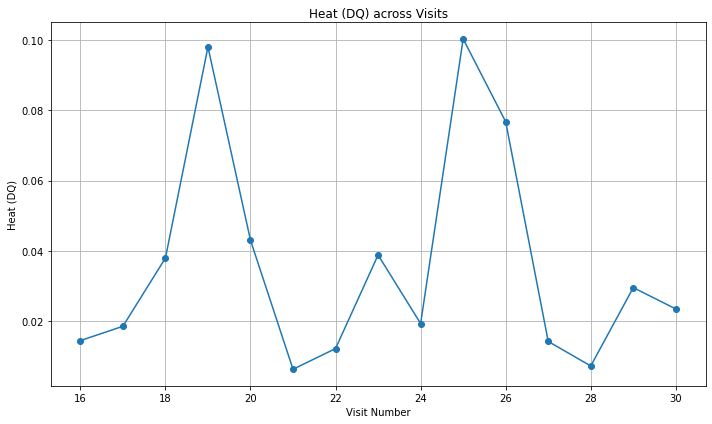

In [44]:
from scipy.interpolate import interp1d

def get_entropy_for_visit(bin_centers, probabilities):
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(bin_centers, probabilities):
    # Print the lengths of bin_centers and probabilities
    print("Length of bin_centers:", len(bin_centers))
    print("Length of probabilities:", len(probabilities))

    DE = np.mean(np.diff(bin_centers))
    shifted_centers = bin_centers + DE
    interp_probs = interp1d(bin_centers, probabilities, kind='linear', fill_value=0, bounds_error=False)
    return 0.5 * DE * np.sum(probabilities + interp_probs(shifted_centers))

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        if visit == 11:  # Add these lines
            print("Data for visit 11:")
            print(df_filtered)
        bin_centers, probabilities = maxwell_boltzmann_probability(df_filtered)
        print("Probabilities for visit", visit, ":", probabilities) 
        temperatures.append(get_temperature(bin_centers, probabilities))
        entropies.append(get_entropy_for_visit(bin_centers, probabilities))

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values



file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


Probabilities for visit 15 : [0.01278409 0.83380682 0.05184659 0.09659091 0.00497159]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 16 : [0.01008065 0.80913978 0.05376344 0.12163978 0.00537634]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 17 : [0.00284091 0.01988636 0.85511364 0.11079545 0.01136364]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 18 : [0.01136364 0.60606061 0.25757576 0.07954545 0.04545455]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 19 : [0.01041667 0.83333333 0.03125    0.11458333 0.01041667]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 20 : [0.00568182 0.31818182 0.52840909 0.02272727 0.125     ]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 21 : [0.01315789 0.80263158 0.05263158 0.11842105 0.01315789]
Length of bin_centers: 5
Length of probabilities: 5
Probabilities for visit 22 : [0.82

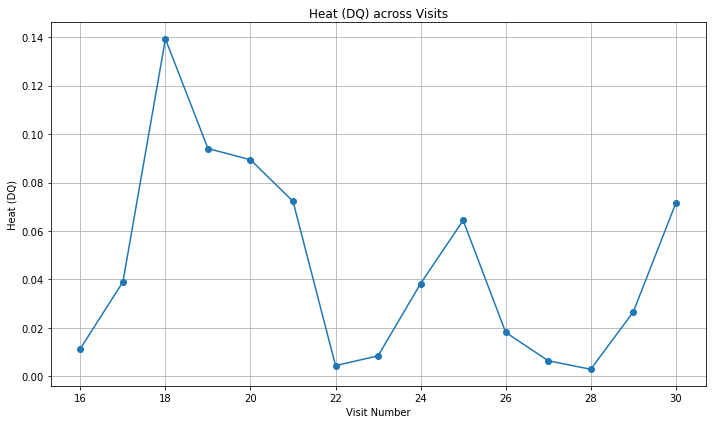

In [45]:
from scipy.interpolate import interp1d

def get_entropy_for_visit(bin_centers, probabilities):
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def get_temperature(bin_centers, probabilities):
    # Print the lengths of bin_centers and probabilities
    print("Length of bin_centers:", len(bin_centers))
    print("Length of probabilities:", len(probabilities))

    DE = np.mean(np.diff(bin_centers))
    shifted_centers = bin_centers + DE
    interp_probs = interp1d(bin_centers, probabilities, kind='linear', fill_value=0, bounds_error=False)
    return 0.5 * DE * np.sum(probabilities + interp_probs(shifted_centers))

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        if visit == 11:  # Add these lines
            print("Data for visit 11:")
            print(df_filtered)
        bin_centers, probabilities = maxwell_boltzmann_probability(df_filtered)
        print("Probabilities for visit", visit, ":", probabilities) 
        temperatures.append(get_temperature(bin_centers, probabilities))
        entropies.append(get_entropy_for_visit(bin_centers, probabilities))

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values



file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "NRTI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


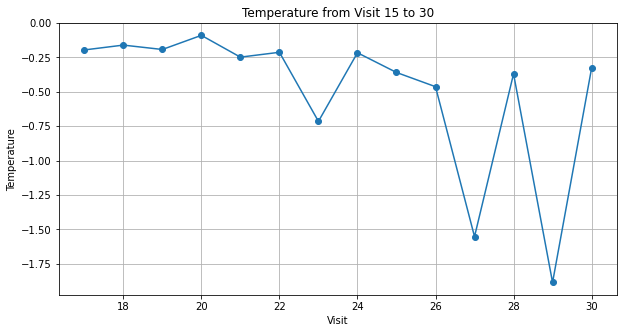

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
data = pd.read_excel('Normalised_Bootstrap_for_temp.xlsx', sheet_name='PI')

def gradient(beta, energies):
    weighted_energies = [E * np.exp(-beta * E) for E in energies]
    sum_weighted_energies = sum(weighted_energies)
    sum_exp_energies = sum([np.exp(-beta * E) for E in energies])
    mean_energy = sum(energies) / len(energies)
    
    return sum_weighted_energies - mean_energy * sum_exp_energies

def gradient_descent(energies, learning_rate=0.001, num_iterations=1000):
    beta = 1  # initial guess
    for _ in range(num_iterations):
        grad = gradient(beta, energies)
        beta += learning_rate * grad
    return beta

# Extract temperatures for visits 15 to 30
visits = list(range(17, 31))
temperatures = []

for visit in visits:
    visit_data = data[data['VISIT'] == visit]
    energies = visit_data['Energy Ei'].values
    beta_optimized = gradient_descent(energies)
    temperature = 1 / (beta_optimized)
    temperatures.append(temperature)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(visits, temperatures, marker='o', linestyle='-')
plt.xlabel("Visit")
plt.ylabel("Temperature")
plt.title("Temperature from Visit 15 to 30")
plt.grid(True)
plt.show()


In [96]:
import numpy as np

# Define the objective function and its gradient
def compute_probabilities(alpha, beta, energies):
    exponentials = np.exp(-alpha - beta * energies)
    Z = np.sum(exponentials)
    probabilities = exponentials / Z
    return probabilities, Z

def compute_gradients(alpha, beta, energies, probabilities, Z):
    grad_alpha = len(energies) - np.sum(probabilities)
    grad_beta = np.dot(energies, probabilities) - np.dot(energies, probabilities**2)
    return grad_alpha, grad_beta

# Gradient Descent to find alpha and beta
def gradient_descent(energies, learning_rate=0.01, max_iter=1000, tol=1e-6):
    alpha = 1.0
    beta = -10
    
    for iteration in range(max_iter):
        Ni = np.exp(-alpha - beta * energies)
        Zi = np.sum(Ni)
        Ei = np.sum(Ni * energies)

        # Safety checks:
        if Zi <= 0:
            print(f"Zi became non-positive: {Zi} at iteration {iteration}")
            break
        if Ei <= 0:
            print(f"Ei became non-positive: {Ei} at iteration {iteration}")
            break

        # Compute gradients
        dL_dalpha = len(energies) - Zi
        dL_dbeta = Ei - energies.sum()

        # Update alpha and beta
        alpha += learning_rate * dL_dalpha
        beta += learning_rate * dL_dbeta

        # Check for convergence
        if abs(dL_dalpha) < tol and abs(dL_dbeta) < tol:
            break

    return alpha, beta





Zi became non-positive: 0.0 at iteration 1
For visit 13: Alpha = -291234.2535550953, Beta = 425136.92059765966
Zi became non-positive: 0.0 at iteration 1
For visit 14: Alpha = -75411.05783065161, Beta = 100562.14295727533
Zi became non-positive: 0.0 at iteration 1
For visit 15: Alpha = -884048.0711175202, Beta = 1425438.2976630798
Zi became non-positive: 0.0 at iteration 1
For visit 16: Alpha = -1722113.58378612, Beta = 2870036.554567315
Zi became non-positive: 0.0 at iteration 1
For visit 17: Alpha = -1877570.8837180883, Beta = 3534102.7799733444
For visit 18: Alpha = nan, Beta = nan
Zi became non-positive: 0.0 at iteration 1
For visit 19: Alpha = -357037.39187870227, Beta = 542577.400484761
Zi became non-positive: 0.0 at iteration 1
For visit 20: Alpha = -2405936.754514954, Beta = 4374098.921332741
Zi became non-positive: 0.0 at iteration 1
For visit 21: Alpha = -760270.3529133409, Beta = 1331317.6511377334
Zi became non-positive: 0.0 at iteration 1
For visit 22: Alpha = -1148859.607

/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_1256/2603569974.py:21: RuntimeWarning: overflow encountered in exp
  Ni = np.exp(-alpha - beta * energies)
/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_1256/2603569974.py:21: RuntimeWarning: invalid value encountered in subtract
  Ni = np.exp(-alpha - beta * energies)


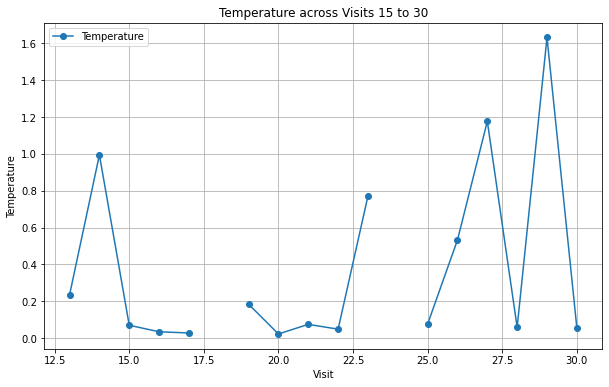

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_excel('Normalised_Bootstrap_for_temp.xlsx', sheet_name='PI')

# Function definitions from previous cells go here...

temperatures = []
visits_range = range(13, 31)  # 15 to 30 inclusive

for visit in visits_range:
    energies_for_visit = data[data['VISIT'] == visit]['Energy Ei'].values
    alpha_opt, beta_opt = gradient_descent(energies_for_visit)
    
    print(f"For visit {visit}: Alpha = {alpha_opt}, Beta = {beta_opt}")
    
    if beta_opt == 0:
        print(f"Warning: Beta for visit {visit} is zero!")
        temp = np.inf
    else:
        temp = 1 / beta_opt
    
    temperatures.append(temp*10**5)

# Remaining plot code...


# Plot
plt.figure(figsize=(10, 6))
plt.plot(visits_range, temperatures, '-o', label='Temperature')
plt.xlabel('Visit')
plt.ylabel('Temperature')
plt.title('Temperature across Visits 15 to 30')
plt.legend()
plt.grid(True)
plt.show()


Zi became non-positive: 0.0 at iteration 1
For visit 13: Alpha = -247739.79751197275, Beta = 379367.7308737742
For visit 14: Alpha = nan, Beta = nan
Zi became non-positive: 0.0 at iteration 1
For visit 15: Alpha = -2785389.4111313713, Beta = 4626522.101505288
For visit 16: Alpha = nan, Beta = nan
For visit 17: Alpha = nan, Beta = nan
For visit 18: Alpha = nan, Beta = nan
Zi became non-positive: 0.0 at iteration 1
For visit 19: Alpha = -209152.3431049592, Beta = 341421.86077561235
For visit 20: Alpha = nan, Beta = nan
Zi became non-positive: 0.0 at iteration 1
For visit 21: Alpha = -253293.9785331425, Beta = 402444.8180919853
Zi became non-positive: 0.0 at iteration 1
For visit 22: Alpha = -180429.9051720412, Beta = 297171.4700966433
Zi became non-positive: 0.0 at iteration 1
For visit 23: Alpha = -1662605.7508076457, Beta = 3135506.0244159997
Zi became non-positive: 0.0 at iteration 1
For visit 24: Alpha = -106464.47879987817, Beta = 148327.5983111528
For visit 25: Alpha = nan, Beta = 

/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_1256/2603569974.py:21: RuntimeWarning: overflow encountered in exp
  Ni = np.exp(-alpha - beta * energies)
/var/folders/j8/z8l9f8wj7zj_tdy05ph1k2s80000gn/T/ipykernel_1256/2603569974.py:21: RuntimeWarning: invalid value encountered in subtract
  Ni = np.exp(-alpha - beta * energies)


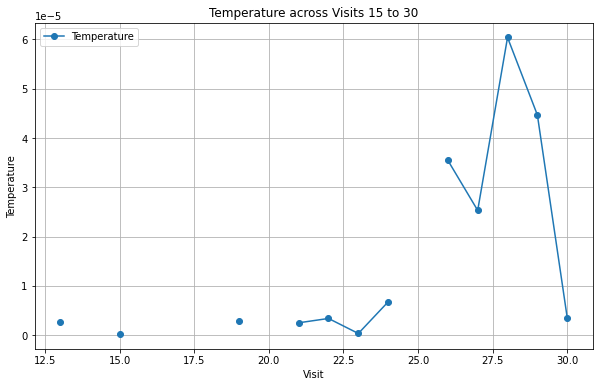

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = pd.read_excel('Normalised_Bootstrap_for_temp.xlsx', sheet_name='NRTI')

# Function definitions from previous cells go here...

temperatures = []
visits_range = range(13, 31)  # 15 to 30 inclusive

for visit in visits_range:
    energies_for_visit = data[data['VISIT'] == visit]['Energy Ei'].values
    alpha_opt, beta_opt = gradient_descent(energies_for_visit)
    
    print(f"For visit {visit}: Alpha = {alpha_opt}, Beta = {beta_opt}")
    
    if beta_opt == 0:
        print(f"Warning: Beta for visit {visit} is zero!")
        temp = np.inf
    else:
        temp = 1 / beta_opt
    
    temperatures.append(temp)

# Remaining plot code...


# Plot
plt.figure(figsize=(10, 6))
plt.plot(visits_range, temperatures, '-o', label='Temperature')
plt.xlabel('Visit')
plt.ylabel('Temperature')
plt.title('Temperature across Visits 15 to 30')
plt.legend()
plt.grid(True)
plt.show()


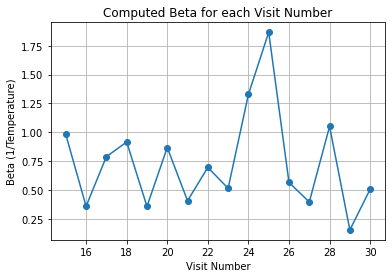

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

# Load the Excel file
file_path = "Normalised_bootstrap_for_temp.xlsx"
sheet_name = "PI"
df = pd.read_excel(file_path, sheet_name=sheet_name)

def compute_beta(visit_num):
    # Filter the data for the specific visit number
    visit_data = df[df['VISIT'] == visit_num]
    
    # Sort the energies
    sorted_energies = sorted(visit_data['Energy Ei'])
    
    # Group energies within 5% of each other
    grouped_energies = []
    current_group = [sorted_energies[0]]
    
    for energy in sorted_energies[1:]:
        if abs(energy - current_group[-1]) / current_group[-1] <= 0.05:
            current_group.append(energy)
        else:
            grouped_energies.append(current_group)
            current_group = [energy]
    grouped_energies.append(current_group)
    
    # Compute the representative energy and count for each group
    energies = [np.mean(group) for group in grouped_energies]
    counts = [len(group) for group in grouped_energies]

    def equation(beta):
        term1 = np.sum(np.log(counts))
        term2 = len(energies) * np.sum(np.exp(-beta * np.array(energies)))
        term3 = np.sum(energies)
        return (term1 - term2) / term3

    # Solve for beta using Newton-Raphson method
    beta = newton(equation, x0=1.0)
    return beta

# Compute beta for each visit number from 15 to 30
visit_numbers = range(15, 31)
betas = []

for visit_num in visit_numbers:
    beta = np.abs(compute_beta(visit_num))
    betas.append(beta)

# Plot the computed beta values
plt.plot(visit_numbers, betas, marker='o')
plt.xlabel('Visit Number')
plt.ylabel('Beta (1/Temperature)')
plt.title('Computed Beta for each Visit Number')
plt.grid(True)
plt.show()


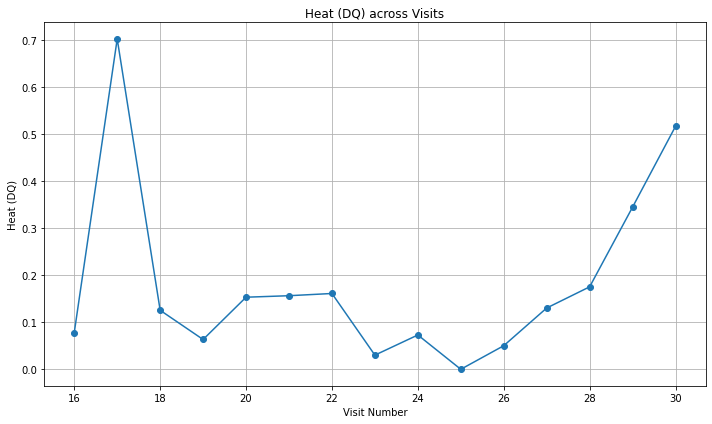

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

# Load the Excel file
file_path = "Normalised_bootstrap_for_temp.xlsx"
sheet_name = "PI"
df = pd.read_excel(file_path, sheet_name=sheet_name)

def get_temperature_and_entropy(visit_num):
    visit_data = df[df['VISIT'] == visit_num]
    sorted_energies = sorted(visit_data['Energy Ei'])
    
    grouped_energies = []
    current_group = [sorted_energies[0]]
    for energy in sorted_energies[1:]:
        if abs(energy - current_group[-1]) / current_group[-1] <= 0.05:
            current_group.append(energy)
        else:
            grouped_energies.append(current_group)
            current_group = [energy]
    grouped_energies.append(current_group)
    
    energies = [np.mean(group) for group in grouped_energies]
    counts = [len(group) for group in grouped_energies]

    def equation(beta):
        term1 = np.sum(np.log(counts))
        term2 = len(energies) * np.sum(np.exp(-beta * np.array(energies)))
        term3 = np.sum(energies)
        return (term1 - term2) / term3

    beta = newton(equation, x0=1.0)
    temperature = 1/beta
    
    probabilities = np.array(counts) / np.sum(counts)
    entropy = -np.sum(probabilities * np.log(probabilities))
    
    return temperature, entropy

def calculate_heat(df, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        temperature, entropy = get_temperature_and_entropy(visit)
        temperatures.append(temperature)
        entropies.append(entropy)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

visit_start = 15
visit_end = 30

heat_values = calculate_heat(df, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


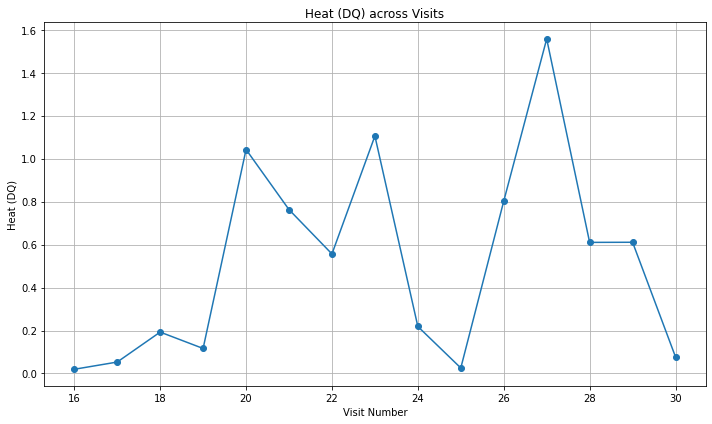

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

# Load the Excel file
file_path = "Normalised_bootstrap_for_temp.xlsx"
sheet_name = "NRTI"
df = pd.read_excel(file_path, sheet_name=sheet_name)

def get_temperature_and_entropy(visit_num):
    visit_data = df[df['VISIT'] == visit_num]
    sorted_energies = sorted(visit_data['Energy Ei'])
    
    grouped_energies = []
    current_group = [sorted_energies[0]]
    for energy in sorted_energies[1:]:
        if abs(energy - current_group[-1]) / current_group[-1] <= 0.05:
            current_group.append(energy)
        else:
            grouped_energies.append(current_group)
            current_group = [energy]
    grouped_energies.append(current_group)
    
    energies = [np.mean(group) for group in grouped_energies]
    counts = [len(group) for group in grouped_energies]

    def equation(beta):
        term1 = np.sum(np.log(counts))
        term2 = len(energies) * np.sum(np.exp(-beta * np.array(energies)))
        term3 = np.sum(energies)
        return (term1 - term2) / term3

    beta = newton(equation, x0=1.0)
    temperature = 1/beta
    
    probabilities = np.array(counts) / np.sum(counts)
    entropy = -np.sum(probabilities * np.log(probabilities))
    
    return temperature, entropy

def calculate_heat(df, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        temperature, entropy = get_temperature_and_entropy(visit)
        temperatures.append(temperature)
        entropies.append(entropy)

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values

visit_start = 15
visit_end = 30

heat_values = calculate_heat(df, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()


Probabilities for visit 15 : [0.01265823 0.85513361 0.04360056 0.08438819 0.00421941]
Probabilities for visit 16 : [0.01915709 0.84163474 0.04214559 0.08429119 0.01277139]
Probabilities for visit 17 : [0.01481481 0.85925926 0.09259259 0.02592593 0.00740741]
Probabilities for visit 18 : [0.00252525 0.01262626 0.89141414 0.08838384 0.00505051]
Probabilities for visit 19 : [0.70760234 0.1871345  0.02339181 0.07894737 0.00292398]
Probabilities for visit 20 : [0.01960784 0.83006536 0.10675381 0.03050109 0.0130719 ]
Probabilities for visit 21 : [0.8172043  0.08243728 0.07885305 0.01433692 0.00716846]
Probabilities for visit 22 : [0.77380952 0.11111111 0.09126984 0.01190476 0.01190476]
Probabilities for visit 23 : [0.52777778 0.3125     0.04861111 0.01388889 0.09722222]
Probabilities for visit 24 : [0.00383142 0.00766284 0.37931034 0.49808429 0.11111111]
Probabilities for visit 25 : [0.01666667 0.84444444 0.07222222 0.05555556 0.01111111]
Probabilities for visit 26 : [0.60233918 0.22807018 0.

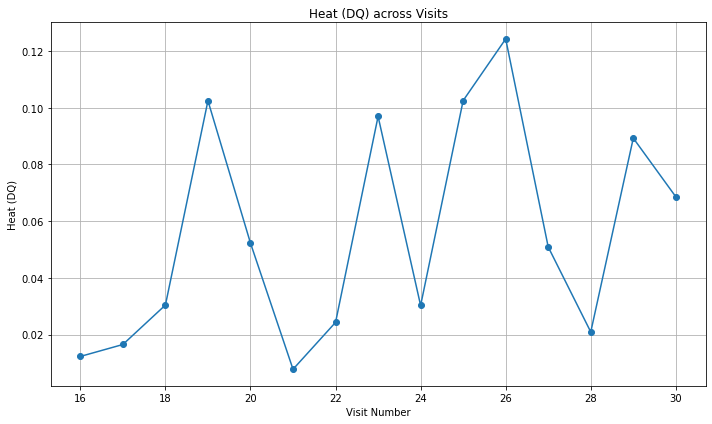

In [8]:
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import fsolve
import numpy as np
import matplotlib.pyplot as plt


def get_entropy_for_visit(bin_centers, probabilities):
    non_zero_probs = probabilities[probabilities > 1e-10]
    return -np.sum(non_zero_probs * np.log(non_zero_probs))

def temperature_equation(T, energies):
    k = len(energies)
    numerator = 1.0 - k * np.sum(np.exp(-1.0/T * energies))
    denominator = np.sum(energies)
    return numerator/denominator

def get_temperature(energies):
    # Initial guess for T, can be adjusted based on your data range
    initial_guess = 1.0  
    temperature, = fsolve(lambda T: temperature_equation(T, energies) + 1/T, initial_guess)
    return temperature

def calculate_heat(df, drug, e_min, e_max, visit_start, visit_end):
    temperatures = []
    entropies = []
    heat_values = []

    for visit in range(visit_start, visit_end + 1):
        df_filtered = df[df['VISIT'] == visit]
        if visit == 11:  # Add these lines
            print("Data for visit 11:")
            print(df_filtered)
        bin_centers, probabilities = maxwell_boltzmann_probability(df_filtered)
        print("Probabilities for visit", visit, ":", probabilities) 
        temperatures.append(get_temperature(df_filtered["Energy Ei"].values))
        entropies.append(get_entropy_for_visit(bin_centers, probabilities))

    for i in range(1, len(temperatures)):
        T2 = temperatures[i]
        T1 = temperatures[i-1]
        entropy_diff = np.abs(entropies[i] - entropies[i-1])
        DQ = (np.abs(T1+T2))/2 * entropy_diff
        heat_values.append(DQ)
    
    return heat_values



file_name = "Normalised_Bootstrap_for_temp.xlsx"
drug = "PI"
e_min = 0.7
e_max = 1.5
visit_start = 15
visit_end = 30

df = pd.read_excel(file_name, sheet_name=drug)
heat_values = calculate_heat(df, drug, e_min, e_max, visit_start, visit_end)

plt.figure(figsize=(10, 6))
plt.plot(range(visit_start + 1, visit_end + 1), heat_values, marker='o', linestyle='-')
plt.title('Heat (DQ) across Visits')
plt.xlabel('Visit Number')
plt.ylabel('Heat (DQ)')
plt.grid(True)
plt.tight_layout()
plt.show()
